# 基于机器学习的建筑点云语义分割、构件分组与 Rhino 网格重建

**项目成员：樊奕翔｜学号：[学号已移除]｜专业：建筑学｜单人项目**

**工作分工：**樊奕翔负责建筑应用需求、选题、方案取舍与最终成果审阅、课堂讲解；AI 协助资料检索、代码实现、排错、自动化测试和实验整理。自动化检查由 AI 执行，不代替本人对代码和结果的理解。本人讲解准备与复核情况须在提交前补充。

**分数分配：**本人承担全部成员工作，取得项目个人评分，无组内加减分或分数调配。

**成果：**将彩色室内扫描点云变成带语义和候选组的点云，允许用户审阅，再生成贴合实测点的彩色网格并导出 Rhino 3DM。输出是可编辑 Mesh。

**提交方式：**仅使用本 Notebook 展示；正文、代码、图表、真实结果、抽样数据和 AI 协作记录保存在本文件。不准备 PPT。完整扫描数据、模型权重和 3DM 是大体积运行依赖，获取与校验代码收录于附录。结课后一周另交实验报告。


> **GitHub 公开版本**：已移除学号、本机用户路径和内嵌原始点云样本。输出为课程实验的历史记录；重新执行时才产生本次结果。需自行获取 S3DIS 并生成预测，才能进行真实点云抽样。原始课堂版保留在作者本机。


## 阅读与现场操作

主线按“需求 → 数据 → 预处理 → 建模与迭代 → 测试 → 比较与专业解释 → AI 总结”展开。

| 老师要求 | 本文件位置 |
|---|---|
| 1. 全部内容保存 Notebook | 本文、嵌入资源、附录完整源码 |
| 2. 首页身份、分工、分数 | 第一格单元格 |
| 3. 需求、ML 合理性、工程选型 | 第 1 节 |
| 4. 真实数据与可比较方法、文献 | 第 2、6、8 节 |
| 5. 预处理、代码与结果 | 第 3 节及附录 |
| 6. 建模与迭代、代码与结果 | 第 4 节及附录 |
| 7. 测试代码、样例、结果 | 第 5 节 |
| 8. 对比与专业解释 | 第 6 节 |
| 9. AI 编程、测试、对话、决策和价值 | 第 7 节 |

**运行：**在项目文件夹打开本 Notebook，选择 `PointCloud Course (Python 3.12)` 内核。默认在本地依赖齐备时复跑小型 RF、单房间网络推理、网格参数实验、指标与抽样检查；不会启动客户端、下载完整数据或覆盖历史结果。需快速浏览时可关闭三个 `RUN_...` 开关。每次启动内核先运行本节初始化。

**可携带性：**即使只保留本 Notebook，也能读取嵌入的报告、图片、23 个房间的真实抽样点并重算抽样指标；全房间推理与 3DM 回读仍需原始数据、权重及对应软件依赖。离线样本结果会明确标注，不冒充全场景评估。

In [1]:
from pathlib import Path
import ast, base64, hashlib, io, json, platform, sys, types, time
import importlib.metadata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, Image, Code
import nbformat

NOTEBOOK_NAME = '建筑点云分割与网格重建_课程展示.ipynb'
candidates = [Path.cwd(), Path.cwd()/'pointcloud_course_project']
ROOT = next((p for p in candidates if (p/NOTEBOOK_NAME).exists()), None)
if ROOT is None:
    raise FileNotFoundError('请把工作目录切换到本 Notebook 所在文件夹，再重新运行。')
doc = nbformat.read(ROOT/NOTEBOOK_NAME, as_version=4)
ASSETS = doc.metadata['course_assets']
SOURCE_FILES = {}
for cell in doc.cells:
    path = cell.metadata.get('source_path')
    if path:
        # 从附录中的字符串赋值读取原文，不自动运行 GUI、下载或构建入口。
        SOURCE_FILES[path] = ast.literal_eval(ast.parse(cell.source).body[0].value)
def load_module(path, name=None):
    name = name or Path(path).stem
    module = types.ModuleType(name)
    module.__file__ = str(ROOT/path)
    sys.modules[name] = module
    exec(compile(SOURCE_FILES[path], module.__file__, 'exec'), module.__dict__)
    return module
def evidence(path): return ASSETS['reports'][path]
def show_image(path, width=1050):
    display(Image(data=base64.b64decode(ASSETS['images'][path]), width=width))
def sample_data(room):
    raw=ROOT/'data/full_processed'/f'Area_3_{room}.npz'
    pred=ROOT/'results/area3_batch'/f'Area_3_{room}'/'segmentation.npz'
    if not raw.exists() or not pred.exists(): return None
    with np.load(raw,allow_pickle=False) as a, np.load(pred,allow_pickle=False) as b:
        assert np.array_equal(a['xyz'],b['xyz']) and np.array_equal(a['rgb'],b['rgb'])
        return dict(xyz=a['xyz'].copy(),rgb=a['rgb'].copy(),truth=a['semantic'].copy(),
                    pred=b['semantic'].copy(),group=b['group_id'].copy(),index=np.arange(len(a['xyz'])))

def metric(truth, pred):
    truth=np.asarray(truth, dtype=np.int64); pred=np.asarray(pred, dtype=np.int64)
    assert truth.shape == pred.shape and truth.size > 0
    assert np.all((truth>=0)&(truth<13)) and np.all((pred>=0)&(pred<13))
    cm=np.bincount(truth*13+pred, minlength=169).reshape(13,13)
    union=cm.sum(0)+cm.sum(1)-cm.diagonal()
    iou=np.divide(cm.diagonal(),union,out=np.full(13,np.nan),where=union>0)
    return dict(accuracy=float(np.trace(cm)/cm.sum()), miou=float(np.nanmean(iou)), iou=iou, cm=cm)
CLASSES = evidence('data/full_processed/manifest.json')['classes']
print('项目目录：', ROOT)
print('完整源码文件数：',len(SOURCE_FILES),'；嵌入真实抽样场景数：',len(ASSETS['samples']))
print('Python:',platform.python_version(),'；系统：',platform.system())

项目目录： <USER_HOME>\Documents\ChatGPT\fyx\pointcloud_course_project
完整源码文件数： 34 ；嵌入真实抽样场景数： 23
Python: 3.12.10 ；系统： Windows


## 1. 建筑需求、机器学习任务与工程选择

既有建筑测绘、室内改造和存量空间设计常获得大量离散扫描点。直接在 Rhino 中逐点辨认墙、地面、门窗与家具，再重新建模，操作繁琐。本项目尝试把扫描转成可审阅的空间构件候选组，并重建测量点支持的网格，为后续设计提供基础。

**机器学习任务是逐点语义分类：**输入 XYZ 与 RGB，输出 13 类之一。真实标注提供监督依据；局部空间形状、颜色和邻域结构与构件类别存在统计关系，适合采用已训练的点云网络。RANSAC 可以寻找平面，但单靠平面不能判断它是墙还是桌面。

| 环节 | 方法 | 输出与责任边界 |
|---|---|---|
| 语义分类 | 预训练 RandLA-Net；本地训练 RF 作基线 | 每点类别与最大 softmax 分数；分数未经正确率校准 |
| 几何分组 | 类别内 RANSAC + DBSCAN | 候选组；不是学习得到的实例分割真值 |
| 人工审阅 | 分组选择、改名/类别、合并、拆分、撤销 | 用户保留决策权；自动结果均需审阅 |
| 表面重建 | Ball Pivoting + 长边/点支持过滤 | 贴合实测点的 Mesh，保留缺测处 |
| 交付 | 独立 Windows 客户端、原生 3DM | Rhino 中按组编辑、隐藏和继续建模 |

**约束与选型：当前采用 CPU 推理以复用现有环境，不从零训练大型网络。Open3D 与 PyTorch 编译扩展不匹配时，保留官方网络和权重，用 NumPy 体素与 SciPy 邻域查询实现数据操作。此

使用 S3DIS 室内 RGB 场景验证；未覆盖建筑外立面、无色激光扫描及任意设备域迁移。客户端单次上限 1000 万点，大扫描应先按房间切分。三角网格可编辑，但仍需后续拟合才成为规则建筑曲面/实体。

In [2]:
packages=['numpy','scipy','scikit-learn','torch','open3d','rhino3dm','PySide6-Essentials','pandas','nbformat','nbclient']
rows=[]
for name in packages:
    try: version=importlib.metadata.version(name)
    except importlib.metadata.PackageNotFoundError: version='当前内核未安装'
    rows.append({'依赖':name,'当前环境版本':version})
display(pd.DataFrame(rows))

,依赖,当前环境版本
0,numpy,2.4.4
1,scipy,1.17.1
2,scikit-learn,1.8.0
3,torch,2.11.0
4,open3d,0.20.0
5,rhino3dm,8.35.0
6,PySide6-Essentials,6.12.0
7,pandas,3.1.1
8,nbformat,5.11.1
9,nbclient,0.11.0


## 2. 数据来源、实验划分与可追溯性

采用 **S3DIS v1.2 Aligned Version**，包含 6 个区域、272 个室内房间、273,608,339 个转换后有效点；类别涵盖天花、地面、墙、梁、柱、窗、门、桌、椅、沙发、书架、板面、杂项。它是多场景室内建筑数据，不等同于一栋建筑内外完整扫描。

| 数据用途 | 范围 | 使用限制 |
|---|---|---|
| 本地 RF 训练、推理适配开发 | Area 1 / office_1，884,955 点 | 训练规模较小 |
| 初始同场景方案对比 | Area 3 / office_1，759,861 点 | 开发期间已看过结果，不是全新盲测 |
| 扩展语义评估 | Area 3 全部 23 房间，18,662,173 点 | 固定批处理流程；不是全 S3DIS 六折成绩 |
| 客户端输入到 3DM 验证 | Area 3 / office_2，739,209 点，去标签 PLY | 新版局部坐标流程，独立报告 |

官方固定配置将 Area 3 设为测试区。本项目未本地训练或微调 RandLA-Net，未审计完整预训练历史；标签在推理之后才用于计分。随机森林使用 Area 1 的标签训练。不能把 272 个房间都称为独立测试集。

数据来源为 Stanford 原始研究，下载采用 Hugging Face 的 cminst/S3DIS 镜像。完整 ZIP 校验 SHA-256，解压成员 CRC 全部检查。转换时排除并记录 1 条含 NUL 的损坏行；`stairs` 按固定 Open3D 数据适配约定归入 `clutter`。原始数据的出处与使用条件保留，不因镜像标签而另行声称授权。

In [3]:
manifest=evidence('data/full_processed/manifest.json')
archive=evidence('data/downloads/provenance.json')
extract=evidence('data/full_raw/extraction_verified.json')
provenance=evidence('weights/provenance.json')
from collections import Counter
display(pd.DataFrame(sorted(Counter(r['room'].split('/')[0] for r in manifest['rooms']).items()),columns=['区域','房间数']))
print('有效点数：',f"{manifest['total_points']:,}",'排除损坏行：',manifest['total_rejected_rows'])
print('数据 SHA-256：',archive['sha256'])
print('ZIP 全部成员 CRC 校验：',extract['all_member_crc_verified'])
print('上游代码版本：',provenance['upstream_commit'])
print('权重 SHA-256：',provenance['checkpoint_sha256'])
weight=ROOT/'weights/randlanet_s3dis.pth'
if weight.exists():
    assert hashlib.sha256(weight.read_bytes()).hexdigest()==provenance['checkpoint_sha256']
    print('本次重新检查本地权重：PASS')
else: print('本地无权重：可查看嵌入结果，重新推理前须按来源下载权重。')

,区域,房间数
0,Area_1,44
1,Area_2,40
2,Area_3,23
3,Area_4,49
4,Area_5,68
5,Area_6,48


有效点数： 273,608,339 排除损坏行： 1
数据 SHA-256： f16db73310983e6b4df9b3d5290d20315e0cdf56c14f0d795f96d372378fce94
ZIP 全部成员 CRC 校验： True
上游代码版本： a3d0f7a51d4eef0b94b9000a7d74af05e2d54c4f
权重 SHA-256： b0c5c8148d363c10b7fd33105df5e8b7efeecaa0674650c4761466a94e4d4c87
本次重新检查本地权重：PASS


## 3. 数据预处理：步骤、实现与结果

1. 读取 XYZ/RGB，检查形状、数量、有效值、颜色范围；客户端剔除非有限值并计数。缺少颜色默认拒绝，实验性中性色补色不保证效果。
2. 根据用户指定的单位与竖直轴，构造米制、Z 向上的推理坐标。原始位置保留，用于追溯与导出转换。
3. **新版客户端**再减去 XY 中位数与最低 Z，避免测绘全局大坐标损失精度。**历史 Area 3 批处理未采用此局部原点步骤**，两套结果分别报告。
4. 使用 0.04 m 体素平均坐标和 RGB，保存逆映射；网络使用 40,960 点的空间邻域块。各块 XY 居中、按固定顺序构造多层 kNN。颜色按固定模型适配规则传入，不擅自更改为另一范围。
5. 输出体素类别后通过逆映射回每个原始点，保留每点类别、分数、组号。语义阶段的采样与网格阶段的 0.02 m 采样是两件不同的事。

以下从 Notebook 附录加载真实处理函数，并在嵌入真实样本上演示体素化。样本过稀，压缩率不代表整间房间；后续全房间记录给出真实规模。

In [4]:
network_module=load_module('randlanet_portable.py')
pipeline=load_module('segmentation_pipeline.py')
grouping=load_module('semantic_groups.py')
demo=sample_data('office_2')
if demo is not None:
    p,c,inverse=pipeline.voxel_average(demo['xyz'],demo['rgb'],grid=.04)
    assert len(inverse)==len(demo['xyz']) and inverse.min()>=0 and inverse.max()<len(p)
    print('嵌入真实抽样点：',len(demo['xyz']),'体素数：',len(p),'逆映射长度：',len(inverse))
else: print('公开版未附带点云：请按 README 获取数据并生成预测后运行预处理演示。')
client_report=evidence('pointcloud_client/qa/packaged_mesh_1794391633/report.json')
print('完整客户端样例：',client_report['input']['point_count'],'点 →',client_report['prediction']['coarse_points'],'体素')
print('局部推理原点（米）：',client_report['input']['inference_origin_m'])

嵌入真实抽样点： 6000 体素数： 5631 逆映射长度： 6000
完整客户端样例： 739209 点 → 52050 体素
局部推理原点（米）： [17.2189998626709, -13.425999641418457, -0.023000000044703484]


## 4. 机器学习、分组与网格：实际迭代过程

### 4.1 模型与基线

**RF 基线：**体素级高度、RGB、20 邻域协方差的法向与形状特征 → 100 棵随机森林，最大深度 22，叶节点至少 3 点，随机种子 42；Area 1 / office_1 真实训练。

**RandLA-Net：**固定官方预训练权重，多层局部特征聚合、随机下采样与上采样，输出 13 类。空间覆盖采样、多次预测投票后映射回原点。本项目只做推理适配，没有声称完成深度网络训练。核心网络参数量 4,995,093，加载权重使用严格匹配。

**候选分组：**在预测类别内，对可能呈平面的类别进行固定采样顺序 RANSAC，再用 DBSCAN 分开空间连通分量；其余类别直接聚类。平面容差 0.035 m、500 次采样；DBSCAN 半径 0.14 m、min_samples=3、保留组至少 35 体素。小碎片保持组号 -1，不把它们丢掉或伪装成可靠构件。

### 4.2 已发生的迭代与取舍

| 阶段 | 问题或反馈 | 实际修改 | 验证方式 |
|---|---|---|---|
| 几何试验 | 能找平面，不能判断建筑含义 | 加入学习得到的语义预测 | RF 与预训练模型同房间对比 |
| 推理适配 | Open3D/PyTorch 扩展不匹配 | 保留网络/权重，用 NumPy/SciPy 数据算子 | 严格权重加载、逐点标签核查 |
| 可复现分组 | 原 RANSAC 多次组数变化 | 固定采样顺序与并列规则 | 重复分组与逐点编号一致性测试 |
| 范围扩展 | 一个房间不足以说明稳定性 | 固定流程扩展至 Area 3 的 23 房间 | 汇总混淆矩阵，暴露柱等弱项 |
| 工程集成 | 用户需要导入原扫描直接处理 | 增加输入检查、局部坐标、独立推理进程 | 去标签 PLY → 打包客户端 → 3DM 回读 |
| 几何表达 | 用户认为简化体不贴合扫描 | 改为逐组 Ball Pivoting 网格 | 实测点顶点检查、长边/洞口测试 |

没有完成语义超参数搜索或受控架构消融；这些是工程迭代。下方补充可重复的网格参数实验，观察细节、面数与耗时的取舍，不把一次最优值说成普适最优。

### 4.3 在 Notebook 中重新训练小型基线（按需）

打开开关会读取本地两个房间，在临时实验目录保存结果，避免修改原始对照报告。训练标签只来自 Area 1；训练规模不等于预训练模型，因此这是一项可用方案对比，不是网络架构的公平消融。

In [5]:
RUN_RF_TRAINING=True
if RUN_RF_TRAINING and all((ROOT/'data/processed'/f'{room}.npz').exists() for room in ['Area_1_office_1','Area_3_office_1']):
    import tempfile, shutil
    baseline=load_module('comparison_baseline.py')
    with tempfile.TemporaryDirectory(prefix='course_rf_') as folder:
        experiment=Path(folder);(experiment/'data/processed').mkdir(parents=True)
        for room in ['Area_1_office_1','Area_3_office_1']:
            source=ROOT/'data/processed'/f'{room}.npz'
            if not source.exists(): raise FileNotFoundError(source)
            shutil.copy2(source,experiment/'data/processed'/source.name)
        rerun_rf=baseline.run_baseline(experiment)
        display(pd.DataFrame([{'实验':'本次真实训练','accuracy':rerun_rf['evaluation']['accuracy'],'mIoU':rerun_rf['evaluation']['miou_present_union']}]))
else:
    rf=evidence('results/random_forest/report.json')
    print('开关关闭或缺少外部训练数据：展示既有真实训练记录；本格未重新训练。')
    print('训练体素：',rf['train_voxels'],'训练含特征耗时（秒）：',round(rf['train_seconds'],3))

RF accuracy: 0.48313704743367536 mIoU: 0.2994667833899349


,实验,accuracy,mIoU
0,本次真实训练,0.483137,0.299467


### 4.4 网格重建原理与参数实验

每组采样后选取最接近体素中心的**原始实测点**作为顶点，估计并统一法向，再使用 Ball Pivoting 连接局部邻近点。过滤过长边，以及边中点/面中心离点云过远的三角形，去除退化与非流形边。不填补遮挡区域，不保证封闭；小间隙仍可能被连接，需人工审阅。

以下在客户端真实预测的地面组上固定最大边长 0.12 m，比较采样间距 0.02、0.04、0.06 m。输出面数、重建耗时、点到表面距离 P95。距离是采样估计，不是完整几何误差上界；单一平面组实验不能代表所有家具形状。已有客户端默认值仍为 0.02 m / 0.08 m。

In [6]:
RUN_MESH_EXPERIMENT=True
pack_dir=ROOT/'pointcloud_client/qa/packaged_mesh_1794391633'
mesh_trials=[]
if RUN_MESH_EXPERIMENT and (pack_dir/'review.pcproj').exists():
    core=load_module('pointcloud_client/core.py')
    meshes=load_module('pointcloud_client/mesh_reconstruction.py')
    session=core.Session.load(pack_dir/'review.pcproj')
    gid=2
    selected=session.assignment==gid
    for spacing in [.02,.04,.06]:
        started=time.perf_counter()
        m=meshes.reconstruct_mesh(session.xyz[selected],session.rgb[selected],gid,'地面参数实验',spacing,.12)
        mesh_trials.append({'间距 m':spacing,'最大边长 m':.12,'面数':len(m['faces']),
            '耗时 s':time.perf_counter()-started,'点到面 P95 m':m['cloud_to_surface_p95_m'],
            '覆盖率（距离≤2×间距）':m['covered_fraction'],'边界边数':m['boundary_edges']})
    display(pd.DataFrame(mesh_trials).round(5))
    print('覆盖阈值随间距变化，覆盖率不能直接当作统一阈值下的排名；请同时读 P95 与面数。')
    first,last=mesh_trials[0],mesh_trials[-1]
    print('该地面组中，从最细到最粗采样：面数减少',f"{1-last['面数']/first['面数']:.1%}",
          '；点到面 P95 从',round(first['点到面 P95 m']*1000,2),'mm 变为',round(last['点到面 P95 m']*1000,2),'mm。')
    print('决策依据：快速空间参照可考虑粗采样；保留局部细节采用细采样。需要另测复杂家具，不能据地面推断所有构件。')
else:
    print('本次未跑完整真实组参数实验：关闭开关或缺少外部 review.pcproj。下文仍保留既有真实网格证据。')

Jupyter environment detected. Enabling Open3D WebVisualizer.
[Open3D INFO] WebRTC GUI backend enabled.
[Open3D INFO] WebRTCWindowSystem: HTTP handshake server disabled.


,间距 m,最大边长 m,面数,耗时 s,点到面 P95 m,覆盖率（距离≤2×间距）,边界边数
0,0.02,0.12,45326,0.56023,0.00115,1.0,1204
1,0.04,0.12,12803,0.20502,0.00341,1.0,607
2,0.06,0.12,5689,0.10909,0.00549,1.0,495


覆盖阈值随间距变化，覆盖率不能直接当作统一阈值下的排名；请同时读 P95 与面数。
该地面组中，从最细到最粗采样：面数减少 87.4% ；点到面 P95 从 1.15 mm 变为 5.49 mm。
决策依据：快速空间参照可考虑粗采样；保留局部细节采用细采样。需要另测复杂家具，不能据地面推断所有构件。


## 5. 测试、样例与现场抽样

### 5.1 随机换房间、换种子，核查逐点预测

修改 `CHECK_ROOM`、`CHECK_SEED`、`CHECK_POINTS` 即可现场运行。优先从完整原始点与保存预测中抽样；如果没有数据，使用本 Notebook 内嵌的固定真实样本库。两种模式均重新计算，并明确输出范围。**这是保存结果核查，不等同于重新运行网络。**

准确率为正确点数/总点数；每类 IoU = TP/(TP+FP+FN)，mIoU 对并集非空的类别求平均。类很少的随机样本会使 mIoU 波动，不能替代完整场景评估。

In [7]:
CHECK_ROOM='office_2'  # 可改 hallway_1、storage_1 等，完整列表见下方
CHECK_SEED=2026
CHECK_POINTS=2000
assert CHECK_POINTS>0
print('可选房间：',', '.join(sorted(ASSETS['samples'])))
d=sample_data(CHECK_ROOM)
sampling_available=d is not None
if sampling_available:
    xyz,rgb,truth,predicted,group_id,source_index=[d[k] for k in ['xyz','rgb','truth','pred','group','index']]
    mode='本地完整房间中随机抽样'
    idx=np.random.default_rng(CHECK_SEED).choice(len(truth),min(CHECK_POINTS,len(truth)),replace=False)
    sample_metrics=metric(truth[idx],predicted[idx])
    print('模式：',mode,'；房间：',CHECK_ROOM,'；点数：',len(idx))
    print(f"抽样 accuracy={sample_metrics['accuracy']:.2%}，mIoU={sample_metrics['miou']:.2%}")
    display(pd.DataFrame({'原始点序号':source_index[idx[:12]],'真实类':[CLASSES[x] for x in truth[idx[:12]]],
        '预测类':[CLASSES[x] for x in predicted[idx[:12]]],'候选组':group_id[idx[:12]]}))
else: print('未找到本地点云和预测，未执行抽样。请按 README 的抽样复现步骤准备数据。')


可选房间： WC_1, WC_2, conferenceRoom_1, hallway_1, hallway_2, hallway_3, hallway_4, hallway_5, hallway_6, lounge_1, lounge_2, office_1, office_10, office_2, office_3, office_4, office_5, office_6, office_7, office_8, office_9, storage_1, storage_2
模式： 完整房间中随机抽样 ；房间： office_2 ；点数： 2000
抽样 accuracy=92.55%，mIoU=87.24%


,原始点序号,真实类,预测类,候选组
0,599483,wall,wall,8
1,398924,clutter,clutter,35
2,20927,beam,beam,14
3,349547,clutter,clutter,35
4,513218,floor,floor,2
5,320505,clutter,ceiling,1
6,716649,window,window,15
7,534953,table,table,24
8,433721,door,door,20
9,65392,bookcase,bookcase,33


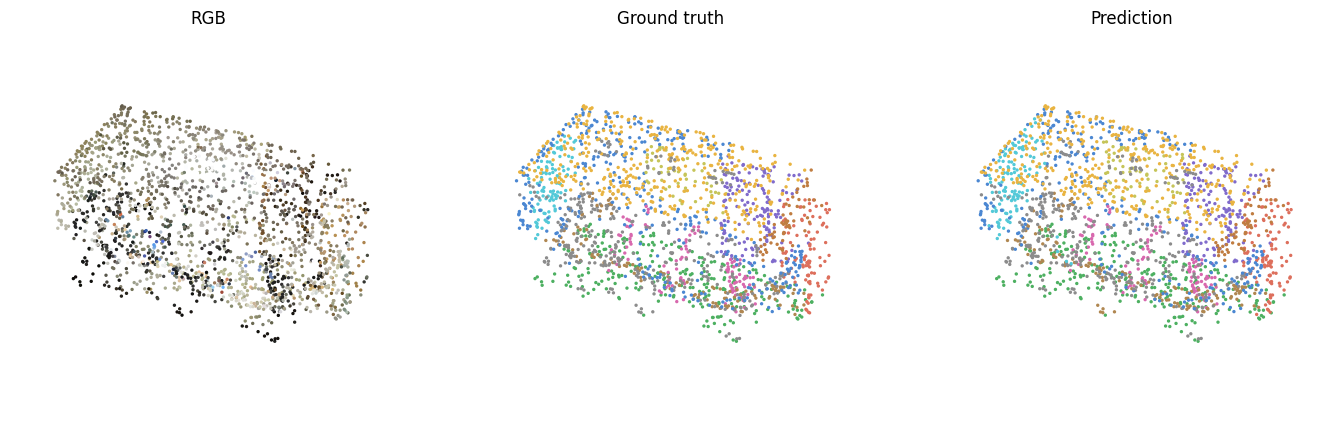

In [8]:
if sampling_available:
    # 三列使用同一批点、同一相机；预测图仅使用网络预测。
    palette=np.array([[233,180,65],[77,176,97],[75,135,210],[192,125,65],[159,105,196],[83,201,216],
     [221,111,92],[176,135,81],[216,104,174],[119,172,160],[128,107,204],[198,197,89],[140,140,140]])/255
    fig=plt.figure(figsize=(14,4.4))
    for j,(title,col) in enumerate([('RGB',rgb[idx]/255),('Ground truth',palette[truth[idx]]),('Prediction',palette[predicted[idx]])]):
        ax=fig.add_subplot(1,3,j+1,projection='3d')
        ax.scatter(*xyz[idx].T,c=col,s=2,depthshade=False)
        ax.set_title(title);ax.view_init(elev=35,azim=-65)
        ax.set_box_aspect(np.maximum(np.ptp(xyz[idx],axis=0),.01));ax.set_axis_off()
    plt.tight_layout();plt.show()
else: print('本次未生成抽样图。')


### 5.2 真正重新运行网络：原始无标签点云输入

打开 `RUN_LIVE_INFERENCE` 后执行完整新版客户端坐标预处理与神经网络推理。仅将 XYZ/RGB 传入网络；预测完成后才另外读取评估标签。模型、读取器和推理代码均来自本 Notebook 的附录。

默认样例是去标签的 `raw_office2.ply`。可换成新的有色室内扫描，但没有真值时只能检查输出与视觉结果，不能报告“准确率”。开关关闭时不声称已经重跑。

In [9]:
RUN_LIVE_INFERENCE=True
LIVE_INPUT=ROOT/'pointcloud_client/qa/raw_office2.ply'
LIVE_TRUTH=ROOT/'data/full_processed/Area_3_office_2.npz'  # 换新扫描时设为 None
if RUN_LIVE_INFERENCE and LIVE_INPUT.exists() and weight.exists():
    scan=load_module('pointcloud_client/scan_io.py')
    original,network,rgb_live,input_meta=scan.read_scan(LIVE_INPUT,scale=1.,up_axis='z')
    model,model_meta=pipeline.load_model(ROOT/'weights/randlanet_s3dis.pth',device='cpu')
    live_pred,live_conf,coarse,live_meta=pipeline.predict_semantics(network,rgb_live,model,max_passes=300)
    assert len(live_pred)==len(original) and np.isfinite(live_conf).all()
    assert np.all((live_conf>=0)&(live_conf<=1))
    print('本次网络真实推理：',len(live_pred),'点；耗时',round(live_meta['inference_seconds'],2),'秒')
    if LIVE_TRUTH is not None:
        with np.load(LIVE_TRUTH,allow_pickle=False) as d:
            assert np.array_equal(original,d['xyz']), '输入点序不一致，不可直接评估'
            live_metric=metric(d['semantic'],live_pred)
        print('该输入的评估：', {k:live_metric[k] for k in ['accuracy','miou']})
    coarse_groups,group_report=grouping.split_semantic_groups(coarse['xyz'],coarse['semantic'],coarse['confidence'],seed=42)
    live_groups=coarse_groups[coarse['inverse']]
    print('候选组：',len(group_report),'待归组点：',int((live_groups<0).sum()))
else: print('开关关闭或缺少外部点云/权重：本格未重新运行网络。需要推理时补齐依赖并将开关设为 True。')

pass 1: visited 78.7%, regular coverage 34.0%, elapsed 1.3s


pass 2: visited 100.0%, regular coverage 86.9%, elapsed 1.9s


pass 3: visited 100.0%, regular coverage 99.0%, elapsed 2.6s


pass 4: visited 100.0%, regular coverage 100.0%, elapsed 3.2s


本次网络真实推理： 739209 点；耗时 3.2 秒
该输入的评估： {'accuracy': 0.938978015689744, 'miou': 0.8217900844102309}


候选组： 46 待归组点： 4078


### 5.3 测试证据与重新检查

已有测试覆盖读入格式与单位、非法输入、合并拆分与撤销、网格是否跨越大洞、实测顶点与曲率保留、3DM 写入回读，以及打包客户端的全流程。合成带洞平面是**单元测试夹具**，不当作真实数据集或模型评估成绩。

下面读取历史 QA 记录；紧接着的单元格会在本次运行中重新检查现有 3DM 的原生网格、颜色、点数和单位。界面操作测试的历史通过不等于本次又操作过 GUI。

In [10]:
qa_paths=['pointcloud_client/qa/core_test_results.json','pointcloud_client/qa/scan_reader_tests.json',
 'pointcloud_client/qa/mesh_unit_results.json','pointcloud_client/qa/mesh_interface_results.json',
 'pointcloud_client/qa/packaged_mesh_results.json']
display(pd.DataFrame([{'记录':Path(p).name,'成功':evidence(p)['success'],'测试数':evidence(p).get('tests','集成检查')} for p in qa_paths]))
display(evidence('results/area3_batch/verification.json'))

,记录,成功,测试数
0,core_test_results.json,True,8
1,scan_reader_tests.json,True,5
2,mesh_unit_results.json,True,5
3,mesh_interface_results.json,True,集成检查
4,packaged_mesh_results.json,True,集成检查


{'aggregate_confusion_matrix_matches': True,
 'all_group_class_ids_and_point_counts_consistent': True,
 'all_room_metrics_recomputed_from_saved_predictions': True,
 'all_saved_xyz_and_rgb_equal_source': True,
 'failed_checks': 0,
 'points_checked': 18662173,
 'rooms_checked': 23}

In [11]:
if (pack_dir/'model.3dm').exists():
    import rhino3dm as r
    from scipy.spatial import cKDTree
    if 'core' not in globals(): core=load_module('pointcloud_client/core.py')
    session=core.Session.load(pack_dir/'review.pcproj')
    model_file=r.File3dm.Read(str(pack_dir/'model.3dm'));assert model_file is not None
    native_meshes=[o.Geometry for o in model_file.Objects if isinstance(o.Geometry,r.Mesh)]
    clouds=[o.Geometry for o in model_file.Objects if isinstance(o.Geometry,r.PointCloud)]
    assert len(native_meshes)==len(session.models)==47
    assert sum(len(c) for c in clouds)==len(session.xyz)==739209
    assert sum(len(m.Faces) for m in native_meshes)==sum(len(m['faces']) for m in session.models)
    assert all(m.IsValid and len(m.VertexColors)==len(m.Vertices) for m in native_meshes)
    assert model_file.Settings.ModelUnitSystem==r.UnitSystem.Meters
    rng=np.random.default_rng(CHECK_SEED)
    maximum=0.
    for m in session.models:
        v=core.model_vertices(m)
        sample=v[rng.choice(len(v),min(500,len(v)),replace=False)]
        distances=cKDTree(session.xyz[session.assignment==m['group_id']]).query(sample)[0]
        maximum=max(maximum,float(distances.max()))
    assert maximum<1e-8
    print('本次 3DM 回读 PASS：47 个有效彩色 Mesh，359631 个面，739209 个参考点；单位米。')
    print('每组随机抽查最多 500 个项目网格顶点，到对应组实测点最大距离（米）：',maximum)
else: print('未找到外部 3DM / 项目文件：本次未进行网格回读，仅有上一格历史证据。')

本次 3DM 回读 PASS：47 个有效彩色 Mesh，359631 个面，739209 个参考点；单位米。
每组随机抽查最多 500 个项目网格顶点，到对应组实测点最大距离（米）： 1.734723475976807e-18


## 6. 结果比较与建筑专业解释

### 6.1 语义分割结果

两种模型在同一 Area 3 / office_1 点序与标签体系上比较；RF 单房间训练与多房间预训练的数据量不同，不能把全部差值归结为网络架构。23 房间结果是先累加混淆矩阵再算 mIoU，与各房间 mIoU 的简单平均不同。

,方法/流程,点数,accuracy,mIoU
0,RF，Area 3 office_1,759861,48.31%,29.95%
1,RandLA-Net，历史 office_1,759861,93.24%,81.37%
2,RandLA-Net，历史 Area 3 全 23 房间,18662173,87.61%,70.20%


从嵌入的全区混淆矩阵复算一致；房间 mIoU 简单平均： 65.54%


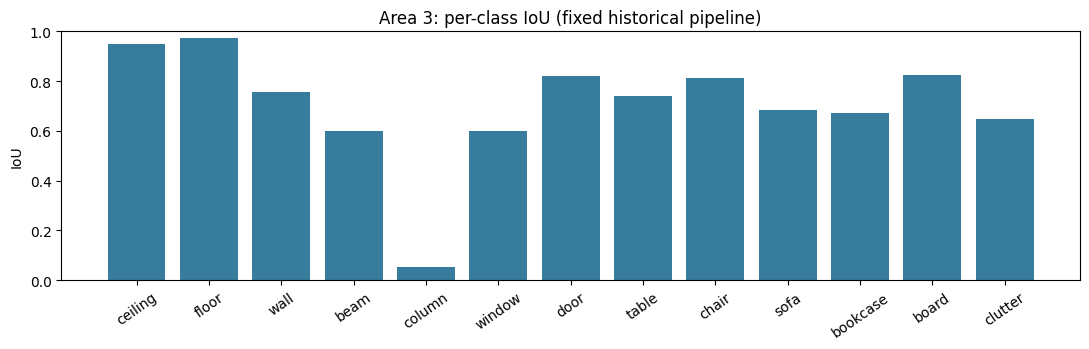

In [12]:
rf=evidence('results/random_forest/report.json')['evaluation']
single=evidence('results/pretrained_area3/report.json')['evaluation']
batch=evidence('results/area3_batch/summary.json')
agg=batch['aggregate']
display(pd.DataFrame([
 {'方法/流程':'RF，Area 3 office_1','点数':rf['points'],'accuracy':rf['accuracy'],'mIoU':rf['miou_present_union']},
 {'方法/流程':'RandLA-Net，历史 office_1','点数':single['points'],'accuracy':single['accuracy'],'mIoU':single['miou_present_union']},
 {'方法/流程':'RandLA-Net，历史 Area 3 全 23 房间','点数':agg['points'],'accuracy':agg['accuracy'],'mIoU':agg['miou_present_union']}
]).style.format({'accuracy':'{:.2%}','mIoU':'{:.2%}'}))
cm=np.array(agg['confusion_matrix']);union=cm.sum(0)+cm.sum(1)-cm.diagonal()
assert cm.sum()==agg['points']
assert np.isclose(np.trace(cm)/cm.sum(),agg['accuracy'])
assert np.isclose(np.mean(cm.diagonal()[union>0]/union[union>0]),agg['miou_present_union'])
print('从嵌入的全区混淆矩阵复算一致；房间 mIoU 简单平均：',f"{batch['mean_room_miou']:.2%}")
fig,ax=plt.subplots(figsize=(11,3.6));ax.bar(CLASSES,[agg['class_iou'][c] for c in CLASSES],color='#387c9d')
ax.set_ylabel('IoU');ax.set_ylim(0,1);ax.set_title('Area 3: per-class IoU (fixed historical pipeline)')
ax.tick_params(axis='x',rotation=35);plt.tight_layout();plt.show()

**解释：**全区地面 IoU 97.49%、天花 94.92%、墙 75.45%，但柱仅 5.27%。大面通常点多、上下文稳定；柱与墙等类别存在大量混淆。混淆矩阵显示真实柱点中约 30.4 万被预测成墙，因此不能仅用总准确率说明承重构件已经可靠识别。

建筑应用上，地面/天花分组可作为空间测量和建模参照；门窗与家具候选便于选择和继续编辑。柱、梁、门洞等涉及空间构造含义的部分应优先审阅。系统未识别材料、承重属性或法规合规性。

### 6.2 新版客户端独立核查

新版加入局部原点后，体素边界与网络输入会变化。下面独立读取去标签 PLY 运行所得预测，再与对应原始标签比对；仅说明这个房间，不拿它代替旧版 23 房间结果，也不推断任意新扫描表现。

**一个反例：**同一 office_2 房间，历史流程 accuracy 92.93%、mIoU 87.71%；新版 accuracy 93.90%、mIoU 82.18%。新版多预测出 2,237 个“柱”点，而真实标签没有柱，导致柱类 IoU=0 并进入“并集非空”平均。历史流程该类真值与预测均空，未计入平均。多数大类变好也不能抵消这一指标变化。因此保留相同定义、同时报告逐类计数，不声称新版所有指标均提升。此处 mIoU 的有效类别集合随预测改变，也是必须解释的评价限制。

,流程,accuracy,mIoU
0,历史流程 office_2,92.93%,87.71%
1,新版客户端 office_2，真实保存预测重新计分,93.90%,82.18%


柱类真实点数： 0 预测点数： 2237
新版客户端候选组： 46 ；待归组点： 4078
原生网格： 47 ；面数： 359631
47 个网格包含待归组点生成的网格，不表示识别了 47 个真实建筑构件。


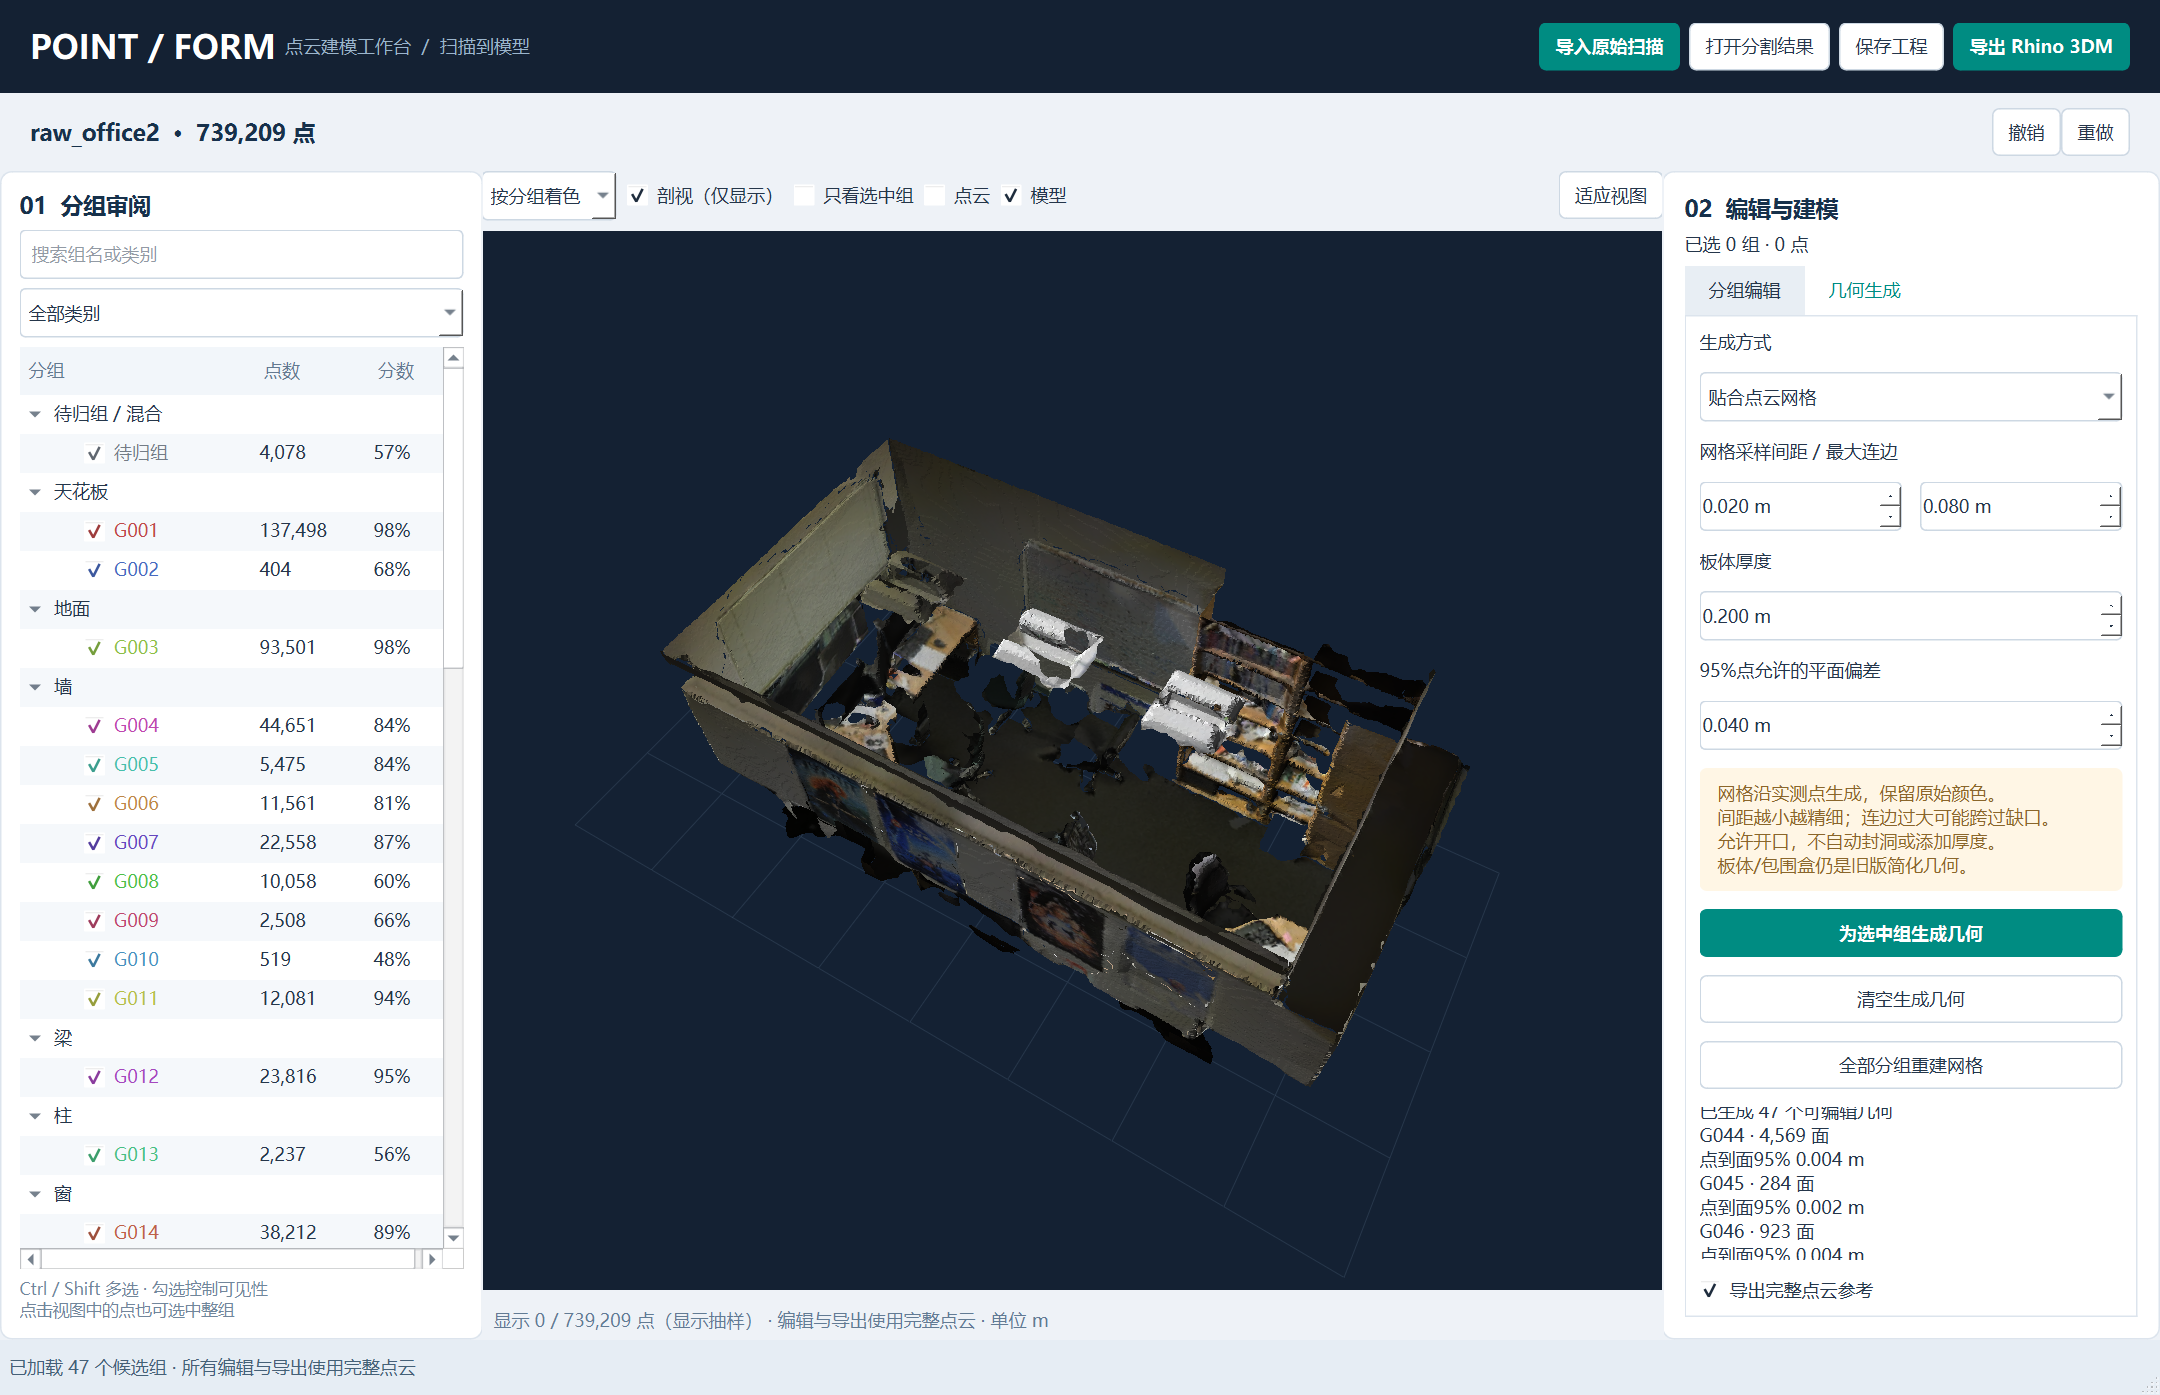

In [13]:
raw=ROOT/'data/full_processed/Area_3_office_2.npz'
new=pack_dir/'segmentation.npz'
if raw.exists() and new.exists():
    with np.load(raw,allow_pickle=False) as d: reference=d['semantic'].copy();reference_xyz=d['xyz'].copy()
    with np.load(new,allow_pickle=False) as d:
        assert np.array_equal(reference_xyz,d['xyz'])
        new_metrics=metric(reference,d['semantic'])
    old_room=next(r for r in batch['rooms'] if r['room']=='Area_3/office_2')
    display(pd.DataFrame([{'流程':'历史流程 office_2','accuracy':old_room['accuracy'],'mIoU':old_room['miou']},
        {'流程':'新版客户端 office_2，真实保存预测重新计分',
        'accuracy':new_metrics['accuracy'],'mIoU':new_metrics['miou']}]).style.format({'accuracy':'{:.2%}','mIoU':'{:.2%}'}))
    print('柱类真实点数：',int(new_metrics['cm'][4].sum()),'预测点数：',int(new_metrics['cm'][:,4].sum()))
else: print('外部逐点结果缺失：本次未复算新版客户端语义指标。')
print('新版客户端候选组：',client_report['group_count'],'；待归组点：',client_report['unassigned_group_points'])
print('原生网格：',client_report['export']['meshes'],'；面数：',client_report['export']['mesh_faces'])
print('47 个网格包含待归组点生成的网格，不表示识别了 47 个真实建筑构件。')
show_image('pointcloud_client/qa/mesh_preview.png')

In [14]:
quality=client_report['geometry']['groups']
quality_table=pd.DataFrame([{'组号':g['group_id'],'面数':g['triangles_count'],
 '点到面 P95 m':g['cloud_to_surface_p95_m'],'覆盖率':g['covered_fraction'],'封闭':g['closed']} for g in quality])
display(quality_table.sort_values('点到面 P95 m',ascending=False).head(8))
print('逐组 P95 的中位数（不是全场景 P95）：',quality_table['点到面 P95 m'].median())
print('逐组 P95 的最大值：',quality_table['点到面 P95 m'].max())

,组号,面数,点到面 P95 m,覆盖率,封闭
20,19,230,0.167060,0.938815,False
25,24,181,0.025685,0.996737,False
24,23,2741,0.019682,0.997800,False
29,28,253,0.019122,0.997167,False
28,27,119,0.016405,1.000000,False
30,29,6089,0.015394,1.000000,False
22,21,4029,0.015209,1.000000,False
43,42,2830,0.014602,0.999400,False


逐组 P95 的中位数（不是全场景 P95）： 0.003983089700341225
逐组 P95 的最大值： 0.16705971956253052


**网格解释：**比简化长方体更能表达真实表面、家具弯曲与局部不规则边界。网格保留洞和边界，缺测区域没有自动补成真实结构。点到面 P95 在各组差异明显，不能把“逐组 P95 的中位数”说成“整个模型误差”。较大误差组需检查稀疏点、遮挡、离群点与分组污染。

**价值与边界：**成果提供“可追溯、可审阅、可继续编辑”的扫描辅助工作流，尚未证明节省多少人工工时。后续应通过人工审阅计时、实例分组真值、新设备扫描和受控参数实验验证效用。网格也不等同于可直接用于施工或 BIM 分析的构件实体。

## 7. AI 编程、质量测试、对话与本人决策

### 7.1 AI 使用范围与质量控制

| 内容 | AI 参与 | 已有验证 |
|---|---|---|---|
| 数据处理与来源记录 | 检索、下载/校验/转换脚本 | ZIP 校验、点数、损坏行日志 |
| 模型与基线 | 官方网络适配、RF、推理与指标代码 | 权重严格加载、独立标签计分、多场景检查 | 
| 分组和网格 | RANSAC、DBSCAN、BPA 封装与过滤 | 确定性检查、洞口、曲率、顶点来源 | 
| 客户端与交付 | UI、保存项目、3DM 导出、打包 | 单元测试、界面测试、打包端到端与回读 | 
| Notebook | 结构、说明、图表、测试单元格 | 重新运行与错误检查 | 

**AI 编程质量小结：**AI 能快速串联依赖与流程，但生成代码必须用输入输出约束、真实数据与反例检验。过程中遇到编译扩展不匹配、RANSAC 不稳定、几何过度简化等问题，通过适配、固定采样及更换几何表达处理。测试通过仅支持已覆盖行为，不能保证新扫描泛化或建筑构件语义正确。

### 7.2 项目对话节选与决策轨迹

以下用户话语来自实际对话；右列是决策结果摘要，**不是逐字 AI 回复，也不是完整聊天导出**。

| 用户原话节选 | 对项目的实际影响 |
|---|---|
| “我的专业是建筑学，目前我大致想法是在3d点云中利用机器学习来实现建模时的辅助” | 确定专业需求与点云方向 |
| “通过ransac是不是可以把点云分成不同部分，这样我觉得可以把这每部分打组，让用户来决定” | 将自动结果定位为候选组，保留人工决策 |
| “加载现有的预训练模型是不是可以快速的实现正确率较高的分割” | 使用预训练模型，补充实际评估而非保证准确率 |
| “那我们先完成从点云到分割完成这一部分，后面再来做面向用户的从分割完成到犀牛模型的客户端” | 按算法验证、客户端交付分阶段推进 |
| “独立窗口，处理后导出 3DM” | 选择独立客户端，不依赖 Rhino 内插件面板 |
| “现在这种简化版体不太行， 有没有办法根据点来建出更贴合的模型” | 接受用户对几何表达的否定，改进重建路径 |
| “做贴合点云的网格吧” | 最终交付按组彩色网格，而不是简化体块 |

**对话质量小结：**用户提供了领域、期限、操作形式与几何质量反馈，使目标逐步具体；问题从“能否自动建实体”收敛到“语义分类—候选分组—审阅—网格”。需要避免 AI 把局部演示当作通用效果，把分组数量当作识别准确率，把 Mesh 当作实体，或代替用户撰写未发生的亲身体验。本文件相应区分数据划分、流程版本、结果类型与待完成事项。



## 8. 参考文献与软件来源

1. Armeni, I. et al. (2016). *3D Semantic Parsing of Large-Scale Indoor Spaces*. CVPR. [原始论文](https://openaccess.thecvf.com/content_cvpr_2016/html/Armeni_3D_Semantic_Parsing_CVPR_2016_paper.html)。[数据镜像 cminst/S3DIS](https://huggingface.co/datasets/cminst/S3DIS)。
2. Hu, Q. et al. (2020). *RandLA-Net: Efficient Semantic Segmentation of Large-Scale Point Clouds*. CVPR. [原始论文](https://openaccess.thecvf.com/content_CVPR_2020/html/Hu_RandLA-Net_Efficient_Semantic_Segmentation_of_Large-Scale_Point_Clouds_CVPR_2020_paper.html)。本项目不将论文成绩当作本地成绩。
3. [Open3D-ML](https://github.com/isl-org/Open3D-ML)，固定提交 `a3d0f7a51d4eef0b94b9000a7d74af05e2d54c4f`。[配置及测试区](https://github.com/isl-org/Open3D-ML/blob/a3d0f7a51d4eef0b94b9000a7d74af05e2d54c4f/ml3d/configs/randlanet_s3dis.yml)。[预训练权重](https://storage.googleapis.com/open3d-releases/model-zoo/randlanet_s3dis_202201071330utc.pth)。许可证全文及来源哈希保存在附录。
4. [Open3D 表面重建文档](https://www.open3d.org/docs/release/tutorial/geometry/surface_reconstruction.html)：Ball Pivoting 使用点及法向进行表面重建；本文附加长边和点支持过滤。其他方法未完成受控对比，不宣称 BPA 全面优于 Poisson。
5. [scikit-learn RandomForestClassifier](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestClassifier.html)、[DBSCAN](https://scikit-learn.org/stable/modules/generated/sklearn.cluster.DBSCAN.html)：基线学习与密度聚类实现。
6. [rhino3dm 官方项目](https://github.com/mcneel/rhino3dm)：原生 3DM 序列化与回读；此处导出网格，不是自动生成参数化 BIM。

## 附录 A：完整源码与环境记录

以下各格将完整源码保存为字符串，以便只运行 Notebook 时不会自动启动 GUI、下载大数据或覆盖源文件。正文的 `load_module()` **直接执行这些内嵌源码**中的函数，不依赖另一个未收录的算法实现。修改源码字符串后需保存 Notebook，再重启内核运行；开头会重新读取已保存附录。

为方便浏览，支持折叠的 Jupyter 前端默认收起源码。不会把所有功能归为自主原创：`randlanet_portable.py` 明确注明上游 MIT 来源。GUI、下载、批处理、测试与打包脚本也收录，正常运行正文不触发它们的命令行入口。

### `prepare_sample.py`

In [15]:
SOURCE_FILES['prepare_sample.py'] = '"""Retrieve one annotated S3DIS room using byte ranges; retain provenance."""\nimport io, zipfile, requests, json, hashlib, sys, argparse, re, time\nfrom pathlib import Path\nfrom concurrent.futures import ThreadPoolExecutor\nimport numpy as np\n\nROOT=Path(__file__).parent\nURL=\'https://huggingface.co/datasets/cminst/S3DIS/resolve/main/Stanford3dDataset_v1.2_Aligned_Version.zip\'\nSIZE=4394701719\nCLASSES=[\'ceiling\',\'floor\',\'wall\',\'beam\',\'column\',\'window\',\'door\',\'table\',\'chair\',\'sofa\',\'bookcase\',\'board\',\'clutter\']\n\nclass RemoteZip(io.RawIOBase):\n    def __init__(self):self.pos=0;self.transferred=0\n    def seekable(self):return True\n    def readable(self):return True\n    def tell(self):return self.pos\n    def seek(self,offset,whence=0):\n        self.pos=offset if whence==0 else self.pos+offset if whence==1 else SIZE+offset\n        return self.pos\n    def read(self,n=-1):\n        if n<0:n=SIZE-self.pos\n        if n==0:return b\'\'\n        if n>32*1024*1024:raise ValueError(\'Unexpected large range\')\n        start=self.pos;end=min(start+n,SIZE)-1\n        for attempt in range(4):\n            try:\n                with requests.get(URL,params={\'range_start\':start,\'range_end\':end},headers={\'Range\':f\'bytes={start}-{end}\'},stream=True,timeout=30) as r:\n                    r.raise_for_status()\n                    if r.status_code!=206 or not r.headers.get(\'Content-Range\',\'\').startswith(f\'bytes {start}-\'):\n                        raise ValueError(\'Range request not honored; aborting full download\')\n                    b=r.content\n                break\n            except requests.RequestException:\n                if attempt==3:raise\n                time.sleep(1+attempt)\n        if len(b)!=end-start+1:raise ValueError(\'Short range read\')\n        self.pos+=len(b);self.transferred+=len(b);return b\n\ndef main():\n    parser=argparse.ArgumentParser()\n    parser.add_argument(\'--room\',default=\'Area_1/office_1\')\n    parser.add_argument(\'--inspect\',action=\'store_true\')\n    args=parser.parse_args()\n    if not re.fullmatch(r\'Area_[1-6]/[A-Za-z]+_\\d+\',args.room):raise ValueError(\'Invalid room identifier\')\n    area,room_name=args.room.split(\'/\')\n    ROOT.mkdir(exist_ok=True)\n    remote=RemoteZip()\n    with zipfile.ZipFile(remote) as z:\n        entries=[x for x in z.infolist() if \'/\'+args.room+\'/Annotations/\' in x.filename and x.filename.endswith(\'.txt\')]\n        if not entries:raise ValueError(\'Room not found\')\n        print(\'Room:\',args.room,\'annotation files:\',len(entries),\'compressed bytes:\',sum(x.compress_size for x in entries),flush=True)\n        meta=[{\'name\':x.filename,\'header_offset\':x.header_offset,\'compressed_size\':x.compress_size,\'file_size\':x.file_size,\'CRC\':x.CRC} for x in entries]\n    (ROOT/f\'remote_{area}_{room_name}_manifest.json\').write_text(json.dumps(meta,indent=2),encoding=\'utf8\')\n    if args.inspect:return\n    import struct,zlib,binascii\n    def fetch(info):\n        dest=ROOT/\'data\'/\'raw\'/area/room_name/\'Annotations\'/Path(info.filename).name\n        data=dest.read_bytes() if dest.exists() else b\'\'\n        if len(data)!=info.file_size or binascii.crc32(data)&0xffffffff!=info.CRC:\n            f=RemoteZip();f.seek(info.header_offset);h=f.read(30)\n            vals=struct.unpack(\'<4s5H3I2H\',h)\n            name_len,extra_len=vals[-2:]\n            f.seek(info.header_offset+30+name_len+extra_len)\n            raw=f.read(info.compress_size)\n            data=zlib.decompress(raw,-15) if info.compress_type==8 else raw\n            if len(data)!=info.file_size or binascii.crc32(data)&0xffffffff!=info.CRC:raise ValueError(\'CRC mismatch\')\n        dest.parent.mkdir(parents=True,exist_ok=True);dest.write_bytes(data)\n        values=np.loadtxt(io.BytesIO(data),dtype=np.float32,ndmin=2)\n        category=dest.stem.rsplit(\'_\',1)[0]\n        if category not in CLASSES:raise ValueError(\'Unexpected class \'+category)\n        return values,CLASSES.index(category),{\'filename\':dest.name,\'points\':len(values),\'sha256\':hashlib.sha256(data).hexdigest()}\n    parts=[];labels=[];instances=[];files=[]\n    with ThreadPoolExecutor(max_workers=6) as executor:\n        for i,(values,label,metadata) in enumerate(executor.map(fetch,entries)):\n            parts.append(values);labels.append(np.full(len(values),label,dtype=np.uint8));instances.append(np.full(len(values),i,dtype=np.int16));files.append(metadata)\n            print(\'Loaded\',metadata[\'filename\'],metadata[\'points\'],flush=True)\n    values=np.concatenate(parts);labels=np.concatenate(labels);instances=np.concatenate(instances)\n    assert values.shape[1]==6 and np.isfinite(values).all()\n    out=ROOT/\'data\'/\'processed\';out.mkdir(parents=True,exist_ok=True)\n    np.savez_compressed(out/f\'{area}_{room_name}.npz\',xyz=values[:,:3],rgb=values[:,3:].astype(np.uint8),semantic=labels,instance=instances)\n    provenance={\'dataset\':\'S3DIS v1.2 aligned\',\'room\':args.room,\'original_paper\':\'https://openaccess.thecvf.com/content_cvpr_2016/html/Armeni_3D_Semantic_Parsing_CVPR_2016_paper.html\',\'download_mirror\':URL,\'mirror_note\':\'Third-party mirror; mirror license tag is not taken as original dataset license. Preserve original dataset attribution and check original terms before redistribution.\',\'classes\':CLASSES,\'points\':len(values),\'counts\':{CLASSES[int(k)]:int(v) for k,v in zip(*np.unique(labels,return_counts=True))},\'files\':files,\'use\':\'Area 3 is held out according to the official Open3D-ML RandLA-Net S3DIS configuration; this subset is not the full benchmark.\' if area==\'Area_3\' else \'Development sample only; not an independent test set.\'}\n    (ROOT/\'data\'/f\'{area}_{room_name}_provenance.json\').write_text(json.dumps(provenance,indent=2),encoding=\'utf8\')\n    if args.room==\'Area_1/office_1\':(ROOT/\'data\'/\'provenance.json\').write_text(json.dumps(provenance,indent=2),encoding=\'utf8\')\n    print(\'READY\',len(values),\'points\',provenance[\'counts\'],flush=True)\n\nif __name__==\'__main__\':main()\n'


### `download_full_s3dis.py`

In [16]:
SOURCE_FILES['download_full_s3dis.py'] = '"""Resumable parallel download; verify complete archive against mirror LFS SHA256."""\nfrom pathlib import Path\nfrom concurrent.futures import ThreadPoolExecutor,as_completed\nimport requests,json,time,hashlib,os\nROOT=Path(__file__).parent\nNAME=\'Stanford3dDataset_v1.2_Aligned_Version.zip\'\nURL=\'https://huggingface.co/datasets/cminst/S3DIS/resolve/main/\'+NAME\nSIZE=4394701719\nSHA256=\'f16db73310983e6b4df9b3d5290d20315e0cdf56c14f0d795f96d372378fce94\'\nBLOCK=16*1024*1024\n\ndef file_hash(path):\n    h=hashlib.sha256()\n    with path.open(\'rb\') as f:\n        for b in iter(lambda:f.read(8*1024*1024),b\'\'):h.update(b)\n    return h.hexdigest()\n\ndef download():\n    out=ROOT/\'data/downloads\';out.mkdir(parents=True,exist_ok=True)\n    final=out/NAME;part=out/(NAME+\'.part\');state_path=out/\'download_state.json\'\n    if final.exists():\n        if final.stat().st_size==SIZE and file_hash(final)==SHA256:\n            print(\'Already verified:\',final,flush=True);return final\n        raise ValueError(\'Existing final archive does not match expected hash; preserve and investigate\')\n    state=json.loads(state_path.read_text()) if state_path.exists() else {\'sha256\':SHA256,\'done\':{}}\n    assert state[\'sha256\']==SHA256\n    if not part.exists():\n        with part.open(\'wb\') as f:f.truncate(SIZE)\n        state[\'done\']={}\n    assert part.stat().st_size==SIZE\n    # Revalidate completed ranges before resuming, rather than trusting the log.\n    with part.open(\'rb\') as f:\n        for key,digest in list(state[\'done\'].items()):\n            start=int(key)*BLOCK;f.seek(start)\n            if hashlib.sha256(f.read(min(BLOCK,SIZE-start))).hexdigest()!=digest:del state[\'done\'][key]\n    def fetch(i):\n        start=i*BLOCK;end=min(start+BLOCK,SIZE)-1\n        for attempt in range(6):\n            try:\n                with requests.get(URL,params={\'range_start\':start,\'range_end\':end},headers={\'Range\':f\'bytes={start}-{end}\'},stream=True,timeout=(20,60)) as r:\n                    r.raise_for_status()\n                    if r.status_code!=206 or not r.headers.get(\'Content-Range\',\'\').startswith(f\'bytes {start}-{end}/\'):raise ValueError(\'Server did not honor exact range\')\n                    h=hashlib.sha256();count=0\n                    with part.open(\'r+b\') as f:\n                        f.seek(start)\n                        for b in r.iter_content(1024*1024):\n                            count+=len(b)\n                            if count>end-start+1:raise ValueError(\'Oversized range\')\n                            f.write(b);h.update(b)\n                    if count!=end-start+1:raise ValueError(\'Incomplete range\')\n                return i,h.hexdigest()\n            except (requests.RequestException,ValueError):\n                if attempt==5:raise\n                time.sleep(min(8,attempt+1))\n    count=(SIZE+BLOCK-1)//BLOCK;pending=[i for i in range(count) if str(i) not in state[\'done\']]\n    started=time.perf_counter();last=0;initial=len(state[\'done\'])\n    with ThreadPoolExecutor(max_workers=6) as pool:\n        for future in as_completed([pool.submit(fetch,i) for i in pending]):\n            i,digest=future.result();state[\'done\'][str(i)]=digest\n            temp=state_path.with_suffix(\'.tmp\');temp.write_text(json.dumps(state),encoding=\'utf8\');os.replace(temp,state_path)\n            now=time.perf_counter()\n            if now-last>5 or len(state[\'done\'])==count:\n                done=sum(min(BLOCK,SIZE-int(k)*BLOCK) for k in state[\'done\'])\n                rate=(len(state[\'done\'])-initial)*BLOCK/max(now-started,.01)/1e6\n                print(f\'Download {done/SIZE:.1%} | {done/1e9:.2f}/{SIZE/1e9:.2f} GB | {rate:.1f} MB/s\',flush=True);last=now\n    print(\'Verifying complete SHA-256...\',flush=True)\n    actual=file_hash(part)\n    if actual!=SHA256:raise ValueError(\'Complete archive hash mismatch: \'+actual)\n    os.replace(part,final)\n    provenance={\'dataset\':\'S3DIS v1.2 Aligned Version\',\'download_url\':URL,\'source_type\':\'third-party mirror\',\n        \'bytes\':SIZE,\'sha256\':actual,\'verification\':\'matches Hugging Face repository LFS SHA256; not an independently supplied Stanford checksum\',\n        \'license_note\':\'Mirror license label does not replace original dataset terms.\',\'download_date\':\'2026-11-11\'}\n    (out/\'provenance.json\').write_text(json.dumps(provenance,indent=2),encoding=\'utf8\')\n    print(\'DOWNLOAD VERIFIED\',str(final),flush=True)\n    return final\n\nif __name__==\'__main__\':download()\n'


### `prepare_full_s3dis.py`

In [17]:
SOURCE_FILES['prepare_full_s3dis.py'] = '"""Safely extract the verified archive and convert all rooms, recording bad rows."""\nfrom pathlib import Path\nfrom concurrent.futures import ThreadPoolExecutor,as_completed\nimport zipfile,shutil,json,time,re,io,hashlib,os\nimport numpy as np\nROOT=Path(__file__).parent\nCLASSES=[\'ceiling\',\'floor\',\'wall\',\'beam\',\'column\',\'window\',\'door\',\'table\',\'chair\',\'sofa\',\'bookcase\',\'board\',\'clutter\']\n\ndef save_npz_fast(path,**arrays):\n    temporary=path.with_suffix(\'.tmp\')\n    with zipfile.ZipFile(temporary,\'w\',compression=zipfile.ZIP_DEFLATED,compresslevel=1,allowZip64=True) as z:\n        for name,array in arrays.items():\n            with z.open(name+\'.npy\',\'w\',force_zip64=True) as f:np.lib.format.write_array(f,array,allow_pickle=False)\n    os.replace(temporary,path)\n\ndef extract():\n    archive=ROOT/\'data/downloads/Stanford3dDataset_v1.2_Aligned_Version.zip\'\n    provenance=json.loads((archive.parent/\'provenance.json\').read_text())\n    assert archive.stat().st_size==provenance[\'bytes\']\n    destination=ROOT/\'data/full_raw\';destination.mkdir(parents=True,exist_ok=True)\n    marker=destination/\'extraction_verified.json\'\n    if marker.exists():return destination\n    total=0;last=0;start=time.perf_counter()\n    with zipfile.ZipFile(archive) as z:\n        for i,info in enumerate(z.infolist()):\n            target=(destination/info.filename).resolve()\n            if not target.is_relative_to(destination.resolve()):raise ValueError(\'Unsafe ZIP path: \'+info.filename)\n            if info.is_dir():target.mkdir(parents=True,exist_ok=True);continue\n            target.parent.mkdir(parents=True,exist_ok=True)\n            with z.open(info) as src,target.open(\'wb\') as dst:shutil.copyfileobj(src,dst,1024*1024)\n            # ZipExtFile checks the CRC when the member has been fully consumed.\n            assert target.stat().st_size==info.file_size\n            total+=info.file_size\n            if time.perf_counter()-last>10:\n                print(f\'Extracted {i+1}/{len(z.infolist())} entries, {total/1e9:.2f} GB; CRC verified\',flush=True);last=time.perf_counter()\n    marker.write_text(json.dumps({\'archive_sha256\':provenance[\'sha256\'],\'uncompressed_bytes\':total,\'all_member_crc_verified\':True,\'seconds\':time.perf_counter()-start},indent=2))\n    return destination\n\ndef load_annotation(path):\n    rejected=[]\n    try:values=np.loadtxt(path,dtype=np.float32,ndmin=2,encoding=\'utf8\')\n    except (ValueError,UnicodeError):\n        rows=[]\n        with path.open(encoding=\'utf8\',errors=\'replace\') as f:\n            for line_no,line in enumerate(f,1):\n                try:\n                    fields=line.split()\n                    if len(fields)!=6:raise ValueError(\'expected 6 fields\')\n                    rows.append([float(x) for x in fields])\n                except ValueError:rejected.append({\'line\':line_no,\'text\':line.strip()[:160],\'reason\':\'malformed row\'})\n        values=np.asarray(rows,dtype=np.float32).reshape(-1,6)\n    if values.shape[1]!=6:raise ValueError(\'Unexpected annotation columns: \'+str(path))\n    valid=np.isfinite(values).all(1)&(values[:,3:]>=0).all(1)&(values[:,3:]<=255).all(1)\n    for row in np.flatnonzero(~valid):rejected.append({\'parsed_row\':int(row),\'reason\':\'nonfinite XYZ/RGB or RGB outside [0,255]\'})\n    return values[valid],rejected\n\ndef convert_room(folder,out):\n    area=folder.parent.parent.name;room=folder.parent.name;identifier=area+\'_\'+room\n    target=out/(identifier+\'.npz\');record_path=out/(identifier+\'.json\')\n    if target.exists() and record_path.exists():return json.loads(record_path.read_text(encoding=\'utf8\'))\n    xyz=[];rgb=[];semantic=[];instances=[];records=[]\n    for instance,path in enumerate(sorted(folder.glob(\'*.txt\'))):\n        values,rejected=load_annotation(path);category=path.stem.rsplit(\'_\',1)[0]\n        mapped=category if category in CLASSES else \'clutter\'\n        xyz.append(values[:,:3]);rgb.append(np.rint(values[:,3:]).astype(np.uint8))\n        semantic.append(np.full(len(values),CLASSES.index(mapped),np.uint8));instances.append(np.full(len(values),instance,np.int32))\n        records.append({\'file\':path.name,\'original_class\':category,\'mapped_class\':mapped,\'points\':len(values),\'rejected_rows\':rejected})\n    arrays={\'xyz\':np.concatenate(xyz),\'rgb\':np.concatenate(rgb),\'semantic\':np.concatenate(semantic),\'instance\':np.concatenate(instances)}\n    assert len(arrays[\'xyz\'])>0 and all(len(a)==len(arrays[\'xyz\']) for a in arrays.values())\n    save_npz_fast(target,**arrays)\n    record={\'room\':area+\'/\'+room,\'file\':str(target.relative_to(ROOT)),\'points\':len(arrays[\'xyz\']),\'instances\':len(records),\n        \'class_counts\':np.bincount(arrays[\'semantic\'],minlength=13).tolist(),\'rejected_rows\':sum(len(r[\'rejected_rows\']) for r in records),\n        \'unknown_class_files\':[r[\'file\'] for r in records if r[\'original_class\']!=r[\'mapped_class\']],\n        \'annotations\':records,\'policy\':\'Original files retained; malformed/nonfinite/out-of-range rows excluded and explicitly logged. Unknown object classes map to clutter, following Open3D-ML S3DIS.\'}\n    record_path.write_text(json.dumps(record,indent=2),encoding=\'utf8\');return record\n\ndef prepare():\n    start=time.perf_counter();raw=extract();out=ROOT/\'data/full_processed\';out.mkdir(parents=True,exist_ok=True)\n    folders=sorted(p for p in raw.rglob(\'Annotations\') if p.is_dir() and re.fullmatch(\'Area_[1-6]\',p.parent.parent.name))\n    assert len(folders)==272\n    reports=[]\n    with ThreadPoolExecutor(max_workers=2) as pool:\n        for future in as_completed([pool.submit(convert_room,p,out) for p in folders]):\n            record=future.result();reports.append(record)\n            print(f"Converted {len(reports)}/{len(folders)} {record[\'room\']} {record[\'points\']:,} points, rejected {record[\'rejected_rows\']}",flush=True)\n    summary={\'dataset\':\'S3DIS v1.2 Aligned Version\',\'room_count\':len(reports),\'total_points\':sum(r[\'points\'] for r in reports),\n        \'total_rejected_rows\':sum(r[\'rejected_rows\'] for r in reports),\'classes\':CLASSES,\'seconds\':time.perf_counter()-start,\n        \'rooms\':[{\'room\':r[\'room\'],\'file\':r[\'file\'],\'points\':r[\'points\'],\'rejected_rows\':r[\'rejected_rows\'],\'unknown_class_files\':r[\'unknown_class_files\']} for r in sorted(reports,key=lambda r:r[\'room\'])]}\n    (out/\'manifest.json\').write_text(json.dumps(summary,indent=2),encoding=\'utf8\')\n    print(\'ALL ROOMS CONVERTED\',summary[\'room_count\'],\'points\',summary[\'total_points\'],\'rejected\',summary[\'total_rejected_rows\'],flush=True)\n\nif __name__==\'__main__\':prepare()\n'


### `build_portable_model.py`

In [18]:
SOURCE_FILES['build_portable_model.py'] = '"""Extract upstream RandLA-Net inference graph without Open3D compiled ML ops.\n\nAll learned layers and forward operations are retained from the pinned source.\nOnly training/data-pipeline dependencies are removed. See vendor/open3d_ml/LICENSE.\n"""\nfrom pathlib import Path\nimport ast\nROOT=Path(__file__).parent\ntree=ast.parse((ROOT/\'vendor/open3d_ml/randlanet.py\').read_text(encoding=\'utf8\'))\nclasses=[]\nfor node in tree.body:\n    if not isinstance(node,ast.ClassDef):continue\n    if node.name==\'RandLANet\':\n        node.body=[m for m in node.body if isinstance(m,ast.FunctionDef) and m.name in [\'__init__\',\'forward\',\'random_sample\',\'nearest_interpolation\']]\n        init=next(m for m in node.body if m.name==\'__init__\')\n        init.body=[s for s in init.body if not (isinstance(s,ast.Assign) and any(isinstance(t,ast.Attribute) and t.attr==\'augmenter\' for t in s.targets))]\n    classes.append(node)\nheader=\'\'\'# Adapted from Open3D-ML (MIT); see vendor/open3d_ml/LICENSE.\n# Generated by build_portable_model.py from pinned upstream source.\nimport torch\nimport torch.nn as nn\nimport numpy as np\nfrom types import SimpleNamespace\n\nclass BaseModel(nn.Module):\n    def __init__(self, **kwargs):\n        super().__init__()\n        self.cfg = SimpleNamespace(**kwargs)\n    @property\n    def device(self):\n        return next(self.parameters()).device\n\n\'\'\'\n(ROOT/\'randlanet_portable.py\').write_text(header+\'\\n\\n\'.join(ast.unparse(c) for c in classes)+\'\\n\',encoding=\'utf8\')\nprint(\'Created portable inference module from\',len(classes),\'upstream classes\')\n'


### `randlanet_portable.py`

In [19]:
SOURCE_FILES['randlanet_portable.py'] = '# Adapted from Open3D-ML (MIT); see vendor/open3d_ml/LICENSE.\n# Generated by build_portable_model.py from pinned upstream source.\nimport torch\nimport torch.nn as nn\nimport numpy as np\nfrom types import SimpleNamespace\n\nclass BaseModel(nn.Module):\n    def __init__(self, **kwargs):\n        super().__init__()\n        self.cfg = SimpleNamespace(**kwargs)\n    @property\n    def device(self):\n        return next(self.parameters()).device\n\nclass RandLANet(BaseModel):\n\n    def __init__(self, name=\'RandLANet\', num_neighbors=16, num_layers=4, num_points=4096 * 11, num_classes=19, ignored_label_inds=[0], sub_sampling_ratio=[4, 4, 4, 4], in_channels=3, dim_features=8, dim_output=[16, 64, 128, 256], grid_size=0.06, batcher=\'DefaultBatcher\', ckpt_path=None, augment={}, **kwargs):\n        super().__init__(name=name, num_neighbors=num_neighbors, num_layers=num_layers, num_points=num_points, num_classes=num_classes, ignored_label_inds=ignored_label_inds, sub_sampling_ratio=sub_sampling_ratio, in_channels=in_channels, dim_features=dim_features, dim_output=dim_output, grid_size=grid_size, batcher=batcher, ckpt_path=ckpt_path, augment=augment, **kwargs)\n        cfg = self.cfg\n        self.fc0 = nn.Linear(cfg.in_channels, cfg.dim_features)\n        self.bn0 = nn.BatchNorm2d(cfg.dim_features, eps=1e-06, momentum=0.01)\n        self.encoder = []\n        encoder_dim_list = []\n        dim_feature = cfg.dim_features\n        for i in range(cfg.num_layers):\n            self.encoder.append(LocalFeatureAggregation(dim_feature, cfg.dim_output[i], cfg.num_neighbors))\n            dim_feature = 2 * cfg.dim_output[i]\n            if i == 0:\n                encoder_dim_list.append(dim_feature)\n            encoder_dim_list.append(dim_feature)\n        self.encoder = nn.ModuleList(self.encoder)\n        self.mlp = SharedMLP(dim_feature, dim_feature, activation_fn=nn.LeakyReLU(0.2))\n        self.decoder = []\n        for i in range(cfg.num_layers):\n            self.decoder.append(SharedMLP(encoder_dim_list[-i - 2] + dim_feature, encoder_dim_list[-i - 2], transpose=True, activation_fn=nn.LeakyReLU(0.2)))\n            dim_feature = encoder_dim_list[-i - 2]\n        self.decoder = nn.ModuleList(self.decoder)\n        self.fc1 = nn.Sequential(SharedMLP(dim_feature, 64, activation_fn=nn.LeakyReLU(0.2)), SharedMLP(64, 32, activation_fn=nn.LeakyReLU(0.2)), nn.Dropout(0.5), SharedMLP(32, cfg.num_classes, bn=False))\n\n    def forward(self, inputs):\n        """Forward pass for RandLANet\n\n        Args:\n            inputs: torch.Tensor, shape (B, N, d_in)\n                input points\n\n        Returns\n            torch.Tensor, shape (B, num_classes, N)\n                segmentation scores for each point\n\n        """\n        cfg = self.cfg\n        feat = inputs[\'features\'].to(self.device)\n        coords_list = [arr.to(self.device) for arr in inputs[\'coords\']]\n        neighbor_indices_list = [arr.to(self.device) for arr in inputs[\'neighbor_indices\']]\n        subsample_indices_list = [arr.to(self.device) for arr in inputs[\'sub_idx\']]\n        interpolation_indices_list = [arr.to(self.device) for arr in inputs[\'interp_idx\']]\n        feat = self.fc0(feat).transpose(-2, -1).unsqueeze(-1)\n        feat = self.bn0(feat)\n        l_relu = nn.LeakyReLU(0.2)\n        feat = l_relu(feat)\n        encoder_feat_list = []\n        for i in range(cfg.num_layers):\n            feat_encoder_i = self.encoder[i](coords_list[i], feat, neighbor_indices_list[i])\n            feat_sampled_i = self.random_sample(feat_encoder_i, subsample_indices_list[i])\n            if i == 0:\n                encoder_feat_list.append(feat_encoder_i.clone())\n            encoder_feat_list.append(feat_sampled_i.clone())\n            feat = feat_sampled_i\n        feat = self.mlp(feat)\n        for i in range(cfg.num_layers):\n            feat_interpolation_i = self.nearest_interpolation(feat, interpolation_indices_list[-i - 1])\n            feat_decoder_i = torch.cat([encoder_feat_list[-i - 2], feat_interpolation_i], dim=1)\n            feat_decoder_i = self.decoder[i](feat_decoder_i)\n            feat = feat_decoder_i\n        scores = self.fc1(feat)\n        return scores.squeeze(3).transpose(1, 2)\n\n    @staticmethod\n    def random_sample(feature, pool_idx):\n        """\n        Args:\n            feature: [B, d, N, 1] input features matrix\n            pool_idx: [B, N\', max_num] N\' < N, N\' is the selected position after pooling\n\n        Returns:\n             pool_features = [B, N\', d] pooled features matrix\n\n        """\n        feature = feature.squeeze(3)\n        num_neigh = pool_idx.size()[2]\n        batch_size = feature.size()[0]\n        d = feature.size()[1]\n        pool_idx = torch.reshape(pool_idx, (batch_size, -1))\n        pool_idx = pool_idx.unsqueeze(2).expand(batch_size, -1, d)\n        feature = feature.transpose(1, 2)\n        pool_features = torch.gather(feature, 1, pool_idx)\n        pool_features = torch.reshape(pool_features, (batch_size, -1, num_neigh, d))\n        pool_features, _ = torch.max(pool_features, 2, keepdim=True)\n        pool_features = pool_features.permute(0, 3, 1, 2)\n        return pool_features\n\n    @staticmethod\n    def nearest_interpolation(feature, interp_idx):\n        """\n        Args:\n            feature: [B, d, N] input features matrix\n            interp_idx: [B, up_num_points, 1] nearest neighbour index\n\n        Returns:\n             [B, up_num_points, d] interpolated features matrix\n\n        """\n        feature = feature.squeeze(3)\n        d = feature.size(1)\n        batch_size = interp_idx.size()[0]\n        up_num_points = interp_idx.size()[1]\n        interp_idx = torch.reshape(interp_idx, (batch_size, up_num_points))\n        interp_idx = interp_idx.unsqueeze(1).expand(batch_size, d, -1)\n        interpolatedim_features = torch.gather(feature, 2, interp_idx)\n        interpolatedim_features = interpolatedim_features.unsqueeze(3)\n        return interpolatedim_features\n\nclass SharedMLP(nn.Module):\n    """Module consisting of commonly used layers conv, batchnorm\n    and any activation function.\n    """\n\n    def __init__(self, in_channels, out_channels, kernel_size=1, stride=1, transpose=False, bn=True, activation_fn=None):\n        super(SharedMLP, self).__init__()\n        if transpose:\n            self.conv = nn.ConvTranspose2d(in_channels, out_channels, kernel_size=kernel_size, stride=stride, padding=(kernel_size - 1) // 2)\n        else:\n            self.conv = nn.Conv2d(in_channels, out_channels, kernel_size=kernel_size, stride=stride, padding=(kernel_size - 1) // 2)\n        self.batch_norm = nn.BatchNorm2d(out_channels, eps=1e-06, momentum=0.01) if bn else None\n        self.activation_fn = activation_fn\n\n    def forward(self, input):\n        """Forward pass of the Module.\n\n        Args:\n            input: torch.Tensor of shape (B, dim_in, N, K)\n\n        Returns:\n            torch.Tensor, shape (B, dim_out, N, K)\n\n        """\n        x = self.conv(input)\n        if self.batch_norm:\n            x = self.batch_norm(x)\n        if self.activation_fn:\n            x = self.activation_fn(x)\n        return x\n\nclass LocalSpatialEncoding(nn.Module):\n    """This module computes k neighbour feature encoding for each point.\n    Encoding consists of absolute distance, relative distance, positions.\n    """\n\n    def __init__(self, dim_in, dim_out, num_neighbors, encode_pos=False):\n        super(LocalSpatialEncoding, self).__init__()\n        self.num_neighbors = num_neighbors\n        self.mlp = SharedMLP(dim_in, dim_out, activation_fn=nn.LeakyReLU(0.2))\n        self.encode_pos = encode_pos\n\n    def gather_neighbor(self, coords, neighbor_indices):\n        """Gather features based on neighbor indices.\n\n        Args:\n            coords: torch.Tensor of shape (B, N, d)\n            neighbor_indices: torch.Tensor of shape (B, N, K)\n\n        Returns:\n            gathered neighbors of shape (B, dim, N, K)\n\n        """\n        B, N, K = neighbor_indices.size()\n        dim = coords.shape[2]\n        extended_indices = neighbor_indices.unsqueeze(1).expand(B, dim, N, K)\n        extended_coords = coords.transpose(-2, -1).unsqueeze(-1).expand(B, dim, N, K)\n        neighbor_coords = torch.gather(extended_coords, 2, extended_indices)\n        return neighbor_coords\n\n    def forward(self, coords, features, neighbor_indices, relative_features=None):\n        """Forward pass of the Module.\n\n        Args:\n            coords: coordinates of the pointcloud\n                torch.Tensor of shape (B, N, 3)\n            features: features of the pointcloud.\n                torch.Tensor of shape (B, d, N, 1)\n            neighbor_indices: indices of k neighbours.\n                torch.Tensor of shape (B, N, K)\n            relative_features: relative neighbor features calculated\n              on first pass. Required for second pass.\n\n        Returns:\n            torch.Tensor of shape (B, 2*d, N, K)\n\n        """\n        B, N, K = neighbor_indices.size()\n        if self.encode_pos:\n            neighbor_coords = self.gather_neighbor(coords, neighbor_indices)\n            extended_coords = coords.transpose(-2, -1).unsqueeze(-1).expand(B, 3, N, K)\n            relative_pos = extended_coords - neighbor_coords\n            relative_dist = torch.sqrt(torch.sum(torch.square(relative_pos), dim=1, keepdim=True))\n            relative_features = torch.cat([relative_dist, relative_pos, extended_coords, neighbor_coords], dim=1)\n        elif relative_features is None:\n            raise ValueError(\'LocalSpatialEncoding: Require relative_features for second pass.\')\n        relative_features = self.mlp(relative_features)\n        neighbor_features = self.gather_neighbor(features.transpose(1, 2).squeeze(3), neighbor_indices)\n        return (torch.cat([neighbor_features, relative_features], dim=1), relative_features)\n\nclass AttentivePooling(nn.Module):\n    """This module pools down k neighbour features to a single encoding\n    using weighted average with attention scores.\n    """\n\n    def __init__(self, in_channels, out_channels):\n        super(AttentivePooling, self).__init__()\n        self.score_fn = nn.Sequential(nn.Linear(in_channels, in_channels), nn.Softmax(dim=-2))\n        self.mlp = SharedMLP(in_channels, out_channels, activation_fn=nn.LeakyReLU(0.2))\n\n    def forward(self, x):\n        """Forward pass of the Module.\n\n        Args:\n            x: torch.Tensor of shape (B, dim_in, N, K).\n\n        Returns:\n            torch.Tensor of shape (B, d_out, N, 1).\n\n        """\n        scores = self.score_fn(x.permute(0, 2, 3, 1)).permute(0, 3, 1, 2)\n        features = torch.sum(scores * x, dim=-1, keepdim=True)\n        return self.mlp(features)\n\nclass LocalFeatureAggregation(nn.Module):\n    """The neighbour features returned from LocalSpatialEncoding\n    and pooled from AttentivePooling are aggregated and processed\n    in multiple layers in this module.\n    """\n\n    def __init__(self, d_in, d_out, num_neighbors):\n        super(LocalFeatureAggregation, self).__init__()\n        self.num_neighbors = num_neighbors\n        self.mlp1 = SharedMLP(d_in, d_out // 2, activation_fn=nn.LeakyReLU(0.2))\n        self.lse1 = LocalSpatialEncoding(10, d_out // 2, num_neighbors, encode_pos=True)\n        self.pool1 = AttentivePooling(d_out, d_out // 2)\n        self.lse2 = LocalSpatialEncoding(d_out // 2, d_out // 2, num_neighbors)\n        self.pool2 = AttentivePooling(d_out, d_out)\n        self.mlp2 = SharedMLP(d_out, 2 * d_out)\n        self.shortcut = SharedMLP(d_in, 2 * d_out)\n        self.lrelu = nn.LeakyReLU()\n\n    def forward(self, coords, feat, neighbor_indices):\n        """Forward pass of the Module.\n\n        Args:\n            coords: coordinates of the pointcloud\n                torch.Tensor of shape (B, N, 3).\n            feat: features of the pointcloud.\n                torch.Tensor of shape (B, d, N, 1)\n            neighbor_indices: Indices of neighbors.\n\n        Returns:\n            torch.Tensor of shape (B, 2*d_out, N, 1).\n\n        """\n        x = self.mlp1(feat)\n        x, neighbor_features = self.lse1(coords, x, neighbor_indices)\n        x = self.pool1(x)\n        x, _ = self.lse2(coords, x, neighbor_indices, relative_features=neighbor_features)\n        x = self.pool2(x)\n        return self.lrelu(self.mlp2(x) + self.shortcut(feat))\n'


### `segmentation_pipeline.py`

In [20]:
SOURCE_FILES['segmentation_pipeline.py'] = '"""Portable pretrained S3DIS semantic segmentation and candidate grouping.\n\nUses the official Open3D-ML RandLA-Net layers/weights. SciPy kNN and NumPy\nvoxel averaging replace binary-dependent data operators. No Rhino dependency.\n"""\nfrom pathlib import Path\nimport argparse,hashlib,json,time,colorsys\nimport numpy as np\nfrom scipy.spatial import cKDTree\nimport torch\nfrom randlanet_portable import RandLANet\n\nROOT=Path(__file__).parent\nCLASS_NAMES=[\'ceiling\',\'floor\',\'wall\',\'beam\',\'column\',\'window\',\'door\',\'table\',\'chair\',\'sofa\',\'bookcase\',\'board\',\'clutter\']\nPALETTE=np.array([[233,180,65],[77,176,97],[75,135,210],[192,125,65],[159,105,196],[83,201,216],[221,111,92],[176,135,81],[216,104,174],[119,172,160],[128,107,204],[198,197,89],[140,140,140]],dtype=np.uint8)\n\ndef read_input(path,color_policy=\'require\',scale=1.0,up_axis=\'z\'):\n    path=Path(path)\n    if path.suffix.lower()==\'.npz\':\n        with np.load(path,allow_pickle=False) as d:\n            xyz=np.array(d[\'xyz\'],dtype=np.float64)\n            rgb=np.array(d[\'rgb\']) if \'rgb\' in d else None\n    elif path.suffix.lower() in [\'.pcd\',\'.ply\',\'.xyz\',\'.xyzrgb\',\'.pts\']:\n        import open3d as o3d\n        p=o3d.io.read_point_cloud(str(path));xyz=np.asarray(p.points).copy()\n        rgb=np.asarray(p.colors)*255.0 if p.has_colors() else None\n    else:raise ValueError(\'Supported inputs: .npz (xyz/rgb), .pcd, .ply, .xyz, .xyzrgb, .pts\')\n    if xyz.ndim!=2 or xyz.shape[1]!=3 or len(xyz)<32:raise ValueError(\'Need an Nx3 point cloud with at least 32 points\')\n    if not np.isfinite(xyz).all():raise ValueError(\'Non-finite coordinates found; clean them explicitly before inference\')\n    missing=rgb is None\n    if missing:\n        if color_policy==\'require\':raise ValueError(\'This pretrained S3DIS model requires RGB. Supply colored data or explicitly use --color-policy neutral for an unvalidated fallback.\')\n        rgb=np.full(xyz.shape,127.5,np.float32)\n    if rgb.shape!=xyz.shape or not np.isfinite(rgb).all() or rgb.min()<0 or rgb.max()>255:raise ValueError(\'RGB must have shape Nx3 and values in [0,255]\')\n    if not np.isfinite(scale) or scale<=0:raise ValueError(\'Scale must be finite and positive\')\n    # Preserve source coordinates for all exports. Rotate/scale only network input.\n    rotation={\'z\':np.eye(3),\'y\':np.array([[1,0,0],[0,0,-1],[0,1,0]]),\'x\':np.array([[0,0,-1],[0,1,0],[1,0,0]])}[up_axis]\n    network_xyz=xyz@rotation.T*scale\n    return xyz,network_xyz.astype(np.float32),rgb.astype(np.float32),{\'source\':str(path.resolve()),\'source_sha256\':hashlib.sha256(path.read_bytes()).hexdigest(),\'scale_to_meters\':scale,\'up_axis\':up_axis,\'network_rotation\':rotation.tolist(),\'missing_rgb_fallback\':missing,\'point_count\':len(xyz)}\n\ndef voxel_average(xyz,rgb,grid=.04):\n    key=np.floor(xyz.astype(np.float64)/grid).astype(np.int64)\n    _,inverse,count=np.unique(key,axis=0,return_inverse=True,return_counts=True)\n    p=np.stack([np.bincount(inverse,weights=xyz[:,j])/count for j in range(3)],1).astype(np.float32)\n    c=np.stack([np.bincount(inverse,weights=rgb[:,j])/count for j in range(3)],1).astype(np.float32)\n    return p,c,inverse\n\ndef load_model(checkpoint=None,device=\'auto\',threads=8):\n    checkpoint=Path(checkpoint or ROOT/\'weights/randlanet_s3dis.pth\')\n    device=(\'cuda\' if torch.cuda.is_available() else \'cpu\') if device==\'auto\' else device\n    if device==\'cuda\' and not torch.cuda.is_available():raise ValueError(\'CUDA is not available in this PyTorch environment\')\n    torch.set_num_threads(threads)\n    model=RandLANet(num_layers=5,num_points=40960,num_classes=13,ignored_label_inds=[],sub_sampling_ratio=[4,4,4,4,2],in_channels=6,dim_features=8,dim_output=[16,64,128,256,512],grid_size=.04)\n    state=torch.load(checkpoint,map_location=\'cpu\',weights_only=True)\n    model.load_state_dict(state[\'model_state_dict\'],strict=True)\n    model.to(device).eval()\n    return model,{\'checkpoint\':checkpoint.name,\'checkpoint_sha256\':hashlib.sha256(checkpoint.read_bytes()).hexdigest(),\'device\':device,\'torch\':torch.__version__,\'parameters\':sum(p.numel() for p in model.parameters())}\n\ndef patch_inputs(points,rgb):\n    p=points.copy();p[:,:2]-=p[:,:2].mean(0)\n    features=np.concatenate([p,rgb],axis=1)\n    coords=[];neighbors=[];pools=[];interpolation=[]\n    for ratio in [4,4,4,4,2]:\n        k=min(16,len(p));index=cKDTree(p).query(p,k=k,workers=-1)[1]\n        if index.ndim==1:index=index[:,None]\n        if k<16:index=np.pad(index,((0,0),(0,16-k)),mode=\'edge\')\n        sub=p[:max(1,len(p)//ratio)]\n        interp=cKDTree(sub).query(p,k=1,workers=-1)[1][:,None]\n        coords.append(torch.from_numpy(p[None].copy()))\n        neighbors.append(torch.from_numpy(index[None].astype(np.int64)))\n        pools.append(torch.from_numpy(index[None,:len(sub)].astype(np.int64)))\n        interpolation.append(torch.from_numpy(interp[None].astype(np.int64)))\n        p=sub\n    return {\'features\':torch.from_numpy(features[None]),\'coords\':coords,\'neighbor_indices\':neighbors,\'sub_idx\':pools,\'interp_idx\':interpolation}\n\ndef predict_semantics(xyz,rgb,model,grid=.04,patch_size=40960,min_possibility=.5,max_passes=100,seed=42,progress=True):\n    if not np.isfinite(grid) or grid<=0 or patch_size<4096:raise ValueError(\'grid must be finite and positive and patch_size >= 4096\')\n    if not np.isfinite(min_possibility) or min_possibility<=0 or max_passes<1:raise ValueError(\'Invalid coverage settings\')\n    start=time.perf_counter();p,c,inverse=voxel_average(xyz,rgb,grid)\n    rng=np.random.default_rng(seed);tree=cKDTree(p)\n    possibility=rng.uniform(0,.001,len(p));scores=np.zeros((len(p),13),np.float32);mass=np.zeros(len(p),np.float32);visits=np.zeros(len(p),np.uint16)\n    with torch.inference_mode():\n        for pass_no in range(max_passes):\n            center=int(np.argmin(possibility))\n            if len(p)>=patch_size:index=tree.query(p[center],k=patch_size)[1]\n            else:index=np.r_[np.arange(len(p)),rng.choice(len(p),patch_size-len(p),replace=True)]\n            rng.shuffle(index)\n            inputs=patch_inputs(p[index],c[index])\n            prob=torch.softmax(model(inputs)[0],dim=-1).cpu().numpy()\n            if not np.isfinite(prob).all():raise RuntimeError(\'Non-finite model predictions\')\n            unique,first=np.unique(index,return_index=True)\n            scores[unique]=.95*scores[unique]+.05*prob[first]\n            mass[unique]=.95*mass[unique]+.05;visits[unique]+=1\n            dist=((p[unique]-p[center])**2).sum(1)\n            delta=(1-dist/max(float(dist.max()),1e-10))**2\n            possibility[unique]+=delta\n            if callable(progress):progress(pass_no+1,float((possibility>min_possibility).mean()))\n            elif progress:print(f\'pass {pass_no+1}: visited {(visits>0).mean():.1%}, regular coverage {(possibility>min_possibility).mean():.1%}, elapsed {time.perf_counter()-start:.1f}s\',flush=True)\n            if possibility.min()>min_possibility:break\n        else:raise RuntimeError(\'Coverage incomplete at max_passes; no final output emitted. Increase max_passes or patch_size.\')\n    scores/=mass[:,None]\n    labels=scores.argmax(1).astype(np.uint8);confidence=scores.max(1)\n    meta={\'coarse_points\':len(p),\'passes\':pass_no+1,\'grid_size\':grid,\'patch_size\':patch_size,\'seed\':seed,\'coverage_min\':float(possibility.min()),\'minimum_visits\':int(visits.min()),\'inference_seconds\':time.perf_counter()-start,\'sampling\':\'spatially regular nearest-neighbor crops, original 0.95 EMA voting with bias correction\',\'adaptations\':\'NumPy voxel averages and SciPy kNN; neural forward graph and weights unchanged\',\'confidence_note\':\'Maximum softmax score, not calibrated probability of correctness.\'}\n    return labels[inverse],confidence[inverse],{\'xyz\':p,\'rgb\':c,\'semantic\':labels,\'confidence\':confidence,\'scores\':scores,\'inverse\':inverse},meta\n\ndef evaluate_labels(truth,pred):\n    truth=np.asarray(truth).astype(np.int64);pred=np.asarray(pred).astype(np.int64)\n    if len(truth)!=len(pred) or np.any((truth<0)|(truth>=13)) or np.any((pred<0)|(pred>=13)):raise ValueError(\'Invalid labels for evaluation\')\n    cm=np.bincount(truth*13+pred,minlength=169).reshape(13,13)\n    union=cm.sum(0)+cm.sum(1)-cm.diagonal();valid=union>0\n    iou=np.divide(cm.diagonal(),union,out=np.full(13,np.nan),where=valid)\n    return {\'points\':len(truth),\'accuracy\':float(np.trace(cm)/cm.sum()),\'miou_present_union\':float(np.nanmean(iou)),\'class_iou\':{n:(float(iou[i]) if valid[i] else None) for i,n in enumerate(CLASS_NAMES)},\'truth_counts\':dict(zip(CLASS_NAMES,cm.sum(1).tolist())),\'predicted_counts\':dict(zip(CLASS_NAMES,cm.sum(0).tolist())),\'confusion_matrix\':cm.tolist()}\n\ndef save_ply(path,xyz,color,semantic,confidence,group_id):\n    """Binary PLY retains per-point class, confidence and group properties."""\n    dtype=np.dtype([(\'x\',\'<f4\'),(\'y\',\'<f4\'),(\'z\',\'<f4\'),(\'red\',\'u1\'),(\'green\',\'u1\'),(\'blue\',\'u1\'),(\'semantic\',\'u1\'),(\'confidence\',\'<f4\'),(\'group_id\',\'<i4\')])\n    a=np.empty(len(xyz),dtype=dtype)\n    for i,k in enumerate([\'x\',\'y\',\'z\']):a[k]=xyz[:,i]\n    for i,k in enumerate([\'red\',\'green\',\'blue\']):a[k]=color[:,i]\n    a[\'semantic\']=semantic;a[\'confidence\']=confidence;a[\'group_id\']=group_id\n    header=\'ply\\nformat binary_little_endian 1.0\\n\'+f\'element vertex {len(xyz)}\\n\'+\'\\n\'.join([\'property float x\',\'property float y\',\'property float z\',\'property uchar red\',\'property uchar green\',\'property uchar blue\',\'property uchar semantic\',\'property float confidence\',\'property int group_id\'])+\'\\nend_header\\n\'\n    with Path(path).open(\'wb\') as f:f.write(header.encode(\'ascii\'));f.write(a.tobytes())\n\ndef main():\n    parser=argparse.ArgumentParser(description=__doc__)\n    parser.add_argument(\'input\',type=Path);parser.add_argument(\'--output\',type=Path,required=True)\n    parser.add_argument(\'--device\',choices=[\'auto\',\'cpu\',\'cuda\'],default=\'auto\');parser.add_argument(\'--threads\',type=int,default=8)\n    parser.add_argument(\'--color-policy\',choices=[\'require\',\'neutral\'],default=\'require\');parser.add_argument(\'--scale-to-meters\',type=float,default=1.)\n    parser.add_argument(\'--up-axis\',choices=[\'x\',\'y\',\'z\'],default=\'z\');parser.add_argument(\'--grid\',type=float,default=.04)\n    parser.add_argument(\'--patch-size\',type=int,default=40960);parser.add_argument(\'--seed\',type=int,default=42)\n    parser.add_argument(\'--max-passes\',type=int,default=100)\n    parser.add_argument(\'--evaluate\',action=\'store_true\');parser.add_argument(\'--skip-groups\',action=\'store_true\')\n    args=parser.parse_args()\n    if args.output.exists() and any(args.output.iterdir()):raise ValueError(\'Output directory is nonempty; choose a new result directory to preserve prior experiments.\')\n    source,network,rgb,input_meta=read_input(args.input,args.color_policy,args.scale_to_meters,args.up_axis)\n    model,model_meta=load_model(device=args.device,threads=args.threads)\n    print(\'Loaded official checkpoint strictly:\',model_meta,flush=True)\n    labels,confidence,coarse,pred_meta=predict_semantics(network,rgb,model,args.grid,args.patch_size,max_passes=args.max_passes,seed=args.seed)\n    groups=np.full(len(source),-1,np.int32);group_manifest=[]\n    if not args.skip_groups:\n        from semantic_groups import split_semantic_groups\n        coarse_groups,group_manifest=split_semantic_groups(coarse[\'xyz\'],coarse[\'semantic\'],coarse[\'confidence\'],seed=args.seed)\n        groups=coarse_groups[coarse[\'inverse\']]\n    args.output.mkdir(parents=True,exist_ok=True)\n    np.savez_compressed(args.output/\'segmentation.npz\',xyz=source,rgb=rgb.astype(np.uint8),semantic=labels,confidence=confidence,group_id=groups)\n    np.savez_compressed(args.output/\'coarse_predictions.npz\',**coarse)\n    save_ply(args.output/\'semantic.ply\',source,PALETTE[labels],labels,confidence,groups)\n    group_colors=np.full((len(source),3),145,np.uint8)\n    for group in group_manifest:\n        i=group[\'id\'];color=np.array(colorsys.hsv_to_rgb((i*.61803398875)%1,.65,.92))*255\n        group_colors[groups==i]=color.astype(np.uint8);group[\'original_points\']=int(sum(groups==i))\n    save_ply(args.output/\'groups.ply\',source,group_colors,labels,confidence,groups)\n    report={\'input\':input_meta,\'model\':model_meta,\'prediction\':pred_meta,\'classes\':CLASS_NAMES,\'groups\':group_manifest,\'group_count\':len(group_manifest),\'unassigned_group_points\':int(sum(groups<0)),\n        \'grouping_note\':\'Geometric candidates, not learned instances. Small fragments keep group_id=-1. Every point retains its semantic prediction. Group bounds/planes are in rotated/scaled network coordinates; NPZ/PLY points retain source coordinates.\'}\n    if not args.skip_groups:report[\'grouping_parameters\']={\'eps_m\':.14,\'minimum_voxels\':35,\'plane_distance_m\':.035,\'ransac_trials\':500,\'seed\':args.seed,\'implementation\':\'NumPy fixed-order RANSAC + DBSCAN\'}\n    if args.evaluate:\n        if args.input.suffix!=\'.npz\':raise ValueError(\'--evaluate requires NPZ with ground truth semantic field\')\n        with np.load(args.input,allow_pickle=False) as d:truth=d[\'semantic\'].copy()\n        report[\'evaluation\']=evaluate_labels(truth,labels)\n        report[\'evaluation\'][\'scope\']=\'Single supplied room only; not full S3DIS benchmark. Ground truth is loaded only after predictions.\'\n    (args.output/\'report.json\').write_text(json.dumps(report,indent=2),encoding=\'utf8\')\n    print(json.dumps({k:v for k,v in report.items() if k in [\'group_count\',\'unassigned_group_points\',\'evaluation\']},indent=2),flush=True)\n    print(\'Saved\',args.output,flush=True)\n\nif __name__==\'__main__\':main()\n'


### `comparison_baseline.py`

In [21]:
SOURCE_FILES['comparison_baseline.py'] = '"""Small supervised baseline: train on Area 1 office 1, evaluate Area 3 office 1.\n\nTraining data volume differs from pretrained RandLA-Net: not an architecture ablation.\n"""\nfrom pathlib import Path\nimport json,time\nimport numpy as np\nfrom scipy.spatial import cKDTree\nfrom sklearn.ensemble import RandomForestClassifier\nfrom segmentation_pipeline import voxel_average,evaluate_labels,CLASS_NAMES\nROOT=Path(__file__).parent\n\ndef point_features(xyz,rgb):\n    neighbors=cKDTree(xyz).query(xyz,k=min(20,len(xyz)),workers=-1)[1]\n    patches=xyz[neighbors];centered=patches-patches.mean(1,keepdims=True)\n    covariance=np.einsum(\'nki,nkj->nij\',centered,centered)/patches.shape[1]\n    values,vectors=np.linalg.eigh(covariance);values=np.maximum(values,0)\n    normal=np.abs(vectors[:,:,0]);denom=np.maximum(values[:,2],1e-10)\n    shape=np.stack([(values[:,2]-values[:,1])/denom,(values[:,1]-values[:,0])/denom,\n                    values[:,0]/np.maximum(values.sum(1),1e-10)],1)\n    # No absolute XY, room identity or instance IDs as features.\n    return np.column_stack([xyz[:,2],rgb/255.,normal,shape]).astype(np.float32)\n\ndef run_baseline(root=ROOT):\n    start=time.perf_counter()\n    with np.load(root/\'data/processed/Area_1_office_1.npz\') as d:\n        p,c,inverse=voxel_average(d[\'xyz\'],d[\'rgb\'])\n        votes=np.bincount(inverse*13+d[\'semantic\'],minlength=len(p)*13).reshape(-1,13)\n        y=votes.argmax(1)\n    train_features=point_features(p,c)\n    model=RandomForestClassifier(n_estimators=100,max_depth=22,min_samples_leaf=3,class_weight=\'balanced_subsample\',random_state=42,n_jobs=8)\n    model.fit(train_features,y);train_seconds=time.perf_counter()-start\n    with np.load(root/\'data/processed/Area_3_office_1.npz\') as d:\n        test_xyz=d[\'xyz\'];test_rgb=d[\'rgb\'];truth=d[\'semantic\']\n    start=time.perf_counter();p,c,inverse=voxel_average(test_xyz,test_rgb)\n    predicted=model.predict(point_features(p,c)).astype(np.uint8)[inverse]\n    seconds=time.perf_counter()-start\n    report={\'method\':\'Random forest: height + RGB + local normal + eigenvalue shape features\',\n        \'train_room\':\'Area_1/office_1\',\'test_room\':\'Area_3/office_1\',\'train_voxels\':len(y),\n        \'train_seconds\':train_seconds,\'predict_seconds\':seconds,\'parameters\':model.get_params(),\n        \'evaluation\':evaluate_labels(truth,predicted),\n        \'comparison_limit\':\'One-room local training versus multi-room pretrained model; both use identical test points and 13-class mapping. This is a practical pipeline baseline, not a controlled architecture comparison.\'}\n    out=root/\'results/random_forest\';out.mkdir(parents=True,exist_ok=True)\n    np.savez_compressed(out/\'predictions.npz\',semantic=predicted)\n    (out/\'report.json\').write_text(json.dumps(report,indent=2),encoding=\'utf8\')\n    print(\'RF accuracy:\',report[\'evaluation\'][\'accuracy\'],\'mIoU:\',report[\'evaluation\'][\'miou_present_union\'],flush=True)\n    return report\n\nif __name__==\'__main__\':run_baseline()\n'


### `semantic_groups.py`

In [22]:
SOURCE_FILES['semantic_groups.py'] = '"""Geometry-based candidate groups INSIDE predicted semantic classes.\n\nThese are editable candidates, not a trained instance-segmentation model.\nAll distances and bounds in this module are in network coordinates (meters).\n"""\nimport numpy as np\nfrom sklearn.cluster import DBSCAN\n\nNAMES=[\'ceiling\',\'floor\',\'wall\',\'beam\',\'column\',\'window\',\'door\',\'table\',\'chair\',\'sofa\',\'bookcase\',\'board\',\'clutter\']\n\ndef deterministic_plane(points,distance,rng,iterations=500):\n    """Fixed trial order and first-wins tie handling, independent of RANSAC threads."""\n    origin=points.mean(0);p=np.asarray(points,dtype=np.float64)-origin\n    triples=np.array([rng.choice(len(p),3,replace=False) for _ in range(iterations)])\n    samples=p[triples]\n    normals=np.cross(samples[:,1]-samples[:,0],samples[:,2]-samples[:,0])\n    length=np.linalg.norm(normals,axis=1);valid=length>1e-10\n    normals=normals[valid]/length[valid,None]\n    if not len(normals):return np.zeros(4),np.array([],dtype=np.int64)\n    offsets=-np.einsum(\'ij,ij->i\',normals,samples[valid,0])\n    best_count=-1;best=None\n    for first in range(0,len(normals),32):\n        # Explicit arithmetic fixes reduction order and avoids BLAS thread variability.\n        n=normals[first:first+32];d=offsets[first:first+32]\n        residual=np.abs(p[:,0,None]*n[None,:,0]+p[:,1,None]*n[None,:,1]+p[:,2,None]*n[None,:,2]+d)\n        counts=np.count_nonzero(residual<=distance,axis=0);local=int(counts.argmax())\n        if counts[local]>best_count:best_count=int(counts[local]);best=first+local\n    normal=normals[best];offset=offsets[best]\n    mask=np.abs(p[:,0]*normal[0]+p[:,1]*normal[1]+p[:,2]*normal[2]+offset)<=distance\n    # Refit the winning consensus without using any class truth or instance labels.\n    q=p[mask];center=q.mean(0);v=q-center\n    _,vectors=np.linalg.eigh(v.T@v);normal=vectors[:,0]\n    if normal[np.argmax(abs(normal))]<0:normal=-normal\n    offset=-normal@center\n    inliers=np.flatnonzero(abs(p[:,0]*normal[0]+p[:,1]*normal[1]+p[:,2]*normal[2]+offset)<=distance)\n    return np.r_[normal,offset-normal@origin],inliers\n\ndef split_semantic_groups(xyz,semantic,confidence,eps=.14,min_points=35,plane_distance=.035,seed=42):\n    xyz=np.asarray(xyz);semantic=np.asarray(semantic);confidence=np.asarray(confidence)\n    groups=np.full(len(xyz),-1,np.int32);manifest=[]\n    rng=np.random.default_rng(seed)\n    def add_components(indices,kind,plane=None):\n        if len(indices)<min_points:return\n        labels=DBSCAN(eps=eps,min_samples=3,n_jobs=-1).fit_predict(xyz[indices])\n        for label in sorted(set(labels)-{-1}):\n            idx=indices[labels==label]\n            if len(idx)<min_points:continue\n            gid=len(manifest);groups[idx]=gid;cid=int(semantic[idx[0]])\n            record={\'id\':gid,\'class_id\':cid,\'class_name\':NAMES[cid],\'method\':kind,\'coarse_points\':len(idx),\n                \'bounds_m\':[xyz[idx].min(0).tolist(),xyz[idx].max(0).tolist()],\n                \'mean_confidence\':float(confidence[idx].mean()),\'low_confidence_fraction\':float((confidence[idx]<.6).mean()),\n                \'review_required\':True}\n            if plane is not None:record[\'plane_m\']=np.asarray(plane).tolist()\n            manifest.append(record)\n    # Architectural sheet-like classes: distinguish intersecting walls by plane.\n    planar={0,1,2,5,6,11}\n    for cid in range(len(NAMES)):\n        remaining=np.flatnonzero(semantic==cid)\n        if cid in planar:\n            for _ in range(20):\n                if len(remaining)<max(80,min_points):break\n                plane,inliers=deterministic_plane(xyz[remaining],plane_distance,rng)\n                if len(inliers)<max(80,.05*len(remaining)):break\n                inliers=np.asarray(inliers,dtype=np.int64)\n                add_components(remaining[inliers],\'RANSAC plane + DBSCAN\',plane)\n                keep=np.ones(len(remaining),bool);keep[inliers]=False;remaining=remaining[keep]\n        add_components(remaining,\'DBSCAN within predicted class\')\n    return groups,manifest\n'


### `batch_area3.py`

In [23]:
SOURCE_FILES['batch_area3.py'] = '"""Frozen pretrained inference across all 23 Area 3 rooms; no retraining/tuning."""\nfrom pathlib import Path\nimport json,time,hashlib,colorsys,traceback\nimport numpy as np\nfrom segmentation_pipeline import read_input,load_model,predict_semantics,evaluate_labels,save_ply,PALETTE,CLASS_NAMES\nfrom semantic_groups import split_semantic_groups\nfrom prepare_full_s3dis import save_npz_fast\nROOT=Path(__file__).parent\n\ndef metrics_from_confusion(cm):\n    cm=np.asarray(cm,dtype=np.int64);union=cm.sum(0)+cm.sum(1)-np.diag(cm);valid=union>0\n    iou=np.divide(np.diag(cm),union,out=np.zeros(13,float),where=valid)\n    return {\'points\':int(cm.sum()),\'accuracy\':float(np.trace(cm)/cm.sum()),\'miou_present_union\':float(iou[valid].mean()),\n        \'class_iou\':{name:float(iou[i]) if valid[i] else None for i,name in enumerate(CLASS_NAMES)},\'confusion_matrix\':cm.tolist()}\n\ndef batch(root=ROOT):\n    manifest_path=root/\'data/full_processed/manifest.json\'\n    if manifest_path.exists():\n        manifest=json.loads(manifest_path.read_text())\n        rooms=[r for r in manifest[\'rooms\'] if r[\'room\'].startswith(\'Area_3/\')]\n    else:\n        # Other areas may still be converting; each room JSON is written only after its NPZ is complete.\n        inventory=json.loads((root/\'data/full_s3dis_inventory.json\').read_text())\n        rooms=[json.loads((root/\'data/full_processed\'/(\'Area_3_\'+name+\'.json\')).read_text()) for name in inventory[\'areas\'][\'Area_3\']]\n    assert len(rooms)==23\n    out=root/\'results/area3_batch\';out.mkdir(parents=True,exist_ok=True)\n    model,model_meta=load_model();reports=[];failures=[];start=time.perf_counter()\n    code_hashes={n:hashlib.sha256((root/n).read_bytes()).hexdigest() for n in [\'segmentation_pipeline.py\',\'semantic_groups.py\',\'randlanet_portable.py\']}\n    for index,item in enumerate(rooms):\n        name=item[\'room\'].replace(\'/\',\'_\');dest=out/name;report_path=dest/\'report.json\'\n        if report_path.exists():\n            prior=json.loads(report_path.read_text())\n            if prior.get(\'code_sha256\')!=code_hashes:raise ValueError(\'Prior result has different code; use a new output root\')\n            reports.append(prior);print(\'Reuse verified completed room\',name,flush=True);continue\n        print(f"START {index+1}/{len(rooms)} {name} {item[\'points\']:,} points",flush=True)\n        try:\n            source,network,rgb,input_meta=read_input(root/item[\'file\'])\n            labels,confidence,coarse,prediction=predict_semantics(network,rgb,model,max_passes=1000,progress=False)\n            ids,groups=split_semantic_groups(coarse[\'xyz\'],coarse[\'semantic\'],coarse[\'confidence\'])\n            full_ids=ids[coarse[\'inverse\']]\n            with np.load(root/item[\'file\']) as annotated:truth=annotated[\'semantic\'].copy()\n            evaluation=evaluate_labels(truth,labels)\n            assert len(labels)==len(source) and np.isfinite(confidence).all()\n            color=np.full((len(source),3),145,np.uint8)\n            counts=np.bincount(full_ids[full_ids>=0],minlength=len(groups))\n            for group in groups:\n                g=group[\'id\'];group[\'original_points\']=int(counts[g])\n                color[full_ids==g]=np.array(colorsys.hsv_to_rgb((g*.61803398875)%1,.65,.92))*255\n            assert sum(counts)+int((full_ids<0).sum())==len(source)\n            dest.mkdir(parents=True,exist_ok=True)\n            save_npz_fast(dest/\'segmentation.npz\',xyz=source,rgb=rgb.astype(np.uint8),semantic=labels,confidence=confidence,group_id=full_ids)\n            save_ply(dest/\'semantic.ply\',source,PALETTE[labels],labels,confidence,full_ids)\n            save_ply(dest/\'groups.ply\',source,color,labels,confidence,full_ids)\n            report={\'room\':item[\'room\'],\'input\':input_meta,\'model\':model_meta,\'code_sha256\':code_hashes,\'prediction\':prediction,\n                \'classes\':CLASS_NAMES,\'groups\':groups,\'group_count\':len(groups),\'unassigned_group_points\':int((full_ids<0).sum()),\n                \'evaluation\':evaluation,\'grouping_parameters\':{\'eps_m\':.14,\'minimum_voxels\':35,\'plane_distance_m\':.035,\'ransac_trials\':500,\'seed\':42},\n                \'grouping_note\':\'Geometric candidates only, not measured instance accuracy. Group bounds and planes use network coordinates in meters.\'}\n            report_path.write_text(json.dumps(report,indent=2),encoding=\'utf8\');reports.append(report)\n            print(f"DONE {name} accuracy={evaluation[\'accuracy\']:.2%} mIoU={evaluation[\'miou_present_union\']:.2%} groups={len(groups)} inference={prediction[\'inference_seconds\']:.1f}s",flush=True)\n        except Exception as exc:\n            failures.append({\'room\':item[\'room\'],\'error\':str(exc),\'traceback\':traceback.format_exc()})\n            print(\'FAILED\',name,str(exc),flush=True)\n        checkpoint={\'completed_rooms\':[r[\'room\'] for r in reports],\'failures\':failures,\'target_rooms\':len(rooms)}\n        (out/\'progress.json\').write_text(json.dumps(checkpoint,indent=2),encoding=\'utf8\')\n    cm=sum((np.asarray(r[\'evaluation\'][\'confusion_matrix\'],dtype=np.int64) for r in reports),np.zeros((13,13),np.int64))\n    summary={\'dataset\':\'S3DIS v1.2 Aligned Version\',\'area\':\'Area_3\',\'expected_rooms\':23,\'completed_rooms\':len(reports),\'failures\':failures,\n        \'aggregate\':metrics_from_confusion(cm),\'mean_room_miou\':float(np.mean([r[\'evaluation\'][\'miou_present_union\'] for r in reports])),\n        \'scope\':\'All available Area 3 rooms; official model config selects area 3 for testing. No local training or parameter selection on these labels. The office_1 room was already viewed in development of the inference adapter; this is expanded evaluation, not a fresh blind test. Not full six-fold S3DIS benchmark.\',\n        \'parameters\':\'0.04m voxel; 40960 point patches; seed42; coverage threshold0.5; max1000 passes; same fixed grouping thresholds.\',\n        \'seconds_this_run\':time.perf_counter()-start,\'model\':model_meta,\'code_sha256\':code_hashes,\n        \'rooms\':[{\'room\':r[\'room\'],\'points\':r[\'evaluation\'][\'points\'],\'accuracy\':r[\'evaluation\'][\'accuracy\'],\'miou\':r[\'evaluation\'][\'miou_present_union\'],\'groups\':r[\'group_count\'],\'unassigned\':r[\'unassigned_group_points\'],\'inference_seconds\':r[\'prediction\'][\'inference_seconds\']} for r in reports]}\n    (out/\'summary.json\').write_text(json.dumps(summary,indent=2),encoding=\'utf8\')\n    print(\'BATCH SUMMARY\',json.dumps({k:v for k,v in summary.items() if k in [\'completed_rooms\',\'mean_room_miou\',\'failures\']}),flush=True)\n    print(\'Aggregate accuracy\',summary[\'aggregate\'][\'accuracy\'],\'mIoU\',summary[\'aggregate\'][\'miou_present_union\'],flush=True)\n    if failures:raise RuntimeError(\'Batch contains failures; inspect progress.json\')\n    return summary\n\nif __name__==\'__main__\':batch()\n'


### `verify_segmentation.py`

In [24]:
SOURCE_FILES['verify_segmentation.py'] = '"""Integration checks, including real RGB PLY with ALL labels removed."""\nfrom pathlib import Path\nimport json,tempfile,time\nimport numpy as np\nimport open3d as o3d\nfrom segmentation_pipeline import read_input,load_model,predict_semantics,evaluate_labels\nfrom semantic_groups import split_semantic_groups\nROOT=Path(__file__).parent\n\ndef verify(root=ROOT):\n    # Metrics scope is descriptive metadata; compare numeric result separately.\n    start=time.perf_counter();checks={}\n    with np.load(root/\'data/processed/Area_3_office_1.npz\') as d:\n        xyz=d[\'xyz\'].copy();rgb=d[\'rgb\'].copy();truth=d[\'semantic\'].copy()\n    with np.load(root/\'results/pretrained_area3/segmentation.npz\') as d:saved={k:d[k].copy() for k in d.files}\n    with np.load(root/\'results/pretrained_area3/coarse_predictions.npz\') as d:coarse={k:d[k].copy() for k in d.files}\n    report=json.loads((root/\'results/pretrained_area3/report.json\').read_text())\n    assert np.array_equal(saved[\'xyz\'],xyz) and np.array_equal(saved[\'rgb\'],rgb)\n    assert len(saved[\'semantic\'])==len(xyz)\n    assert np.isfinite(saved[\'confidence\']).all() and np.all((saved[\'confidence\']>=0)&(saved[\'confidence\']<=1.000001))\n    assert np.allclose(coarse[\'scores\'].sum(1),1,atol=2e-6)\n    assert np.array_equal(saved[\'semantic\'],coarse[\'semantic\'][coarse[\'inverse\']])\n    checks[\'point_count_coordinates_rgb_probabilities_and_voxel_mapping\']=\'PASS\'\n    for gid in set(saved[\'group_id\'])-{-1}:assert len(np.unique(saved[\'semantic\'][saved[\'group_id\']==gid]))==1\n    assert sum(g[\'original_points\'] for g in report[\'groups\'])+report[\'unassigned_group_points\']==len(xyz)\n    checks[\'group_semantic_consistency_and_point_conservation\']=\'PASS\'\n    regrouped,regrouped_manifest=split_semantic_groups(coarse[\'xyz\'],coarse[\'semantic\'],coarse[\'confidence\'])\n    assert np.array_equal(regrouped[coarse[\'inverse\']],saved[\'group_id\'])\n    checks[\'fixed_seed_grouping_reproduces_saved_point_assignments\']=\'PASS\'\n    measured=evaluate_labels(truth,saved[\'semantic\'])\n    for k,v in measured.items():assert report[\'evaluation\'][k]==v\n    checks[\'independently_recomputed_confusion_matrix_and_metrics\']=\'PASS\'\n    with tempfile.TemporaryDirectory(prefix=\'pointcloud_test_\') as temporary:\n        temp=Path(temporary)\n        p=o3d.geometry.PointCloud(o3d.utility.Vector3dVector(xyz));p.colors=o3d.utility.Vector3dVector(rgb/255.)\n        assert o3d.io.write_point_cloud(str(temp/\'unlabeled.ply\'),p)\n        source,network,color,meta=read_input(temp/\'unlabeled.ply\')\n        assert np.array_equal(source,xyz) and np.allclose(color,rgb)\n        model,_=load_model()\n        labels,confidence,_,prediction_meta=predict_semantics(network,color,model,progress=False)\n        assert np.array_equal(labels,saved[\'semantic\'])\n        assert np.allclose(confidence,saved[\'confidence\'],atol=2e-6)\n        checks[\'unlabeled_rgb_ply_same_predictions_as_npz\']=\'PASS: full room; all ground-truth fields removed\'\n        assert o3d.io.write_point_cloud(str(temp/\'colored.pcd\'),p,compressed=True)\n        pcd_source,pcd_network,pcd_rgb,_=read_input(temp/\'colored.pcd\')\n        assert np.array_equal(pcd_source,xyz) and np.allclose(pcd_rgb,rgb)\n        checks[\'compressed_rgb_pcd_roundtrip\']=\'PASS\'\n        p.colors=o3d.utility.Vector3dVector()\n        assert o3d.io.write_point_cloud(str(temp/\'no_rgb.pcd\'),p)\n        try:read_input(temp/\'no_rgb.pcd\')\n        except ValueError as e:assert \'requires RGB\' in str(e)\n        else:raise AssertionError(\'Missing RGB accepted silently\')\n        checks[\'missing_rgb_rejected_by_default\']=\'PASS\'\n        tiny=xyz[:100].copy();tiny[0,0]=np.nan\n        np.savez(temp/\'invalid.npz\',xyz=tiny,rgb=rgb[:100])\n        try:read_input(temp/\'invalid.npz\')\n        except ValueError as e:assert \'Non-finite\' in str(e)\n        else:raise AssertionError(\'NaN coordinates accepted\')\n        checks[\'invalid_coordinates_rejected\']=\'PASS\'\n        np.savez(temp/\'millimeters_y_up.npz\',xyz=xyz[:100]*1000,rgb=rgb[:100])\n        original,network,_,_=read_input(temp/\'millimeters_y_up.npz\',scale=.001,up_axis=\'y\')\n        assert np.array_equal(original,xyz[:100]*1000)\n        assert np.allclose(network[:,2],xyz[:100,1],atol=1e-5)\n        checks[\'scale_and_up_axis_keep_export_coordinates\']=\'PASS\'\n    exported=o3d.io.read_point_cloud(str(root/\'results/pretrained_area3/semantic.ply\'))\n    assert np.array_equal(np.asarray(exported.points),xyz)\n    checks[\'binary_ply_point_count_and_coordinate_roundtrip\']=\'PASS\'\n    # Synthetic two distant planar walls, no annotated source instances.\n    a,b=np.meshgrid(np.arange(0,1,.04),np.arange(0,1,.04))\n    points=np.r_[np.c_[a.ravel(),a.ravel()*0,b.ravel()],np.c_[a.ravel()+3,a.ravel()*0,b.ravel()]]\n    ids,groups=split_semantic_groups(points,np.full(len(points),2),np.ones(len(points)))\n    assert len(groups)==2 and np.all(ids>=0) and len(set(ids[:len(a.ravel())]))==1\n    checks[\'disconnected_coplanar_walls_split_into_two_candidates\']=\'PASS\'\n    result={\'checks\':checks,\'passed\':len(checks),\'seconds\':time.perf_counter()-start,\n            \'scope\':\'Software checks and one-room repeatability; not proof of generalization or calibrated confidence.\'}\n    (root/\'results/verification.json\').write_text(json.dumps(result,indent=2),encoding=\'utf8\')\n    print(json.dumps(result,indent=2),flush=True)\n    return result\n\nif __name__==\'__main__\':verify()\n'


### `verify_full_batch.py`

In [25]:
SOURCE_FILES['verify_full_batch.py'] = '"""Read back all 23 saved predictions and recompute metrics from source truth."""\nfrom pathlib import Path\nimport json\nimport numpy as np\nfrom segmentation_pipeline import evaluate_labels\nROOT=Path(__file__).parent\n\ndef verify_batch(root=ROOT):\n    data_manifest=json.loads((root/\'data/full_processed/manifest.json\').read_text())\n    summary=json.loads((root/\'results/area3_batch/summary.json\').read_text())\n    expected={r[\'room\']:r for r in data_manifest[\'rooms\'] if r[\'room\'].startswith(\'Area_3/\')}\n    assert len(expected)==23 and {r[\'room\'] for r in summary[\'rooms\']}==set(expected)\n    cm=np.zeros((13,13),np.int64);points=0\n    for room in summary[\'rooms\']:\n        identifier=room[\'room\'].replace(\'/\',\'_\');folder=root/\'results/area3_batch\'/identifier\n        with np.load(root/expected[room[\'room\']][\'file\']) as original,np.load(folder/\'segmentation.npz\') as output:\n            assert np.array_equal(original[\'xyz\'],output[\'xyz\'])\n            assert np.array_equal(original[\'rgb\'],output[\'rgb\'])\n            count=len(original[\'xyz\']);assert count==room[\'points\']\n            assert all(len(output[key])==count for key in [\'semantic\',\'confidence\',\'group_id\'])\n            assert np.isfinite(output[\'confidence\']).all()\n            measured=evaluate_labels(original[\'semantic\'],output[\'semantic\'])\n            report=json.loads((folder/\'report.json\').read_text())\n            assert measured==report[\'evaluation\']\n            groups=output[\'group_id\'];labels=output[\'semantic\']\n            assert np.all((groups>=-1)&(groups<report[\'group_count\']))\n            counts=np.bincount(groups[groups>=0],minlength=report[\'group_count\'])\n            for group in report[\'groups\']:\n                gid=group[\'id\'];assert counts[gid]==group[\'original_points\']\n                assert np.all(labels[groups==gid]==group[\'class_id\'])\n            assert int((groups<0).sum())==report[\'unassigned_group_points\']\n            cm+=np.asarray(measured[\'confusion_matrix\'],np.int64);points+=count\n        assert (folder/\'semantic.ply\').exists() and (folder/\'groups.ply\').exists()\n    assert cm.tolist()==summary[\'aggregate\'][\'confusion_matrix\'] and points==summary[\'aggregate\'][\'points\']\n    checks={\'rooms_checked\':23,\'points_checked\':points,\'all_saved_xyz_and_rgb_equal_source\':True,\n        \'all_room_metrics_recomputed_from_saved_predictions\':True,\'all_group_class_ids_and_point_counts_consistent\':True,\n        \'aggregate_confusion_matrix_matches\':True,\'failed_checks\':0}\n    (root/\'results/area3_batch/verification.json\').write_text(json.dumps(checks,indent=2),encoding=\'utf8\')\n    print(json.dumps(checks,indent=2),flush=True);return checks\n\nif __name__==\'__main__\':verify_batch()\n'


### `result_figures.py`

In [26]:
SOURCE_FILES['result_figures.py'] = '"""Figures use the same fixed geometric cutaway and sample for every panel."""\nfrom pathlib import Path\nimport json,colorsys\nimport numpy as np\nimport matplotlib\nmatplotlib.use(\'Agg\')\nimport matplotlib.pyplot as plt\nfrom matplotlib.patches import Patch\nfrom segmentation_pipeline import CLASS_NAMES,PALETTE\nROOT=Path(__file__).parent\n\ndef make_figures(root=ROOT):\n    with np.load(root/\'data/processed/Area_3_office_1.npz\') as d:\n        xyz=d[\'xyz\'].copy();rgb=d[\'rgb\'].copy();truth=d[\'semantic\'].copy()\n    with np.load(root/\'results/pretrained_area3/segmentation.npz\') as d:\n        pred=d[\'semantic\'].copy();groups=d[\'group_id\'].copy()\n    lo=xyz.min(0);hi=xyz.max(0)\n    # Same coordinate-only cutaway for RGB, truth, prediction and grouping.\n    visible=(xyz[:,2]<lo[2]+.86*(hi[2]-lo[2]))&(xyz[:,1]>lo[1]+.10)&(xyz[:,0]<hi[0]-.10)\n    indices=np.flatnonzero(visible)\n    indices=np.random.default_rng(42).choice(indices,min(40000,len(indices)),replace=False)\n    point=xyz[indices]-lo\n    group_color=np.array([colorsys.hsv_to_rgb((int(i)*.61803398875)%1,.65,.92) if i>=0 else (.55,.55,.55) for i in groups[indices]])\n    error_color=np.where((pred[indices]!=truth[indices])[:,None],np.array([[.90,.14,.18]]),np.array([[.78,.80,.83]]))\n    group_count=len(set(groups)-{-1})\n    panels=[(\'Real scan RGB\',rgb[indices]/255.),(\'Ground truth\',PALETTE[truth[indices]]/255.),\n            (\'RandLA-Net prediction\',PALETTE[pred[indices]]/255.),(f\'{group_count} geometric candidate groups\',group_color),\n            (\'Classification errors (red)\',error_color)]\n    fig=plt.figure(figsize=(16,10),facecolor=\'white\')\n    for i,(title,color) in enumerate(panels):\n        ax=fig.add_subplot(2,3,i+1,projection=\'3d\')\n        ax.scatter(*point.T,c=color,s=.55,depthshade=False,rasterized=True)\n        ax.set_box_aspect(hi-lo);ax.view_init(27,-62)\n        ax.set_title(title,fontsize=12,pad=10)\n        ax.set_xlabel(\'X (m)\');ax.set_ylabel(\'Y (m)\');ax.set_zlabel(\'Z (m)\')\n        ax.tick_params(labelsize=7)\n    ax=fig.add_subplot(2,3,6);ax.axis(\'off\')\n    ax.legend(handles=[Patch(color=PALETTE[i]/255.,label=n) for i,n in enumerate(CLASS_NAMES)],loc=\'upper left\',ncol=2,frameon=False,fontsize=11)\n    ax.text(0,.40,\'Area 3 / office 1 | 759,861 source points\\n\\nIdentical cutaway and 40,000-point sample.\\nCeiling/front boundaries hidden only for viewing.\\nAll source points are retained in the output.\\n\\nGroups are candidates for human review;\\ntouching objects may merge and surfaces may split.\',va=\'top\',fontsize=11,linespacing=1.6)\n    fig.suptitle(\'Indoor point cloud: semantics and editable grouping candidates\',fontsize=18,y=.99)\n    fig.tight_layout(rect=(0,0,1,.96))\n    fig.savefig(root/\'results/segmentation_overview.png\',dpi=150);plt.close(fig)\n    rf=json.loads((root/\'results/random_forest/report.json\').read_text())\n    net=json.loads((root/\'results/pretrained_area3/report.json\').read_text())\n    fig,ax=plt.subplots(figsize=(13,4.5));x=np.arange(13)\n    for shift,report,label,color in [(-.19,rf,\'RF: trained on one room\',\'#94a3b8\'),(.19,net,\'Pretrained RandLA-Net\',\'#2874a6\')]:\n        values=[report[\'evaluation\'][\'class_iou\'][n] for n in CLASS_NAMES]\n        ax.bar(x+shift,[0 if v is None else v*100 for v in values],width=.38,label=label,color=color)\n    ax.set_xticks(x,CLASS_NAMES,rotation=25);ax.set_ylim(0,105);ax.set_ylabel(\'IoU (%)\')\n    ax.set_title(\'Same test room; training data volume differs (not an architecture ablation)\')\n    ax.legend();ax.grid(axis=\'y\',alpha=.2);ax.set_axisbelow(True)\n    fig.text(.02,.01,\'Column: absent in truth but false predictions exist (IoU = 0). Sofa: absent in truth and both predictions (N/A).\',fontsize=9)\n    fig.tight_layout(rect=(0,.06,1,1));fig.savefig(root/\'results/class_iou_comparison.png\',dpi=150);plt.close(fig)\n    return [root/\'results/segmentation_overview.png\',root/\'results/class_iou_comparison.png\']\n\nif __name__==\'__main__\':\n    for path in make_figures():print(path)\n'


### `pointcloud_client/scan_io.py`

In [27]:
SOURCE_FILES['pointcloud_client/scan_io.py'] = '"""Raw scan readers. Units/axes are explicit; input labels are never read."""\nfrom pathlib import Path\nimport struct\nimport numpy as np\nfrom plyfile import PlyData\n\nMAX_POINTS=10_000_000\n\ndef lzf_decode(data,expected):\n    out=bytearray();i=0\n    while i<len(data):\n        control=data[i];i+=1\n        if control<32:\n            count=control+1\n            if i+count>len(data):raise ValueError(\'PCD LZF 字面数据截断\')\n            out.extend(data[i:i+count]);i+=count\n        else:\n            count=control>>5;offset=(control&31)<<8\n            if count==7:\n                if i>=len(data):raise ValueError(\'PCD LZF 长度截断\')\n                count+=data[i];i+=1\n            if i>=len(data):raise ValueError(\'PCD LZF 偏移截断\')\n            offset+=data[i]+1;i+=1;count+=2\n            if offset>len(out):raise ValueError(\'PCD LZF 偏移无效\')\n            for _ in range(count):out.append(out[-offset])\n        if len(out)>expected:raise ValueError(\'PCD 解压长度超出声明\')\n    if len(out)!=expected:raise ValueError(\'PCD 解压长度不一致\')\n    return bytes(out)\n\ndef read_pcd(path):\n    with Path(path).open(\'rb\') as f:\n        header={}\n        for _ in range(100):\n            line=f.readline(65536).decode(\'ascii\').strip()\n            if not line or line.startswith(\'#\'):continue\n            key,*value=line.split();header[key.upper()]=value\n            if key.upper()==\'DATA\':break\n        else:raise ValueError(\'PCD 文件头无效\')\n        names=header.get(\'FIELDS\',header.get(\'FIELD\',[]));sizes=list(map(int,header[\'SIZE\']))\n        types=header[\'TYPE\'];counts=list(map(int,header.get(\'COUNT\',[\'1\']*len(names))))\n        n=int(header[\'POINTS\'][0]) if \'POINTS\' in header else int(header[\'WIDTH\'][0])*int(header.get(\'HEIGHT\',[\'1\'])[0])\n        if not 1<=n<=MAX_POINTS:raise ValueError(\'请按房间拆分点云，每次最多处理 1000 万点\')\n        if not len(names)==len(sizes)==len(types)==len(counts) or len(set(names))!=len(names):raise ValueError(\'PCD 字段声明无效\')\n        dtype=[]\n        for name,size,kind,count in zip(names,sizes,types,counts):\n            if kind not in [\'F\',\'I\',\'U\'] or size not in [1,2,4,8] or not 1<=count<=64:raise ValueError(\'PCD 字段类型不支持\')\n            fmt=np.dtype(\'<\'+{\'F\':\'f\',\'I\':\'i\',\'U\':\'u\'}[kind]+str(size))\n            dtype.append((name,fmt) if count==1 else (name,fmt,(count,)))\n        dtype=np.dtype(dtype);mode=header[\'DATA\'][0].lower()\n        if mode==\'ascii\':\n            raw=np.loadtxt(f,ndmin=2)\n            if raw.shape!=(n,sum(counts)):raise ValueError(\'PCD 点数或列数与文件头不一致\')\n            data=np.empty(n,dtype);column=0\n            for name,count in zip(names,counts):\n                data[name]=raw[:,column] if count==1 else raw[:,column:column+count];column+=count\n        elif mode==\'binary\':\n            raw=f.read(n*dtype.itemsize)\n            if len(raw)!=n*dtype.itemsize:raise ValueError(\'PCD 二进制数据截断\')\n            data=np.frombuffer(raw,dtype,count=n)\n        elif mode==\'binary_compressed\':\n            size_header=f.read(8)\n            if len(size_header)!=8:raise ValueError(\'PCD 压缩头截断\')\n            compressed,uncompressed=struct.unpack(\'<II\',size_header)\n            if uncompressed!=n*dtype.itemsize or compressed>uncompressed*2+1024:raise ValueError(\'PCD 压缩长度异常\')\n            raw=lzf_decode(f.read(compressed),uncompressed);data=np.empty(n,dtype);offset=0\n            for name in names:\n                field=dtype.fields[name][0];size=n*field.itemsize\n                data[name]=np.frombuffer(raw[offset:offset+size],field,count=n);offset+=size\n        else:raise ValueError(\'不支持的 PCD DATA 类型\')\n    return fields_to_points(data)\n\ndef fields_to_points(data):\n    names=set(data.dtype.names or [])\n    if not {\'x\',\'y\',\'z\'}.issubset(names):raise ValueError(\'点云缺少 x/y/z 字段\')\n    xyz=np.column_stack([data[a] for a in [\'x\',\'y\',\'z\']]).astype(np.float64)\n    rgb=None\n    for channels in [(\'red\',\'green\',\'blue\'),(\'r\',\'g\',\'b\')]:\n        if set(channels).issubset(names):rgb=np.column_stack([data[a] for a in channels]);break\n    if rgb is None and (\'rgb\' in names or \'rgba\' in names):\n        packed=data[\'rgb\' if \'rgb\' in names else \'rgba\']\n        packed=np.ascontiguousarray(packed,dtype=\'<f4\').view(\'<u4\') if packed.dtype.kind==\'f\' else packed.astype(np.uint32)\n        rgb=np.column_stack([(packed>>16)&255,(packed>>8)&255,packed&255])\n    return xyz,rgb\n\ndef read_scan(path,scale=1.,up_axis=\'z\',neutral=False):\n    path=Path(path);ext=path.suffix.lower()\n    if ext==\'.pcd\':xyz,rgb=read_pcd(path)\n    elif ext==\'.ply\':\n        ply=PlyData.read(path);vertex=ply[\'vertex\']\n        if vertex.count>MAX_POINTS:raise ValueError(\'每次最多处理 1000 万点，请按房间拆分\')\n        xyz,rgb=fields_to_points(vertex.data)\n    elif ext==\'.npz\':\n        with np.load(path,allow_pickle=False) as d:\n            xyz=np.array(d[\'xyz\'],dtype=np.float64);rgb=np.array(d[\'rgb\']) if \'rgb\' in d else None\n    elif ext in [\'.xyz\',\'.xyzrgb\',\'.txt\',\'.pts\']:\n        with path.open(\'r\',encoding=\'utf8\') as f:\n            first=f.readline();declared=None\n            if ext==\'.pts\' and len(first.split())==1:declared=int(first)\n            else:f.seek(0)\n            data=np.loadtxt(f,ndmin=2)\n        if data.shape[1] not in [3,6,7]:raise ValueError(\'文本格式需要 XYZ、XYZ RGB 或 XYZ intensity RGB 列\')\n        if declared is not None and len(data)!=declared:raise ValueError(\'PTS 声明点数与实际不一致\')\n        xyz=data[:,:3];rgb=data[:,-3:] if data.shape[1]>=6 else None\n        if rgb is not None and rgb.max()<=1:rgb=rgb*255.\n    else:raise ValueError(\'支持 PCD / PLY / XYZ / XYZRGB / TXT / PTS / NPZ；E57、LAS 请先转换\')\n    if xyz.ndim!=2 or xyz.shape[1]!=3 or not 32<=len(xyz)<=MAX_POINTS:raise ValueError(\'点云需包含 32 至 1000 万个点，请按室内场景处理\')\n    original_count=len(xyz);valid=np.isfinite(xyz).all(1)\n    if rgb is not None:\n        if rgb.shape!=xyz.shape:raise ValueError(\'RGB 与点坐标数量不一致\')\n        valid&=np.isfinite(rgb).all(1)\n        if np.any((rgb[valid]<0)|(rgb[valid]>255)):raise ValueError(\'RGB 需在 0–255 范围内\')\n    xyz=xyz[valid];rgb=rgb[valid] if rgb is not None else None\n    if len(xyz)<32:raise ValueError(\'清理无效坐标后不足 32 个点\')\n    missing=rgb is None\n    if missing and not neutral:raise ValueError(\'该扫描没有 RGB。当前室内模型需要颜色；可返回勾选“无颜色实验模式”，但其识别效果尚未验证。\')\n    if missing:rgb=np.full(xyz.shape,127.5,np.float32)\n    if not np.isfinite(scale) or scale<=0 or up_axis not in [\'x\',\'y\',\'z\']:raise ValueError(\'单位或竖直轴无效\')\n    rotation={\'z\':np.eye(3),\'y\':np.array([[1,0,0],[0,0,-1],[0,1,0]]),\'x\':np.array([[0,0,-1],[0,1,0],[1,0,0]])}[up_axis]\n    canonical=xyz@rotation.T*scale\n    # Stabilize float32 inference for survey/global coordinates. Retain source\n    # position in exported geometry, but bring local scan\'s floor near zero.\n    origin=np.r_[np.median(canonical[:,:2],axis=0),canonical[:,2].min()]\n    network=(canonical-origin).astype(np.float32)\n    return xyz,network,rgb.astype(np.float32),dict(source=str(path.resolve()),scale_to_meters=scale,up_axis=up_axis,network_rotation=rotation.tolist(),inference_origin_m=origin.tolist(),missing_rgb_fallback=missing,input_points=original_count,removed_nonfinite=original_count-len(xyz),point_count=len(xyz))\n'


### `pointcloud_client/core.py`

In [28]:
SOURCE_FILES['pointcloud_client/core.py'] = '"""Offline point-cloud review model. No Rhino process, network, or ML dependency."""\nfrom pathlib import Path\nimport copy,json,os,colorsys\nfrom datetime import datetime,timezone\nimport numpy as np\n\nCLASS_NAMES=[\'ceiling\',\'floor\',\'wall\',\'beam\',\'column\',\'window\',\'door\',\'table\',\'chair\',\'sofa\',\'bookcase\',\'board\',\'clutter\']\nCLASS_ZH=[\'天花板\',\'地面\',\'墙\',\'梁\',\'柱\',\'窗\',\'门\',\'桌子\',\'椅子\',\'沙发\',\'书架\',\'板面\',\'杂项\']\nPALETTE=np.array([[233,180,65],[77,176,97],[75,135,210],[192,125,65],[159,105,196],[83,201,216],[221,111,92],[176,135,81],[216,104,174],[119,172,160],[128,107,204],[198,197,89],[140,140,140]],np.uint8)\n\ndef group_color(gid):\n    return np.array(colorsys.hsv_to_rgb((gid*.61803398875)%1,.62,.95)) if gid>=0 else np.array([.58,.62,.67])\n\nclass Session:\n    def __init__(self,xyz,rgb,prediction,confidence,assignment,info=None,models=None,metadata=None):\n        raw_rgb=np.asarray(rgb)\n        if not np.isfinite(raw_rgb).all() or np.any((raw_rgb<0)|(raw_rgb>255)):raise ValueError(\'RGB必须在0到255之间。\')\n        self.xyz=np.asarray(xyz,dtype=np.float64);self.rgb=np.asarray(rgb,dtype=np.uint8)\n        self.prediction=np.asarray(prediction,dtype=np.int16);self.confidence=np.asarray(confidence,dtype=np.float32)\n        self.assignment=np.asarray(assignment,dtype=np.int32).copy();n=len(self.xyz)\n        if self.xyz.shape!=(n,3) or self.rgb.shape!=(n,3) or n<3:raise ValueError(\'点云必须包含至少3个点及对应RGB。\')\n        if not all(len(a)==n for a in [self.prediction,self.confidence,self.assignment]):raise ValueError(\'点与标签数量不一致。\')\n        if not np.isfinite(self.xyz).all() or not np.isfinite(self.confidence).all():raise ValueError(\'输入含无效坐标或模型分数。\')\n        if np.any((self.prediction<0)|(self.prediction>12)) or np.any(self.assignment < -1):raise ValueError(\'类别或分组编号无效。\')\n        self.info={int(k):v for k,v in (info or {}).items()};self.models=models or [];self.metadata=metadata or {}\n        for gid in np.unique(self.assignment):\n            gid=int(gid)\n            if gid not in self.info:\n                values=self.prediction[self.assignment==gid];unique=np.unique(values)\n                cid=int(unique[0]) if len(unique)==1 else -1\n                self.info[gid]={\'name\':(\'待归组\' if gid<0 else f\'G{gid+1:03d}\'),\'class_id\':cid,\'visible\':True}\n        if set(self.info)!=set(map(int,np.unique(self.assignment))):raise ValueError(\'工程分组表与点编号不一致。\')\n        if any(v.get(\'class_id\') not in range(-1,13) for v in self.info.values()):raise ValueError(\'工程包含无效类别。\')\n        for model in self.models:\n            if model[\'group_id\'] not in self.info:raise ValueError(\'几何引用了不存在的分组\')\n            if model[\'kind\']==\'mesh\':\n                p=np.asarray(model[\'vertices\']);f=np.asarray(model[\'faces\']);c=np.asarray(model[\'colors\'])\n                if p.ndim!=2 or p.shape[1]!=3 or not len(p) or not np.isfinite(p).all():raise ValueError(\'工程网格顶点无效\')\n                if f.ndim!=2 or f.shape[1]!=3 or not len(f) or f.dtype.kind not in \'iu\' or f.min()<0 or f.max()>=len(p):raise ValueError(\'工程网格面索引无效\')\n                if c.shape!=p.shape or not np.isfinite(c).all() or c.min()<0 or c.max()>255:raise ValueError(\'工程网格颜色无效\')\n        self.undo_stack=[];self.redo_stack=[];self.dirty=False\n\n    @classmethod\n    def load(cls,path):\n        path=Path(path)\n        with np.load(path,allow_pickle=False) as d:\n            required={\'xyz\',\'rgb\',\'semantic\',\'confidence\',\'group_id\'}\n            if not required.issubset(d.files):raise ValueError(\'请选择分割结果 segmentation.npz 或本客户端保存的 .pcproj。\')\n            arrays={k:d[k].copy() for k in required}\n            saved=json.loads(str(d[\'client_metadata\'].item())) if \'client_metadata\' in d else None\n            if saved and saved.get(\'version\')==2:\n                for i,model in enumerate(saved[\'models\']):\n                    if model[\'kind\']==\'mesh\':\n                        for field in [\'vertices\',\'faces\',\'colors\']:model[field]=d[f\'mesh_{i}_{field}\'].copy()\n        if saved:\n            if saved.get(\'version\') not in [1,2]:raise ValueError(\'不支持此工程文件版本。\')\n            return cls(arrays[\'xyz\'],arrays[\'rgb\'],arrays[\'semantic\'],arrays[\'confidence\'],arrays[\'group_id\'],saved[\'groups\'],saved[\'models\'],saved[\'metadata\'])\n        report_path=path.with_name(\'report.json\');report=json.loads(report_path.read_text(encoding=\'utf8\')) if report_path.exists() else {}\n        source=report.get(\'input\',{});scale=float(source.get(\'scale_to_meters\',1.));rotation=np.array(source.get(\'network_rotation\',np.eye(3)),float)\n        if not np.isfinite(scale) or scale<=0 or rotation.shape!=(3,3) or not np.allclose(rotation@rotation.T,np.eye(3),atol=1e-5):raise ValueError(\'结果文件单位/轴向信息无效。\')\n        xyz=np.asarray(arrays[\'xyz\'],float)@rotation.T*scale\n        meta={\'source_file\':str(path.resolve()),\'room\':report.get(\'room\',path.parent.name),\'scale_to_meters\':scale,\'source_rotation\':rotation.tolist(),\'coordinate_policy\':\'Canonical meters, rotated/scaled from source; no translation applied.\',\'audit\':[]}\n        return cls(xyz,arrays[\'rgb\'],arrays[\'semantic\'],arrays[\'confidence\'],arrays[\'group_id\'],metadata=meta)\n\n    def snapshot(self):return (self.assignment.copy(),copy.deepcopy(self.info),copy.deepcopy(self.models),copy.deepcopy(self.metadata))\n    def checkpoint(self,action):\n        self.undo_stack.append(self.snapshot());self.undo_stack=self.undo_stack[-20:];self.redo_stack=[];self.dirty=True\n        self.metadata.setdefault(\'audit\',[]).append({\'action\':action,\'utc\':datetime.now(timezone.utc).isoformat()})\n    def undo(self,redo=False):\n        source=self.redo_stack if redo else self.undo_stack;target=self.undo_stack if redo else self.redo_stack\n        if not source:return False\n        target.append(self.snapshot());self.assignment,self.info,self.models,self.metadata=source.pop();self.dirty=True;return True\n    def indices(self,gids):return np.flatnonzero(np.isin(self.assignment,list(gids)))\n    def invalidate(self,gids):self.models=[m for m in self.models if m[\'group_id\'] not in gids]\n    def next_id(self):return max([0]+list(self.info))+1\n    def merge(self,gids,cid):\n        gids=set(map(int,gids))\n        if len(gids)<2 or not gids.issubset(self.info):raise ValueError(\'请至少选择两个分组。\')\n        if cid not in range(-1,13):raise ValueError(\'请选择合并后的类别。\')\n        mask=np.isin(self.assignment,list(gids));new=self.next_id()\n        self.checkpoint(\'merge \'+str(sorted(gids)));self.invalidate(gids);self.assignment[mask]=new\n        for gid in gids:del self.info[gid]\n        self.info[new]={\'name\':f\'合并组 {new+1:03d}\',\'class_id\':cid,\'visible\':True};return new\n    def split(self,gid,axis,position):\n        if gid not in self.info or axis not in [0,1,2] or not np.isfinite(position):raise ValueError(\'请选择有效分组与切分平面。\')\n        members=self.assignment==gid;right=members&(self.xyz[:,axis]>position);left=members&~right\n        if right.sum()<3 or left.sum()<3:raise ValueError(\'切分后两侧都需至少3个点，请调整切分位置。\')\n        new=self.next_id();self.checkpoint(f\'split {gid} axis{axis} at {position}\');self.invalidate({gid})\n        self.assignment[right]=new;info=copy.deepcopy(self.info[gid]);base=info[\'name\']\n        self.info[gid][\'name\']=base+\' A\';info[\'name\']=base+\' B\';self.info[new]=info;return gid,new\n    def rename(self,gid,name,cid):\n        if not name.strip():raise ValueError(\'组名不能为空。\')\n        if cid not in range(-1,13):raise ValueError(\'类别无效。\')\n        self.checkpoint(f\'edit group {gid}\');self.info[gid].update(name=name.strip(),class_id=cid)\n        for model in self.models:\n            if model[\'group_id\']==gid:model[\'name\']=name.strip()\n    def clear_models(self):\n        if self.models:self.checkpoint(\'clear generated models\');self.models=[]\n    def save(self,path):\n        path=Path(path);tmp=path.with_name(path.name+\'.tmp\')\n        models=[];mesh_arrays={}\n        for i,model in enumerate(self.models):\n            if model[\'kind\']==\'mesh\':\n                models.append({k:v for k,v in model.items() if k not in [\'vertices\',\'faces\',\'colors\']})\n                for field in [\'vertices\',\'faces\',\'colors\']:mesh_arrays[f\'mesh_{i}_{field}\']=np.asarray(model[field])\n            else:models.append(model)\n        metadata={\'version\':2 if mesh_arrays else 1,\'groups\':self.info,\'models\':models,\'metadata\':self.metadata}\n        with tmp.open(\'wb\') as f:\n            np.savez_compressed(f,xyz=self.xyz,rgb=self.rgb,semantic=self.prediction,confidence=self.confidence,group_id=self.assignment,client_metadata=np.array(json.dumps(metadata,ensure_ascii=False)),**mesh_arrays)\n        os.replace(tmp,path);self.dirty=False\n\ndef fit_candidate(points,gid,name,kind=\'slab\',thickness=.20,tolerance=.04):\n    p=np.asarray(points,dtype=np.float64)\n    if len(p)<10:raise ValueError(\'至少需要10个点进行拟合。\')\n    if not np.isfinite([thickness,tolerance]).all() or thickness<=0 or tolerance<=0:raise ValueError(\'厚度和允许偏差必须大于0。\')\n    sample=p[np.linspace(0,len(p)-1,min(len(p),50000),dtype=int)]\n    center=np.median(sample,axis=0);work=sample\n    for _ in range(3):\n        center=work.mean(0);_,s,v=np.linalg.svd(work-center,full_matrices=False)\n        normal=v[-1];distance=abs((sample-center)@normal)\n        work=sample[distance<=max(np.quantile(distance,.9),1e-9)]\n        if len(work)<10:break\n    if normal[np.argmax(abs(normal))]<0:normal=-normal\n    # Keep vertical architectural sheets upright; horizontal sheets follow dominant axis.\n    if abs(normal[2])<.9:\n        v_axis=np.array([0.,0.,1.]);v_axis-=normal*normal[2];v_axis/=np.linalg.norm(v_axis)\n        u_axis=np.cross(v_axis,normal)\n    else:\n        u_axis=v[0]-normal*(v[0]@normal);u_axis/=np.linalg.norm(u_axis);v_axis=np.cross(normal,u_axis)\n    basis=np.column_stack([u_axis,v_axis,normal]);local=(p-center)@basis\n    rms=float(np.sqrt(np.mean(local[:,2]**2)));p95=float(np.quantile(abs(local[:,2]),.95))\n    if kind in [\'surface\',\'slab\'] and p95>tolerance:raise ValueError(f\'95%点到拟合平面的距离为 {p95:.3f} m，超过允许偏差 {tolerance:.3f} m。请先拆组，或明确使用包围盒体块。\')\n    if kind==\'box\':\n        center=sample.mean(0);_,_,v=np.linalg.svd(sample-center,full_matrices=False);basis=v.T\n        if np.linalg.det(basis)<0:basis[:,2]*=-1\n        local=(p-center)@basis\n    low=local.min(0);high=local.max(0)\n    if high[0]-low[0]<.001 or high[1]-low[1]<.001:raise ValueError(\'点集近似直线，无法生成有效面。\')\n    if kind==\'slab\':low[2]=-thickness/2;high[2]=thickness/2\n    elif kind==\'surface\':low[2]=high[2]=0\n    elif kind==\'box\':\n        if high[2]-low[2]<.001:low[2]-=thickness/2;high[2]+=thickness/2\n    else:raise ValueError(\'未知建模方式。\')\n    return {\'group_id\':int(gid),\'name\':name,\'kind\':kind,\'center\':center.tolist(),\'basis\':basis.tolist(),\'low\':low.tolist(),\'high\':high.tolist(),\n        \'thickness_m\':float(thickness),\'rms_m\':rms,\'p95_m\':p95,\'points\':len(p),\'assumption\':\'Rectangular envelope; openings are not reconstructed. Slab thickness is user supplied; box is an approximate envelope.\'}\n\ndef model_vertices(model):\n    if model[\'kind\']==\'mesh\':return np.asarray(model[\'vertices\'])+np.asarray(model[\'center\'])\n    lo=np.array(model[\'low\']);hi=np.array(model[\'high\'])\n    corners=np.array([[lo[0],lo[1],lo[2]],[hi[0],lo[1],lo[2]],[hi[0],hi[1],lo[2]],[lo[0],hi[1],lo[2]],\n        [lo[0],lo[1],hi[2]],[hi[0],lo[1],hi[2]],[hi[0],hi[1],hi[2]],[lo[0],hi[1],hi[2]]])\n    return corners@np.array(model[\'basis\']).T+np.array(model[\'center\'])\n'


### `pointcloud_client/auto_geometry.py`

In [29]:
SOURCE_FILES['pointcloud_client/auto_geometry.py'] = '"""Explicit simple-geometry policy; no claim of exact reconstruction."""\nimport numpy as np\nfrom core import fit_candidate\n\ndef generate_candidates(session,thickness=.2,tolerance=.04,boxes=False,progress=None):\n    models=[];skipped=[]\n    for index,(gid,info) in enumerate(session.info.items()):\n        if progress:progress(index,len(session.info))\n        if gid<0 or info[\'class_id\']<0:\n            skipped.append({\'group_id\':gid,\'reason\':\'待归组点保留为点云参考\'});continue\n        points=session.xyz[session.assignment==gid]\n        try:\n            kind=\'slab\' if info[\'class_id\'] in {0,1,2,5,6,11} else \'box\'\n            if kind==\'box\' and not boxes:\n                skipped.append({\'group_id\':gid,\'reason\':\'非平面类别保留点云；未启用近似包围盒\'});continue\n            try:model=fit_candidate(points,gid,info[\'name\'],kind,thickness,tolerance)\n            except ValueError:\n                if not boxes or kind==\'box\':raise\n                model=fit_candidate(points,gid,info[\'name\'],\'box\',thickness,tolerance)\n            models.append(model)\n        except ValueError as e:skipped.append({\'group_id\':gid,\'reason\':str(e)})\n    session.models=models\n    return {\'generated\':len(models),\'slabs\':sum(m[\'kind\']==\'slab\' for m in models),\'boxes\':sum(m[\'kind\']==\'box\' for m in models),\'skipped\':skipped,\'thickness_m\':thickness,\'plane_tolerance_m\':tolerance,\'all_geometry_requires_review\':True}\n'


### `pointcloud_client/mesh_reconstruction.py`

In [30]:
SOURCE_FILES['pointcloud_client/mesh_reconstruction.py'] = '"""Conservative per-group Ball Pivoting: original-point vertices, bounded gaps."""\nimport numpy as np\nfrom scipy.spatial import cKDTree\nimport open3d as o3d\n\ndef reconstruct_mesh(points,rgb,gid,name,spacing=.02,max_edge=.08):\n    points=np.asarray(points,dtype=np.float64);rgb=np.asarray(rgb,dtype=np.uint8)\n    if len(points)<32:raise ValueError(\'少于 32 个点，保留为点云\')\n    if not np.isfinite([spacing,max_edge]).all() or spacing<=0 or max_edge<2*spacing:raise ValueError(\'最大连边长度需至少为采样间距的 2 倍\')\n    center=points.mean(0);local=points-center\n    original=o3d.geometry.PointCloud(o3d.utility.Vector3dVector(local));tree=cKDTree(local)\n    actual=float(spacing)\n    for _ in range(12):\n        sampled=original.voxel_down_sample(actual)\n        if len(sampled.points)<=200000:break\n        actual*=1.4\n    if len(sampled.points)>200000:raise ValueError(\'单组过大，请增大网格采样间距或拆分分组\')\n    if max_edge<2*actual:raise ValueError(\'该组为控制内存增大了采样间距，请同时增大最大连边长度或拆组\')\n    # Select measured points nearest voxel centroids; never project onto a plane.\n    indices=np.unique(tree.query(np.asarray(sampled.points),workers=-1)[1])\n    p=local[indices]\n    if len(p)<32:raise ValueError(\'采样后点过少，请减小采样间距\')\n    _,singular,v=np.linalg.svd(p-p.mean(0),full_matrices=False)\n    if singular[1]<1e-8:raise ValueError(\'点集近似直线，不能重建表面\')\n    cloud=o3d.geometry.PointCloud(o3d.utility.Vector3dVector(p))\n    cloud.estimate_normals(o3d.geometry.KDTreeSearchParamHybrid(radius=actual*4,max_nn=40))\n    normal_policy=\'local tangent-plane consistency\'\n    if singular[2]<singular[1]*.06:\n        normal=v[-1];normal*=1 if normal[np.argmax(abs(normal))]>=0 else -1\n        cloud.orient_normals_to_align_with_direction(normal)\n        normal_policy=\'align estimated normals to dominant plane; vertices remain unchanged\'\n    else:\n        try:cloud.orient_normals_consistent_tangent_plane(min(30,len(p)-1))\n        except RuntimeError as e:raise ValueError(\'法线方向估计失败，请拆分该组后重试\') from e\n    radii=sorted(set([min(actual*1.5,max_edge/2),min(actual*2.5,max_edge/2)]))\n    mesh=o3d.geometry.TriangleMesh.create_from_point_cloud_ball_pivoting(cloud,o3d.utility.DoubleVector(radii))\n    vertices=np.asarray(mesh.vertices);faces=np.asarray(mesh.triangles)\n    if not len(faces):raise ValueError(\'未形成可靠三角面，请调整间距/连边或保留点云\')\n    triangles=vertices[faces]\n    longest=np.max(np.linalg.norm(triangles-np.roll(triangles,1,axis=1),axis=2),axis=1)\n    support_limit=actual*1.25\n    # Check every triangle centroid and edge midpoint against this group\'s raw points.\n    probes=np.concatenate([triangles.mean(1)[:,None,:],(triangles+np.roll(triangles,1,axis=1))/2],axis=1)\n    support=tree.query(probes.reshape(-1,3),workers=-1)[0].reshape(-1,4).max(1)\n    keep=(longest<=max_edge+1e-10)&(support<=support_limit)\n    mesh.remove_triangles_by_mask(~keep)\n    mesh.remove_duplicated_triangles();mesh.remove_degenerate_triangles();mesh.remove_non_manifold_edges()\n    mesh.remove_unreferenced_vertices()\n    if len(mesh.triangles)==0:raise ValueError(\'所有三角面均超出点云支持范围，未强行补面\')\n    mesh.compute_vertex_normals()\n    vertices=np.asarray(mesh.vertices).copy();faces=np.asarray(mesh.triangles,dtype=np.int32).copy()\n    # BPA keeps input sample vertices. Recover actual scan RGB at each vertex.\n    nearest=tree.query(vertices,workers=-1)[1];colors=rgb[nearest]\n    edges=np.sort(np.concatenate([faces[:,[0,1]],faces[:,[1,2]],faces[:,[2,0]]]),axis=1)\n    _,counts=np.unique(edges,axis=0,return_counts=True)\n    # Bidirectional evidence: raw points -> reconstructed surface, surface -> raw cloud.\n    sampled_raw=local[np.linspace(0,len(local)-1,min(5000,len(local)),dtype=int)]\n    scene=o3d.t.geometry.RaycastingScene(nthreads=4)\n    scene.add_triangles(o3d.t.geometry.TriangleMesh.from_legacy(mesh))\n    distance=scene.compute_distance(o3d.core.Tensor(sampled_raw.astype(np.float32))).numpy()\n    support_distance=tree.query(vertices[faces].mean(1),workers=-1)[0]\n    return dict(kind=\'mesh\',group_id=int(gid),name=name,center=center.tolist(),vertices=vertices,faces=faces,colors=colors,\n                points=len(points),sampling_m=actual,requested_spacing_m=float(spacing),max_edge_m=float(max_edge),\n                normal_policy=normal_policy,radii_m=radii,vertices_count=len(vertices),triangles_count=len(faces),\n                boundary_edges=int(np.sum(counts==1)),closed=bool(np.all(counts==2)),\n                surface_to_cloud_p95_m=float(np.quantile(support_distance,.95)),\n                cloud_to_surface_p95_m=float(np.quantile(distance,.95)),\n                covered_fraction=float(np.mean(distance<=actual*2)),\n                assumption=\'Ball Pivoting from measured points. No hole filling or watertight-solid guarantee. Parameters may bridge gaps smaller than the support/edge thresholds.\')\n\ndef generate_meshes(session,spacing=.02,max_edge=.08,gids=None,progress=None):\n    ids=list(session.info) if gids is None else list(dict.fromkeys(map(int,gids)))\n    if not set(ids).issubset(session.info):raise ValueError(\'选中分组已经变化，请重新选择\')\n    models=[];skipped=[]\n    for i,gid in enumerate(ids):\n        if progress:progress(i,len(ids),session.info[gid][\'name\'])\n        idx=np.flatnonzero(session.assignment==gid)\n        try:models.append(reconstruct_mesh(session.xyz[idx],session.rgb[idx],gid,session.info[gid][\'name\'],spacing,max_edge))\n        except ValueError as e:skipped.append({\'group_id\':gid,\'reason\':str(e)})\n    # Retain prior geometry for failed groups; successful groups are replaced.\n    session.invalidate({m[\'group_id\'] for m in models});session.models.extend(models)\n    return dict(method=\'Ball Pivoting + local point support and edge filtering\',generated=len(models),meshes=len(models),\n                vertices=sum(m[\'vertices_count\'] for m in models),triangles=sum(m[\'triangles_count\'] for m in models),\n                spacing_m=spacing,max_edge_m=max_edge,skipped=skipped,all_geometry_requires_review=True,\n                groups=[{k:v for k,v in m.items() if k not in [\'vertices\',\'faces\',\'colors\']} for m in models])\n'


### `pointcloud_client/exporter.py`

In [31]:
SOURCE_FILES['pointcloud_client/exporter.py'] = '"""Native editable Rhino geometry exported without requiring Rhino installation."""\nfrom pathlib import Path\nimport json,os,re\nimport numpy as np\nimport rhino3dm as r\nfrom core import CLASS_ZH,group_color,model_vertices\n\ndef group_display_name(gid,info):\n    """Use the current reviewed class/name, including for older saved projects."""\n    cid=info[\'class_id\']\n    label=CLASS_ZH[cid] if cid>=0 else (\'待归组\' if gid<0 else \'混合待审阅\')\n    number=f\'G{gid+1:03d}\' if gid>=0 else \'未分配\'\n    custom=str(info.get(\'name\',\'\')).strip()\n    custom=re.sub(r\'[\\\\/:*?"<>|\\x00-\\x1f]\', \'_\', custom)\n    suffix=\'_\'+custom if custom and custom not in (number,label,\'待归组\') else \'\'\n    return f\'{label}_{number}{suffix}\'\n\ndef native_geometry(model):\n    if model[\'kind\']==\'mesh\':\n        mesh=r.Mesh();mesh.Vertices.UseDoublePrecisionVertices=True\n        for p in model_vertices(model):mesh.Vertices.Add(*map(float,p))\n        for f in model[\'faces\']:mesh.Faces.AddFace(*map(int,f))\n        for c in model[\'colors\']:mesh.VertexColors.Add(*map(int,c))\n        mesh.Normals.ComputeNormals();mesh.Compact()\n        return mesh\n    lo=model[\'low\'];hi=model[\'high\'];basis=np.array(model[\'basis\']);center=model[\'center\']\n    if model[\'kind\']==\'surface\':\n        plane=r.Plane(r.Point3d(*center),r.Vector3d(*basis[:,0]),r.Vector3d(*basis[:,1]))\n        return r.Brep.CreateFromSurface(r.PlaneSurface(plane,r.Interval(lo[0],hi[0]),r.Interval(lo[1],hi[1])))\n    brep=r.Brep.CreateFromBoundingBox(r.BoundingBox(r.Point3d(*lo),r.Point3d(*hi)))\n    transform=r.Transform.Identity()\n    for i in range(3):\n        for j in range(3):setattr(transform,f\'M{i}{j}\',float(basis[i,j]))\n        setattr(transform,f\'M{i}3\',float(center[i]))\n    if not brep.Transform(transform):raise ValueError(\'几何坐标转换失败。\')\n    return brep\n\ndef export_3dm(session,path,include_clouds=True,progress=None):\n    path=Path(path);file=r.File3dm();file.Settings.ModelUnitSystem=r.UnitSystem.Meters;file.Settings.ModelAbsoluteTolerance=.0001\n    def layer(name,color,parent=None,visible=True):\n        item=r.Layer();item.Name=name;item.Color=tuple(color)+(255,);item.Visible=visible\n        if parent is not None:item.ParentLayerId=file.Layers[parent].Id\n        return file.Layers.Add(item)\n    cloud_root=layer(\'01_点云分组\',(100,144,170),visible=not bool(session.models))\n    model_root=layer(\'02_建模结果\',(37,175,157))\n    model_layers={}\n    cloud_points=0;clouds=0;model_count=0;solids=0;mesh_count=0;mesh_faces=0\n    if include_clouds:\n        for k,(gid,info) in enumerate(sorted(session.info.items())):\n            cid=info[\'class_id\'];color=tuple((group_color(gid)*255).astype(int));name=group_display_name(gid,info)\n            li=layer(name,color,cloud_root)\n            attr=r.ObjectAttributes();attr.Name=name;attr.LayerIndex=li;attr.ObjectColor=color+(255,);attr.ColorSource=r.ObjectColorSource.ColorFromObject\n            attr.SetUserString(\'CandidateGroup\',str(gid));attr.SetUserString(\'ReviewedClass\',CLASS_ZH[cid] if cid>=0 else \'mixed\')\n            attr.SetUserString(\'Source\',session.metadata.get(\'source_file\',\'\'));attr.SetUserString(\'GeometryRole\',\'Segmented reference point cloud; not a solid\')\n            cloud=r.PointCloud();idx=np.flatnonzero(session.assignment==gid)\n            for p in session.xyz[idx]:cloud.Add(r.Point3d(*p))\n            file.Objects.AddPointCloud(cloud,attr);cloud_points+=len(idx);clouds+=1\n            if progress:progress(int(65*(k+1)/len(session.info)),f\'导出点云组 {k+1}/{len(session.info)}\')\n    for i,model in enumerate(session.models):\n        geometry=native_geometry(model)\n        if not geometry.IsValid:raise ValueError(\'无效几何：\'+model[\'name\'])\n        is_mesh=model[\'kind\']==\'mesh\'\n        if model[\'kind\'] not in [\'surface\',\'mesh\'] and not geometry.IsSolid:raise ValueError(\'体块没有闭合：\'+model[\'name\'])\n        gid=model[\'group_id\'];info=session.info[gid];cid=info[\'class_id\']\n        name=group_display_name(gid,info)\n        if gid not in model_layers:\n            model_layers[gid]=layer(name,tuple((group_color(gid)*255).astype(int)),model_root)\n        attr=r.ObjectAttributes();attr.Name=name+\'_\'+model[\'kind\'];attr.LayerIndex=model_layers[gid]\n        attr.SetUserString(\'ReviewedClass\',CLASS_ZH[cid] if cid>=0 else \'mixed\')\n        attr.SetUserString(\'CandidateGroup\',str(model[\'group_id\']));attr.SetUserString(\'ModelParameters\',json.dumps({k:v for k,v in model.items() if k not in [\'vertices\',\'faces\',\'colors\']},ensure_ascii=False))\n        if is_mesh:\n            attr.SetUserString(\'GeometryRole\',\'Measured-surface mesh; open boundaries allowed; not a CAD solid\')\n            file.Objects.AddMesh(geometry,attr);mesh_count+=1;mesh_faces+=len(model[\'faces\'])\n        else:file.Objects.AddBrep(geometry,attr);solids+=int(geometry.IsSolid)\n        model_count+=1\n        if progress:progress(65+int(25*(i+1)/max(1,len(session.models))),\'导出可编辑几何\')\n    file.Strings[\'PointCloudDesk\']=json.dumps({\'version\':1,\'source\':session.metadata,\'coordinate_units\':\'meters\',\'cloud_points\':cloud_points,\'model_count\':model_count},ensure_ascii=False)\n    temp=path.with_name(path.stem+\'.writing.3dm\')\n    if not file.Write(str(temp),8):raise OSError(\'3DM 写入失败。\')\n    check=r.File3dm.Read(str(temp))\n    if check is None or len(check.Objects)!=clouds+model_count:raise OSError(\'3DM 回读校验失败。\')\n    if not all(o.Geometry.IsValid for o in check.Objects):raise OSError(\'3DM 包含无效对象。\')\n    if sum(len(o.Geometry.Faces) for o in check.Objects if isinstance(o.Geometry,r.Mesh))!=mesh_faces:raise OSError(\'3DM 网格面数回读不一致。\')\n    os.replace(temp,path)\n    return {\'path\':str(path),\'cloud_objects\':clouds,\'cloud_points\':cloud_points,\'models\':model_count,\'closed_solids\':solids,\'meshes\':mesh_count,\'mesh_faces\':mesh_faces,\'units\':\'meters\',\'readback_valid\':True}\n'


### `pointcloud_client/engine_main.py`

In [32]:
SOURCE_FILES['pointcloud_client/engine_main.py'] = '"""Isolated CPU inference process, newline-JSON progress, atomic job outcome."""\nfrom pathlib import Path\nimport sys,os,json,time,traceback,hashlib,argparse\nos.environ.setdefault(\'OMP_NUM_THREADS\',\'8\')\nROOT=Path(__file__).resolve().parent\nif not getattr(sys,\'frozen\',False):sys.path.insert(0,str(ROOT.parent))\n\ndef emit(kind,**payload):print(json.dumps({\'event\':kind,**payload},ensure_ascii=True),flush=True)\n\ndef remesh(config):\n    from core import Session\n    from mesh_reconstruction import generate_meshes\n    from exporter import export_3dm\n    out=Path(config[\'output\']);out.mkdir(parents=True,exist_ok=False)\n    try:\n        session=Session.load(config[\'input\']);started=time.perf_counter()\n        def progress(i,n,name):emit(\'progress\',percent=5+int(78*i/max(n,1)),message=f\'贴合网格 {i+1}/{n}：{name}\')\n        geometry=generate_meshes(session,float(config.get(\'mesh_spacing\',.02)),float(config.get(\'mesh_max_edge\',.08)),config.get(\'group_ids\'),progress)\n        if geometry[\'generated\']==0:raise ValueError(\'选中组未生成可靠网格，请调整采样间距与最大连边长度，或检查点云密度。\'+str(geometry[\'skipped\'][:3]))\n        report={\'geometry\':geometry,\'input_project\':config[\'input\'],\'elapsed_seconds\':time.perf_counter()-started}\n        session.metadata[\'mesh_reconstruction\']=geometry;session.save(out/\'review.pcproj\')\n        emit(\'progress\',percent=90,message=\'保存网格 3DM 并回读检查\')\n        report[\'export\']=export_3dm(session,out/\'model.3dm\',True)\n        (out/\'report.json\').write_text(json.dumps(report,ensure_ascii=False,indent=2),encoding=\'utf8\')\n        (out/\'complete.json\').write_text(json.dumps({\'success\':True,\'project\':str(out/\'review.pcproj\'),\'model\':str(out/\'model.3dm\')}),encoding=\'utf8\')\n        emit(\'complete\',project=str(out/\'review.pcproj\'),model=str(out/\'model.3dm\'),report=report)\n    except Exception:\n        (out/\'failed.txt\').write_text(traceback.format_exc(),encoding=\'utf8\');raise\n\ndef run(config):\n    if config.get(\'task\')==\'remesh\':return remesh(config)\n    import numpy as np\n    from scan_io import read_scan\n    from segmentation_pipeline import load_model,predict_semantics,save_ply,PALETTE\n    from semantic_groups import split_semantic_groups\n    from core import Session\n    from auto_geometry import generate_candidates\n    from exporter import export_3dm\n    out=Path(config[\'output\']);out.mkdir(parents=True,exist_ok=False)\n    try:\n        started=time.perf_counter();emit(\'progress\',percent=2,message=\'读取扫描、清理无效点\')\n        xyz,network,rgb,input_meta=read_scan(config[\'input\'],float(config.get(\'scale\',1)),config.get(\'up_axis\',\'z\'),bool(config.get(\'neutral\',False)))\n        digest=hashlib.sha256()\n        with Path(config[\'input\']).open(\'rb\') as f:\n            for block in iter(lambda:f.read(4*1024*1024),b\'\'):digest.update(block)\n        input_meta[\'source_sha256\']=digest.hexdigest()\n        checkpoint=Path(getattr(sys,\'_MEIPASS\',ROOT))/\'weights/randlanet_s3dis.pth\' if getattr(sys,\'frozen\',False) else ROOT.parent/\'weights/randlanet_s3dis.pth\'\n        emit(\'progress\',percent=8,message=\'加载室内建筑预训练模型（CPU）\')\n        model,model_meta=load_model(checkpoint,device=\'cpu\',threads=min(os.cpu_count() or 4,8))\n        def coverage(passes,fraction):emit(\'progress\',percent=10+int(fraction*54),message=f\'语义分割：第 {passes} 轮，覆盖 {fraction:.0%}\')\n        labels,confidence,coarse,pred_meta=predict_semantics(network,rgb,model,max_passes=300,progress=coverage)\n        emit(\'progress\',percent=67,message=\'按语义类别进行 RANSAC 平面与空间聚类分组\')\n        coarse_groups,manifest=split_semantic_groups(coarse[\'xyz\'],coarse[\'semantic\'],coarse[\'confidence\'])\n        groups=coarse_groups[coarse[\'inverse\']]\n        emit(\'progress\',percent=78,message=\'保存完整分割点云\')\n        np.savez_compressed(out/\'segmentation.npz\',xyz=xyz,rgb=rgb.astype(np.uint8),semantic=labels,confidence=confidence,group_id=groups)\n        save_ply(out/\'semantic.ply\',xyz,PALETTE[labels],labels,confidence,groups)\n        report={\'input\':input_meta,\'model\':model_meta,\'prediction\':pred_meta,\'groups\':manifest,\'room\':Path(config[\'input\']).stem,\'grouping_coordinate_system\':\'Local inference coordinates in meters; add input.inference_origin_m for canonical coordinates\',\'grouping_note\':\'RANSAC + DBSCAN candidates within predicted classes, not learned instances\',\'group_count\':len(manifest),\'unassigned_group_points\':int(np.sum(groups<0))}\n        (out/\'report.json\').write_text(json.dumps(report,ensure_ascii=False,indent=2),encoding=\'utf8\')\n        session=Session.load(out/\'segmentation.npz\')\n        if config.get(\'auto_model\',True):\n            if config.get(\'reconstruction\',\'mesh\')==\'mesh\':\n                from mesh_reconstruction import generate_meshes\n                def meshing(i,n,name):emit(\'progress\',percent=80+int(9*i/max(n,1)),message=f\'贴合网格 {i+1}/{n}：{name}\')\n                report[\'geometry\']=generate_meshes(session,float(config.get(\'mesh_spacing\',.02)),float(config.get(\'mesh_max_edge\',.08)),progress=meshing)\n            else:\n                emit(\'progress\',percent=82,message=\'生成简化板体；不满足条件的组保留点云\')\n                report[\'geometry\']=generate_candidates(session,float(config.get(\'thickness\',.2)),float(config.get(\'tolerance\',.04)),bool(config.get(\'boxes\',False)))\n        session.metadata[\'scan_job\']={\'raw_input\':config[\'input\'],\'settings\':config,\'geometry\':report.get(\'geometry\')}\n        session.save(out/\'review.pcproj\')\n        emit(\'progress\',percent=91,message=\'导出 Rhino 3DM 并回读验证\')\n        report[\'export\']=export_3dm(session,out/\'model.3dm\',True)\n        report[\'elapsed_seconds\']=time.perf_counter()-started\n        (out/\'report.json\').write_text(json.dumps(report,ensure_ascii=False,indent=2),encoding=\'utf8\')\n        (out/\'complete.json\').write_text(json.dumps({\'success\':True,\'points\':len(xyz),\'model\':str(out/\'model.3dm\'),\'project\':str(out/\'review.pcproj\')},indent=2),encoding=\'utf8\')\n        emit(\'complete\',project=str(out/\'review.pcproj\'),model=str(out/\'model.3dm\'),report=report)\n    except Exception:\n        (out/\'failed.txt\').write_text(traceback.format_exc(),encoding=\'utf8\');raise\n\nif __name__==\'__main__\':\n    parser=argparse.ArgumentParser();parser.add_argument(\'--config\',type=Path,required=True);args=parser.parse_args()\n    try:run(json.loads(args.config.read_text(encoding=\'utf8\')))\n    except Exception as e:emit(\'error\',message=str(e));sys.exit(1)\n'


### `pointcloud_client/scan_ui.py`

In [33]:
SOURCE_FILES['pointcloud_client/scan_ui.py'] = '"""Qt scan settings and a cancellable isolated inference process."""\nfrom pathlib import Path\nfrom datetime import datetime\nimport sys,json,uuid\nfrom PySide6 import QtCore as C,QtWidgets as W\n\nclass ScanDialog(W.QDialog):\n    def __init__(self,parent=None,path=None):\n        super().__init__(parent);self.setWindowTitle(\'导入扫描 → 分割 → Rhino 模型\');self.resize(610,540)\n        layout=W.QVBoxLayout(self)\n        intro=W.QLabel(\'适用于室内建筑扫描。先识别类别、分组，再重建贴合点云的网格。\\n网格保留实测颜色，缺失处可能开口，不保证闭合实体。\')\n        intro.setWordWrap(True);layout.addWidget(intro)\n        form=W.QFormLayout();layout.addLayout(form)\n        self.input=W.QLineEdit(str(path or \'\'));row=W.QHBoxLayout();row.addWidget(self.input)\n        choose=W.QPushButton(\'选择文件\');choose.clicked.connect(self.choose_input);row.addWidget(choose);form.addRow(\'原始点云\',row)\n        self.output=W.QLineEdit(str(Path.home()/\'Documents/PointCloudDeskResults\'));row=W.QHBoxLayout();row.addWidget(self.output)\n        choose=W.QPushButton(\'选择目录\');choose.clicked.connect(self.choose_output);row.addWidget(choose);form.addRow(\'结果保存位置\',row)\n        self.units=W.QComboBox();self.units.addItem(\'米 m\',1.);self.units.addItem(\'毫米 mm\',.001);self.units.addItem(\'厘米 cm\',.01);form.addRow(\'原始坐标单位\',self.units)\n        self.axis=W.QComboBox()\n        for a in [\'z\',\'y\',\'x\']:self.axis.addItem(a.upper()+\' 轴向上\',a)\n        form.addRow(\'竖直方向\',self.axis)\n        self.neutral=W.QCheckBox(\'无颜色实验模式（填充灰色，识别效果尚未验证）\');form.addRow(self.neutral)\n        self.auto=W.QCheckBox(\'自动生成几何，并导出 3DM\');self.auto.setChecked(True);form.addRow(self.auto)\n        self.reconstruction=W.QComboBox();self.reconstruction.addItem(\'贴合点云网格（推荐）\',\'mesh\');self.reconstruction.addItem(\'简化板体 / 包围盒（旧版）\',\'slab\');form.addRow(\'重建方式\',self.reconstruction)\n        self.mesh_spacing=W.QDoubleSpinBox();self.mesh_spacing.setRange(.003,.2);self.mesh_spacing.setDecimals(3);self.mesh_spacing.setValue(.02);self.mesh_spacing.setSuffix(\' m\');form.addRow(\'网格采样间距\',self.mesh_spacing)\n        self.mesh_edge=W.QDoubleSpinBox();self.mesh_edge.setRange(.006,1);self.mesh_edge.setDecimals(3);self.mesh_edge.setValue(.08);self.mesh_edge.setSuffix(\' m\');form.addRow(\'最大连边长度\',self.mesh_edge)\n        self.boxes=W.QCheckBox(\'其他组使用近似包围盒占位（可能与物体差别很大）\');form.addRow(self.boxes)\n        self.thickness=W.QDoubleSpinBox();self.thickness.setRange(.001,20);self.thickness.setDecimals(3);self.thickness.setValue(.2);self.thickness.setSuffix(\' m\');form.addRow(\'板体厚度\',self.thickness)\n        self.tolerance=W.QDoubleSpinBox();self.tolerance.setRange(.001,2);self.tolerance.setDecimals(3);self.tolerance.setValue(.04);self.tolerance.setSuffix(\' m\');form.addRow(\'95% 点允许平面偏差\',self.tolerance)\n        self.reconstruction.currentIndexChanged.connect(self.update_mode);self.update_mode()\n        note=W.QLabel(\'间距越小越细致，也越慢；连边越大越可能跨过缺口。\\n默认 0.02 m / 0.08 m 适合先试室内扫描。\\n完整点云、网格、工程与报告均保存；不修改输入文件。\')\n        note.setWordWrap(True);layout.addWidget(note);layout.addStretch()\n        buttons=W.QDialogButtonBox(W.QDialogButtonBox.StandardButton.Ok|W.QDialogButtonBox.StandardButton.Cancel)\n        buttons.button(W.QDialogButtonBox.StandardButton.Ok).setText(\'开始处理\');buttons.button(W.QDialogButtonBox.StandardButton.Cancel).setText(\'取消\');buttons.accepted.connect(self.accept);buttons.rejected.connect(self.reject);layout.addWidget(buttons)\n    def update_mode(self):\n        mesh=self.reconstruction.currentData()==\'mesh\'\n        for w in [self.mesh_spacing,self.mesh_edge]:w.setEnabled(mesh)\n        for w in [self.boxes,self.thickness,self.tolerance]:w.setEnabled(not mesh)\n    def choose_input(self):\n        path,_=W.QFileDialog.getOpenFileName(self,\'选择原始扫描\',\'\',\'点云 (*.pcd *.ply *.xyz *.xyzrgb *.pts *.txt *.npz)\')\n        if path:self.input.setText(path)\n    def choose_output(self):\n        path=W.QFileDialog.getExistingDirectory(self,\'选择结果目录\',self.output.text())\n        if path:self.output.setText(path)\n    def accept(self):\n        if not Path(self.input.text()).is_file():W.QMessageBox.warning(self,\'检查输入\',\'请选择存在的点云文件\');return\n        if not self.output.text().strip():W.QMessageBox.warning(self,\'检查输入\',\'请选择结果保存目录\');return\n        if self.reconstruction.currentData()==\'mesh\' and self.mesh_edge.value()<2*self.mesh_spacing.value():W.QMessageBox.warning(self,\'检查参数\',\'最大连边长度需至少为采样间距的 2 倍\');return\n        super().accept()\n    def settings(self):\n        base=Path(self.output.text());name=datetime.now().strftime(\'%Y%m%d_%H%M%S\')+\'_\'+uuid.uuid4().hex[:8]\n        return dict(input=str(Path(self.input.text()).resolve()),output=str(base.resolve()/name),scale=self.units.currentData(),up_axis=self.axis.currentData(),neutral=self.neutral.isChecked(),auto_model=self.auto.isChecked(),boxes=self.boxes.isChecked(),thickness=self.thickness.value(),tolerance=self.tolerance.value(),reconstruction=self.reconstruction.currentData(),mesh_spacing=self.mesh_spacing.value(),mesh_max_edge=self.mesh_edge.value())\n\nclass EngineJob(C.QObject):\n    result=C.Signal(object);failed=C.Signal(str);progress=C.Signal(int,str);finished=C.Signal()\n    def __init__(self,config,parent=None):\n        super().__init__(parent);self.config=config;self.process=C.QProcess(self);self.buffer=\'\';self.final=None;self.error=None;self.cancelled=False;self.ended=False;self.log=[]\n        self.process.readyReadStandardOutput.connect(self.read_output)\n        self.process.readyReadStandardError.connect(self.read_error)\n        self.process.finished.connect(self.on_finished);self.process.errorOccurred.connect(self.process_error)\n    def isRunning(self):return self.process.state()!=C.QProcess.ProcessState.NotRunning\n    def start(self):\n        out=Path(self.config[\'output\']);out.parent.mkdir(parents=True,exist_ok=True)\n        self.config_path=out.with_name(\'.\'+out.name+\'.job.json\');self.config_path.write_text(json.dumps(self.config),encoding=\'utf8\')\n        root=Path(sys.executable).parent if getattr(sys,\'frozen\',False) else Path(__file__).parent\n        if getattr(sys,\'frozen\',False):\n            exe=root/\'engine/PointCloudEngine.exe\'\n            if not exe.exists():self.failed.emit(\'缺少内置分割引擎，请完整解压包含 engine 目录的完整版客户端。\');self.finished.emit();return\n            self.process.setProgram(str(exe));self.process.setArguments([\'--config\',str(self.config_path)])\n        else:\n            self.process.setProgram(sys.executable);self.process.setArguments([\'-u\',str(root/\'engine_main.py\'),\'--config\',str(self.config_path)])\n        environment=C.QProcessEnvironment.systemEnvironment();environment.insert(\'PYTHONUTF8\',\'1\');environment.insert(\'OPENBLAS_NUM_THREADS\',\'8\');self.process.setProcessEnvironment(environment)\n        self.process.start()\n    def read_output(self):\n        self.buffer+=bytes(self.process.readAllStandardOutput()).decode(\'utf8\',errors=\'replace\')\n        while \'\\n\' in self.buffer:\n            line,self.buffer=self.buffer.split(\'\\n\',1);self.log.append(line)\n            try:event=json.loads(line)\n            except ValueError:continue\n            if event.get(\'event\')==\'progress\':self.progress.emit(event[\'percent\'],event[\'message\'])\n            elif event.get(\'event\')==\'complete\':self.final=event\n            elif event.get(\'event\')==\'error\':self.error=event[\'message\']\n    def read_error(self):self.log.append(bytes(self.process.readAllStandardError()).decode(\'utf8\',errors=\'replace\'))\n    def process_error(self,error):\n        if error==C.QProcess.ProcessError.FailedToStart:self.error=\'分割引擎无法启动：\'+self.process.errorString();self.on_finished(-1)\n    def cancel(self):\n        if self.isRunning():self.cancelled=True;self.process.kill()\n    def on_finished(self,code,*_):\n        if self.ended:return\n        self.ended=True;self.read_output();self.read_error();out=Path(self.config[\'output\'])\n        log_path=out/\'engine.log\' if out.exists() else out.with_suffix(\'.log\')\n        log_path.write_text(\'\\n\'.join(self.log),encoding=\'utf8\')\n        if self.cancelled:\n            if out.exists():(out/\'cancelled.json\').write_text(json.dumps({\'cancelled\':True,\'partial_results_only\':not (out/\'complete.json\').exists()}),encoding=\'utf8\')\n            self.progress.emit(0,\'处理已取消，当前编辑工程未替换\')\n        elif code==0 and self.final and (out/\'complete.json\').exists():self.result.emit(self.final)\n        else:self.failed.emit((self.error or f\'分割引擎退出，错误码 {code}\')+\'\\n日志：\'+str(log_path))\n        self.finished.emit()\n'


### `pointcloud_client/app.py`

In [34]:
SOURCE_FILES['pointcloud_client/app.py'] = '"""PointCloud Desk: independent offline desktop review and Rhino 3DM export."""\nimport sys,json,traceback,uuid\nfrom pathlib import Path\nimport numpy as np\nfrom PySide6 import QtCore as C,QtGui as G,QtWidgets as W\nimport pyqtgraph.opengl as gl\nfrom core import Session,CLASS_ZH,PALETTE,group_color,fit_candidate,model_vertices\nfrom exporter import export_3dm\nfrom scan_ui import ScanDialog,EngineJob\n\nclass Worker(C.QThread):\n    result=C.Signal(object);failed=C.Signal(str);progress=C.Signal(int,str)\n    def __init__(self,fn,parent=None):super().__init__(parent);self.fn=fn\n    def run(self):\n        try:self.result.emit(self.fn(self.progress.emit))\n        except Exception as exc:self.failed.emit(str(exc));print(traceback.format_exc(),file=sys.stderr)\n\nclass CloudView(gl.GLViewWidget):\n    picked=C.Signal(int)\n    def __init__(self):\n        super().__init__();self.setBackgroundColor(\'#142133\');self.positions=np.empty((0,3));self.group_ids=np.empty(0,np.int32)\n        self.pressed=None;self.scatter=gl.GLScatterPlotItem(pos=np.zeros((1,3)),size=2,pxMode=True);self.scatter.setGLOptions(\'opaque\');self.addItem(self.scatter)\n        self.grid=gl.GLGridItem();self.grid.setColor((90,115,140,65));self.addItem(self.grid);self.model_items=[];self.cut_item=None\n    def mousePressEvent(self,event):self.pressed=event.position();super().mousePressEvent(event)\n    def mouseReleaseEvent(self,event):\n        super().mouseReleaseEvent(event)\n        if event.button()!=C.Qt.MouseButton.LeftButton or self.pressed is None or (event.position()-self.pressed).manhattanLength()>4 or not len(self.positions):return\n        viewport=self.getViewport()\n        matrix=np.array((self.projectionMatrix(viewport,viewport)*self.viewMatrix()).copyDataTo()).reshape(4,4)\n        clip=np.c_[self.positions,np.ones(len(self.positions))]@matrix.T\n        valid=clip[:,3]>0;ndc=clip[:,:3]/np.maximum(clip[:,3,None],1e-10)\n        screen=np.c_[(ndc[:,0]+1)*self.width()/2,(1-ndc[:,1])*self.height()/2]\n        distance=((screen-np.array([event.position().x(),event.position().y()]))**2).sum(1)\n        distance[~valid|(abs(ndc[:,2])>1)]=np.inf\n        i=int(distance.argmin())\n        if distance[i]<144:self.picked.emit(int(self.group_ids[i]))\n    def set_cloud(self,positions,colors,groups,size):\n        self.positions=np.ascontiguousarray(positions,dtype=np.float32);self.group_ids=groups\n        self.scatter.setData(pos=self.positions,color=np.ascontiguousarray(colors,dtype=np.float32),size=size,pxMode=True)\n    def models(self,models,origin):\n        for item in self.model_items:self.removeItem(item)\n        self.model_items=[]\n        faces=np.array([[0,1,2],[0,2,3],[4,6,5],[4,7,6],[0,4,5],[0,5,1],[1,5,6],[1,6,2],[2,6,7],[2,7,3],[3,7,4],[3,4,0]])\n        for model in models:\n            vertices=model_vertices(model)-origin\n            if model[\'kind\']==\'mesh\':\n                colors=np.c_[np.asarray(model[\'colors\'],np.float32)/255.,np.ones(len(vertices),np.float32)]\n                data=gl.MeshData(vertexes=vertices,faces=model[\'faces\'],vertexColors=colors)\n                mesh=gl.GLMeshItem(meshdata=data,smooth=False,drawEdges=False,shader=\'shaded\',glOptions=\'opaque\')\n            else:mesh=gl.GLMeshItem(vertexes=vertices,faces=faces[:2] if model[\'kind\']==\'surface\' else faces,color=(.1,.84,.69,.46),smooth=False,drawEdges=True,edgeColor=(.3,1,.85,1),glOptions=\'translucent\')\n            self.addItem(mesh);self.model_items.append(mesh)\n    def split_plane(self,bounds,axis,position,origin,show):\n        if self.cut_item is not None:self.removeItem(self.cut_item);self.cut_item=None\n        if not show:return\n        lo,hi=bounds;other=[i for i in range(3) if i!=axis];a,b=other\n        p=np.tile(lo,(5,1));p[:,axis]=position;p[1,a]=hi[a];p[2,a]=hi[a];p[2,b]=hi[b];p[3,b]=hi[b]\n        self.cut_item=gl.GLLinePlotItem(pos=p-origin,color=(1,.7,.2,1),width=3,antialias=True);self.addItem(self.cut_item)\n\nclass MainWindow(W.QMainWindow):\n    def __init__(self,input_path=None):\n        super().__init__();self.setWindowTitle(\'PointCloud Desk v0.3 · 贴合网格\');self.resize(1440,930);self.setMinimumSize(1150,760)\n        # Explicit light palette prevents Windows dark-mode text on our light panels.\n        palette=G.QPalette()\n        for role,color in [(\'Window\',\'#eef2f7\'),(\'WindowText\',\'#25364a\'),(\'Base\',\'#ffffff\'),(\'AlternateBase\',\'#f5f8fb\'),(\'Text\',\'#25364a\'),(\'Button\',\'#ffffff\'),(\'ButtonText\',\'#25364a\'),(\'Highlight\',\'#d8f1ee\'),(\'HighlightedText\',\'#075f58\'),(\'ToolTipBase\',\'#ffffff\'),(\'ToolTipText\',\'#25364a\')]:\n            palette.setColor(getattr(G.QPalette.ColorRole,role),G.QColor(color))\n        W.QApplication.instance().setPalette(palette)\n        self.session=None;self.project_path=None;self.worker=None;self.origin=np.zeros(3);self.sample=np.empty(0,int);self.updating=False\n        self.build_ui();self.setAcceptDrops(True)\n        if input_path:C.QTimer.singleShot(200,lambda:self.open_path(input_path))\n    def button(self,text,fn,primary=False):\n        b=W.QPushButton(text);b.setMinimumHeight(32);b.clicked.connect(fn)\n        if primary:b.setProperty(\'primary\',True)\n        return b\n    def build_ui(self):\n        self.setStyleSheet(\'\'\'QMainWindow,QWidget#canvas{background:#eef2f7;color:#25364a;font-family:"Microsoft YaHei UI";font-size:12px;} QWidget#header{background:#142133;} QLabel#brand{color:white;font-size:22px;font-weight:700;} QLabel#subbrand{color:#9bb5cc;} QLabel#section{font-size:15px;font-weight:700;color:#17314b;} QFrame#card{background:white;border:1px solid #dce4ed;border-radius:8px;} QPushButton{background:white;border:1px solid #cdd8e3;border-radius:5px;padding:5px 10px;color:#25364a;} QPushButton:hover{background:#e7f3f6;border-color:#66b8b0;} QPushButton[primary="true"]{background:#008c82;color:white;border:1px solid #008c82;font-weight:600;} QPushButton:disabled{color:#a1adba;background:#edf0f3;} QLineEdit,QComboBox,QDoubleSpinBox{border:1px solid #cdd8e3;border-radius:4px;padding:5px;background:white;color:#25364a;min-height:21px;} QTreeWidget{border:0;background:white;alternate-background-color:#f5f8fb;outline:0;} QTreeWidget::item{padding:5px 0;} QTreeWidget::item:selected{background:#d8f1ee;color:#075f58;} QHeaderView::section{background:#f2f6fa;border:0;padding:6px;color:#647990;} QSplitter::handle{background:#eef2f7;width:8px;} QCheckBox{spacing:6px;} QStatusBar{background:#e6edf4;color:#456077;} QTabWidget::pane{border:1px solid #dce4ed;background:white;} QTabBar::tab{padding:9px 16px;background:#e8eef4;} QTabBar::tab:selected{background:white;color:#008c82;}\'\'\')\n        self.setStyleSheet(\'QWidget { color:#25364a; font-family:"Microsoft YaHei UI"; } QTreeWidget { color:#25364a; } QTabBar::tab { color:#526a80; } \'+self.styleSheet())\n        root=W.QWidget();root.setObjectName(\'canvas\');self.setCentralWidget(root);outer=W.QVBoxLayout(root);outer.setContentsMargins(0,0,0,0);outer.setSpacing(0)\n        header=W.QWidget();header.setObjectName(\'header\');h=W.QHBoxLayout(header);h.setContentsMargins(20,15,20,15)\n        brand=W.QLabel(\'POINT / FORM\');brand.setObjectName(\'brand\');h.addWidget(brand)\n        sub=W.QLabel(\'点云建模工作台  /  扫描到模型\');sub.setObjectName(\'subbrand\');h.addWidget(sub);h.addStretch()\n        self.scan_button=self.button(\'导入原始扫描\',self.scan_dialog,True);h.addWidget(self.scan_button)\n        self.open_button=self.button(\'打开分割结果\',self.open_dialog);self.save_button=self.button(\'保存工程\',self.save_dialog);self.export_button=self.button(\'导出 Rhino 3DM\',self.export_dialog,True)\n        h.addWidget(self.open_button);h.addWidget(self.save_button);h.addWidget(self.export_button);outer.addWidget(header)\n        tool=W.QHBoxLayout();tool.setContentsMargins(20,10,20,10)\n        self.title=W.QLabel(\'导入原始扫描，或打开已有分割结果生成贴合网格\');self.title.setObjectName(\'section\');tool.addWidget(self.title);tool.addStretch()\n        tool.addWidget(self.button(\'撤销\',lambda:self.history(False)));tool.addWidget(self.button(\'重做\',lambda:self.history(True)));outer.addLayout(tool)\n        splitter=W.QSplitter();outer.addWidget(splitter,1)\n        left=W.QFrame();left.setObjectName(\'card\');ll=W.QVBoxLayout(left);ll.setContentsMargins(12,12,12,12)\n        title=W.QLabel(\'01  分组审阅\');title.setObjectName(\'section\');ll.addWidget(title)\n        self.search=W.QLineEdit();self.search.setPlaceholderText(\'搜索组名或类别\');self.search.textChanged.connect(self.filter_changed);ll.addWidget(self.search)\n        self.category=W.QComboBox();self.category.addItem(\'全部类别\',None)\n        for i,n in enumerate(CLASS_ZH):self.category.addItem(n,i)\n        self.category.addItem(\'待归组 / 混合\',-1);self.category.currentIndexChanged.connect(self.filter_changed);ll.addWidget(self.category)\n        self.tree=W.QTreeWidget();self.tree.setHeaderLabels([\'分组\',\'点数\',\'分数\']);self.tree.setSelectionMode(W.QAbstractItemView.SelectionMode.ExtendedSelection);self.tree.setAlternatingRowColors(True)\n        self.tree.setColumnWidth(0,157);self.tree.setColumnWidth(1,76);self.tree.setColumnWidth(2,54)\n        self.tree.itemSelectionChanged.connect(self.selection_changed);self.tree.itemChanged.connect(self.visibility_changed);ll.addWidget(self.tree,1)\n        hint=W.QLabel(\'Ctrl / Shift 多选 · 勾选控制可见性\\n点击视图中的点也可选中整组\');hint.setWordWrap(True);hint.setStyleSheet(\'color:#71869b;font-size:11px;\');ll.addWidget(hint);splitter.addWidget(left)\n        middle=W.QWidget();ml=W.QVBoxLayout(middle);ml.setContentsMargins(0,0,0,0);ml.setSpacing(7)\n        controls=W.QHBoxLayout();self.color_mode=W.QComboBox();self.color_mode.addItems([\'按分组着色\',\'按类别着色\',\'原始 RGB\']);self.color_mode.currentIndexChanged.connect(self.render)\n        controls.addWidget(self.color_mode);self.cutaway=W.QCheckBox(\'剖视（仅显示）\');self.cutaway.setChecked(True);self.cutaway.toggled.connect(self.render);controls.addWidget(self.cutaway)\n        self.isolate=W.QCheckBox(\'只看选中组\');self.isolate.toggled.connect(self.render);controls.addWidget(self.isolate);controls.addStretch();controls.addWidget(self.button(\'适应视图\',self.fit_view));ml.addLayout(controls)\n        self.show_points=W.QCheckBox(\'点云\');self.show_points.setChecked(True);self.show_points.toggled.connect(self.render);controls.insertWidget(3,self.show_points)\n        self.show_models=W.QCheckBox(\'模型\');self.show_models.setChecked(True);self.show_models.toggled.connect(self.render);controls.insertWidget(4,self.show_models)\n        self.view=CloudView();self.view.picked.connect(self.pick_group);ml.addWidget(self.view,1)\n        self.view_note=W.QLabel(\'左键旋转 · 中键平移 · 滚轮缩放   |   数据按米导出\');self.view_note.setStyleSheet(\'color:#627b94;padding:5px;\');ml.addWidget(self.view_note);splitter.addWidget(middle)\n        right=W.QFrame();right.setObjectName(\'card\');rl=W.QVBoxLayout(right);rl.setContentsMargins(14,14,14,14)\n        title=W.QLabel(\'02  编辑与建模\');title.setObjectName(\'section\');rl.addWidget(title)\n        self.selection_info=W.QLabel(\'选择一个或多个候选组\');self.selection_info.setWordWrap(True);rl.addWidget(self.selection_info)\n        tabs=W.QTabWidget();rl.addWidget(tabs,1)\n        edit=W.QWidget();el=W.QVBoxLayout(edit);el.setSpacing(12)\n        el.addWidget(W.QLabel(\'组名\'));self.group_name=W.QLineEdit();el.addWidget(self.group_name)\n        el.addWidget(W.QLabel(\'人工确认类别\'));self.class_edit=W.QComboBox();self.class_edit.addItem(\'待归组 / 混合\',-1)\n        for i,n in enumerate(CLASS_ZH):self.class_edit.addItem(n,i)\n        el.addWidget(self.class_edit);el.addWidget(self.button(\'保存名称与类别\',self.rename_group))\n        el.addWidget(self.button(\'合并选中组\',self.merge_groups));el.addSpacing(12)\n        el.addWidget(W.QLabel(\'按平面拆分一个组\'));self.axis=W.QComboBox();self.axis.addItems([\'X 方向\',\'Y 方向\',\'Z 方向\']);self.axis.currentIndexChanged.connect(self.reset_split);el.addWidget(self.axis)\n        self.split_slider=W.QSlider(C.Qt.Orientation.Horizontal);self.split_slider.setRange(1,99);self.split_slider.setValue(50);self.split_slider.valueChanged.connect(self.slider_changed);el.addWidget(self.split_slider)\n        self.split_value=W.QDoubleSpinBox();self.split_value.setRange(-1e8,1e8);self.split_value.setDecimals(3);self.split_value.setSuffix(\' m\');self.split_value.valueChanged.connect(self.render);el.addWidget(self.split_value)\n        self.preview_split=W.QCheckBox(\'显示切分预览\');self.preview_split.toggled.connect(self.render);el.addWidget(self.preview_split)\n        el.addWidget(self.button(\'执行拆分\',self.split_group));el.addStretch();tabs.addTab(edit,\'分组编辑\')\n        model=W.QWidget();fm=W.QVBoxLayout(model);fm.setSpacing(12)\n        fm.addWidget(W.QLabel(\'生成方式\'));self.model_kind=W.QComboBox();self.model_kind.addItem(\'贴合点云网格\',\'mesh\');self.model_kind.addItem(\'矩形板体（指定厚度）\',\'slab\');self.model_kind.addItem(\'拟合平面（无厚度）\',\'surface\');self.model_kind.addItem(\'包围盒体块（近似）\',\'box\');fm.addWidget(self.model_kind)\n        fm.addWidget(W.QLabel(\'网格采样间距 / 最大连边\'))\n        mesh_controls=W.QHBoxLayout();self.mesh_spacing=W.QDoubleSpinBox();self.mesh_spacing.setRange(.003,.2);self.mesh_spacing.setDecimals(3);self.mesh_spacing.setValue(.02);self.mesh_spacing.setSuffix(\' m\')\n        self.mesh_edge=W.QDoubleSpinBox();self.mesh_edge.setRange(.006,1);self.mesh_edge.setDecimals(3);self.mesh_edge.setValue(.08);self.mesh_edge.setSuffix(\' m\');mesh_controls.addWidget(self.mesh_spacing);mesh_controls.addWidget(self.mesh_edge);fm.addLayout(mesh_controls)\n        fm.addWidget(W.QLabel(\'板体厚度\'));self.thickness=W.QDoubleSpinBox();self.thickness.setRange(.001,20);self.thickness.setDecimals(3);self.thickness.setValue(.2);self.thickness.setSuffix(\' m\');fm.addWidget(self.thickness)\n        fm.addWidget(W.QLabel(\'95%点允许的平面偏差\'));self.tolerance=W.QDoubleSpinBox();self.tolerance.setRange(.001,2);self.tolerance.setDecimals(3);self.tolerance.setValue(.04);self.tolerance.setSuffix(\' m\');fm.addWidget(self.tolerance)\n        caution=W.QLabel(\'网格沿实测点生成，保留原始颜色。\\n间距越小越精细；连边过大可能跨过缺口。\\n允许开口，不自动封洞或添加厚度。\\n板体/包围盒仍是旧版简化几何。\');caution.setWordWrap(True);caution.setStyleSheet(\'color:#8a662b;background:#fff6e5;padding:9px;border-radius:5px;\');fm.addWidget(caution)\n        fm.addWidget(self.button(\'为选中组生成几何\',self.generate_models,True));fm.addWidget(self.button(\'清空生成几何\',self.clear_models))\n        fm.addWidget(self.button(\'全部分组重建网格\',lambda:self.generate_mesh_job(list(self.session.info) if self.session else [])))\n        self.model_info=W.QLabel(\'尚未生成几何\');self.model_info.setWordWrap(True);fm.addWidget(self.model_info)\n        self.include_clouds=W.QCheckBox(\'导出完整点云参考\');self.include_clouds.setChecked(True);fm.addWidget(self.include_clouds);fm.addStretch();tabs.addTab(model,\'几何生成\')\n        self.model_kind.currentIndexChanged.connect(self.geometry_mode_changed);self.geometry_mode_changed()\n        self.tabs=tabs;splitter.addWidget(right);splitter.setSizes([310,760,320]);left.setMinimumWidth(280);right.setMinimumWidth(285)\n        self.progress=W.QProgressBar();self.progress.setMaximumWidth(190);self.progress.setVisible(False);self.statusBar().addPermanentWidget(self.progress);self.statusBar().showMessage(\'就绪 · 在本机处理，无需连接 Rhino\')\n        self.cancel_button=self.button(\'取消处理\',self.cancel_scan);self.cancel_button.hide();self.statusBar().addPermanentWidget(self.cancel_button)\n        self.results_button=self.button(\'打开结果文件夹\',self.open_results);self.results_button.hide();self.statusBar().addPermanentWidget(self.results_button)\n        for key,fn in [(\'Ctrl+O\',self.open_dialog),(\'Ctrl+S\',self.save_dialog),(\'Ctrl+Z\',lambda:self.history(False)),(\'Ctrl+Shift+Z\',lambda:self.history(True))]:\n            shortcut=G.QShortcut(G.QKeySequence(key),self);shortcut.activated.connect(fn)\n    def selected(self):return [int(i.data(0,C.Qt.ItemDataRole.UserRole)) for i in self.tree.selectedItems() if i.data(0,C.Qt.ItemDataRole.UserRole) is not None]\n    def error(self,text):W.QMessageBox.warning(self,\'请检查\',str(text))\n    def run_task(self,fn,done,message):\n        if self.worker and self.worker.isRunning():return\n        self.centralWidget().setEnabled(False);self.progress.setVisible(True);self.progress.setRange(0,0);self.statusBar().showMessage(message)\n        self.worker=Worker(fn,self);self.worker.result.connect(done);self.worker.failed.connect(self.error)\n        self.worker.progress.connect(lambda n,t:(self.progress.setRange(0,100),self.progress.setValue(n),self.statusBar().showMessage(t)))\n        self.worker.finished.connect(self.task_finished);self.worker.start()\n    def task_finished(self):self.centralWidget().setEnabled(True);self.progress.setVisible(False);self.cancel_button.hide()\n    def geometry_mode_changed(self):\n        mesh=self.model_kind.currentData()==\'mesh\'\n        for widget in [self.mesh_spacing,self.mesh_edge]:widget.setEnabled(mesh)\n        self.thickness.setEnabled(not mesh);self.tolerance.setEnabled(not mesh)\n    def scan_dialog(self,path=None):\n        if self.worker and self.worker.isRunning():return\n        if not self.can_replace():return\n        dialog=ScanDialog(self,path if isinstance(path,(str,Path)) else None)\n        if dialog.exec()==W.QDialog.DialogCode.Accepted:self.start_scan(dialog.settings())\n    def start_scan(self,config):\n        if self.worker and self.worker.isRunning():return\n        self.centralWidget().setEnabled(False);self.progress.setVisible(True);self.progress.setRange(0,0);self.cancel_button.show()\n        self.statusBar().showMessage(\'正在启动内置分割引擎…\');self.worker=EngineJob(config,self)\n        self.worker.progress.connect(lambda n,t:(self.progress.setRange(0,100),self.progress.setValue(n),self.statusBar().showMessage(t)))\n        self.worker.failed.connect(self.error);self.worker.finished.connect(self.task_finished);self.worker.result.connect(self.mesh_completed if config.get(\'task\')==\'remesh\' else self.scan_completed)\n        try:self.worker.start()\n        except Exception as e:self.task_finished();self.error(str(e))\n    def cancel_scan(self):\n        if isinstance(self.worker,EngineJob):self.worker.cancel()\n    def scan_completed(self,result):\n        self.last_scan_result=result;self.results_button.show()\n        # Wait for EngineJob.finished before starting the normal project loader.\n        C.QTimer.singleShot(0,lambda:self.open_path(result[\'project\'],confirmed=True))\n    def generate_mesh_job(self,ids):\n        if not self.session or not ids:return self.error(\'请先打开点云并选择需要重建的分组。\')\n        if self.worker and self.worker.isRunning():return\n        if self.mesh_edge.value()<2*self.mesh_spacing.value():return self.error(\'最大连边长度需至少为采样间距的 2 倍。\')\n        parent=Path.home()/\'Documents/PointCloudDeskResults\';parent.mkdir(parents=True,exist_ok=True)\n        name=\'mesh_\'+uuid.uuid4().hex[:12];source=parent/(name+\'_input.pcproj\')\n        config=dict(task=\'remesh\',input=str(source),output=str(parent/name),group_ids=ids,mesh_spacing=self.mesh_spacing.value(),mesh_max_edge=self.mesh_edge.value())\n        session=self.session;dirty=session.dirty\n        def save_input(_):\n            try:session.save(source)\n            finally:session.dirty=dirty\n        self.run_task(save_input,lambda _:C.QTimer.singleShot(0,lambda:self.start_scan(config)),\'保存当前分组，准备重建网格…\')\n    def mesh_completed(self,result):\n        def apply_models(updated):\n            self.session.checkpoint(\'reconstruct measured-surface meshes\');self.session.models=updated.models\n            self.session.metadata[\'mesh_reconstruction\']=result[\'report\'][\'geometry\']\n            self.last_scan_result=result;self.results_button.show();self.show_points.setChecked(False);self.show_models.setChecked(True);self.render()\n            report=result[\'report\'][\'geometry\'];self.statusBar().showMessage(f"生成 {report[\'meshes\']} 个网格、{report[\'triangles\']:,} 个三角面；可撤销。3DM 已保存到结果文件夹。")\n        C.QTimer.singleShot(0,lambda:self.run_task(lambda _:Session.load(result[\'project\']),apply_models,\'加载重建网格…\'))\n    def open_results(self):\n        if hasattr(self,\'last_scan_result\'):G.QDesktopServices.openUrl(C.QUrl.fromLocalFile(str(Path(self.last_scan_result[\'project\']).parent)))\n    def can_replace(self):\n        return not (self.session and self.session.dirty) or W.QMessageBox.question(self,\'未保存的修改\',\'当前工程尚未保存，放弃修改并继续？\',W.QMessageBox.StandardButton.Discard|W.QMessageBox.StandardButton.Cancel)==W.QMessageBox.StandardButton.Discard\n    def open_dialog(self):\n        path,_=W.QFileDialog.getOpenFileName(self,\'打开分割结果或工程\',\'\',\'分割结果 / 工程 (*.npz *.pcproj)\')\n        if path:self.open_path(path)\n    def open_path(self,path,confirmed=False):\n        if Path(path).suffix.lower() not in [\'.npz\',\'.pcproj\']:return self.scan_dialog(path)\n        if Path(path).suffix.lower()==\'.npz\':\n            try:\n                with np.load(path,allow_pickle=False) as raw:\n                    if not {\'semantic\',\'confidence\',\'group_id\'}.issubset(raw.files):return self.scan_dialog(path)\n            except (ValueError,OSError):pass  # The normal loader reports invalid files.\n        if not confirmed and not self.can_replace():return\n        def loaded(session):\n            self.session=session;self.project_path=Path(path) if str(path).endswith(\'.pcproj\') else None\n            self.show_points.blockSignals(True);self.show_points.setChecked(not any(m[\'kind\']==\'mesh\' for m in session.models));self.show_points.blockSignals(False)\n            self.origin=(session.xyz.min(0)+session.xyz.max(0))/2\n            self.sample=np.random.default_rng(42).choice(len(session.xyz),min(140000,len(session.xyz)),replace=False)\n            self.title.setText(f"{session.metadata.get(\'room\',Path(path).stem)}  ·  {len(session.xyz):,} 点")\n            self.rebuild_tree();self.fit_view();self.render();self.statusBar().showMessage(f\'已加载 {len(session.info)} 个候选组 · 所有编辑与导出使用完整点云\')\n            if confirmed and hasattr(self,\'last_scan_result\'):\n                summary=self.last_scan_result[\'report\'][\'export\'];self.statusBar().showMessage(f"扫描处理完成：{summary.get(\'meshes\',0)} 个网格、{summary[\'cloud_objects\']} 个点云组；3DM 已保存，请复核后使用")\n        self.run_task(lambda _:Session.load(path),loaded,\'正在加载点云…\')\n    def rebuild_tree(self,select=None):\n        if not self.session:return\n        self.updating=True;self.tree.clear();parents={};counts=dict(zip(*np.unique(self.session.assignment,return_counts=True)))\n        for gid,info in sorted(self.session.info.items(),key=lambda kv:(kv[1][\'class_id\'],kv[0])):\n            cid=info[\'class_id\']\n            if cid not in parents:\n                parent=W.QTreeWidgetItem(self.tree,[CLASS_ZH[cid] if cid>=0 else \'待归组 / 混合\']);parent.setFlags(parent.flags()&~C.Qt.ItemFlag.ItemIsSelectable);parent.setExpanded(True);parents[cid]=parent\n            conf=float(self.session.confidence[self.session.assignment==gid].mean())\n            item=W.QTreeWidgetItem(parents[cid],[info[\'name\'],f\'{counts[gid]:,}\',f\'{conf:.0%}\']);item.setData(0,C.Qt.ItemDataRole.UserRole,gid)\n            item.setFlags(item.flags()|C.Qt.ItemFlag.ItemIsUserCheckable);item.setCheckState(0,C.Qt.CheckState.Checked if info[\'visible\'] else C.Qt.CheckState.Unchecked)\n            item.setForeground(0,G.QBrush(G.QColor(*map(int,group_color(gid)*200))))\n            if select and gid in select:item.setSelected(True)\n        self.updating=False;self.filter_changed();self.selection_changed()\n    def filter_changed(self,*_):\n        if not self.session:return\n        text=self.search.text().strip().lower();cid=self.category.currentData()\n        for i in range(self.tree.topLevelItemCount()):\n            parent=self.tree.topLevelItem(i);any_visible=False\n            for j in range(parent.childCount()):\n                item=parent.child(j);gid=int(item.data(0,C.Qt.ItemDataRole.UserRole));info=self.session.info[gid]\n                match=(cid is None or cid==info[\'class_id\']) and (not text or text in (info[\'name\']+\' \'+parent.text(0)).lower());item.setHidden(not match);any_visible|=match\n            parent.setHidden(not any_visible)\n        self.render()\n    def visible_ids(self):\n        gids=[]\n        for i in range(self.tree.topLevelItemCount()):\n            parent=self.tree.topLevelItem(i)\n            for j in range(parent.childCount()):\n                item=parent.child(j)\n                if not parent.isHidden() and not item.isHidden() and item.checkState(0)==C.Qt.CheckState.Checked:gids.append(int(item.data(0,C.Qt.ItemDataRole.UserRole)))\n        return gids\n    def visibility_changed(self,item,column):\n        if self.updating or not self.session:return\n        gid=item.data(0,C.Qt.ItemDataRole.UserRole)\n        if gid is not None:self.session.info[int(gid)][\'visible\']=item.checkState(0)==C.Qt.CheckState.Checked\n        self.render()\n    def selection_changed(self):\n        if self.updating or not self.session:return\n        selected=self.selected();n=len(self.session.indices(selected))\n        self.selection_info.setText(f\'已选 {len(selected)} 组 · {n:,} 点\')\n        if len(selected)==1:\n            info=self.session.info[selected[0]];self.group_name.setText(info[\'name\']);self.class_edit.setCurrentIndex(self.class_edit.findData(info[\'class_id\']))\n        self.reset_split();self.render()\n    def pick_group(self,gid):\n        if not self.session:return\n        self.tree.blockSignals(True);self.tree.clearSelection()\n        for i in range(self.tree.topLevelItemCount()):\n            parent=self.tree.topLevelItem(i)\n            for j in range(parent.childCount()):\n                item=parent.child(j)\n                if item.data(0,C.Qt.ItemDataRole.UserRole)==gid:item.setSelected(True);self.tree.scrollToItem(item)\n        self.tree.blockSignals(False);self.selection_changed()\n    def reset_split(self,*_):\n        if not self.session:return\n        selected=self.selected()\n        if len(selected)!=1:return\n        p=self.session.xyz[self.session.assignment==selected[0]];axis=self.axis.currentIndex();self.split_range=(float(p[:,axis].min()),float(p[:,axis].max()))\n        self.split_value.blockSignals(True);self.split_value.setValue(sum(self.split_range)/2);self.split_value.blockSignals(False)\n        self.split_slider.blockSignals(True);self.split_slider.setValue(50);self.split_slider.blockSignals(False);self.render()\n    def slider_changed(self,v):\n        if hasattr(self,\'split_range\'):lo,hi=self.split_range;self.split_value.setValue(lo+(hi-lo)*v/100)\n    def render(self,*_):\n        if not self.session:return\n        s=self.session;ids=self.visible_ids();selected=self.selected();idx=self.sample\n        mask=np.isin(s.assignment[idx],selected if self.isolate.isChecked() else ids)\n        if not self.show_points.isChecked():mask[:]=False\n        if self.cutaway.isChecked() and not self.isolate.isChecked():\n            lo=s.xyz.min(0);hi=s.xyz.max(0);p=s.xyz[idx]\n            ceiling=[g for g,v in s.info.items() if v[\'class_id\']==0]\n            mask&=~np.isin(s.assignment[idx],ceiling);mask&=(p[:,1]>lo[1]+.06)&(p[:,0]<hi[0]-.06)\n        idx=idx[mask];p=s.xyz[idx];gids=s.assignment[idx];mode=self.color_mode.currentIndex()\n        if mode==2:colors=s.rgb[idx]/255.\n        elif mode==1:\n            colors=np.array([PALETTE[s.info[int(g)][\'class_id\']]/255. if s.info[int(g)][\'class_id\']>=0 else [.55,.59,.63] for g in gids])\n        else:\n            lookup={g:group_color(g) for g in set(map(int,gids))};colors=np.array([lookup[int(g)] for g in gids])\n        colors=colors.reshape(-1,3)\n        if selected:\n            chosen=np.isin(gids,selected);colors[~chosen]=colors[~chosen]*.25+np.array([.08,.12,.18])*.75;colors[chosen]=[1.,.75,.3]\n        show=self.preview_split.isChecked() and len(selected)==1\n        if show:\n            chosen=gids==selected[0];right=p[:,self.axis.currentIndex()]>self.split_value.value();colors[chosen&right]=[.1,.85,.77];colors[chosen&~right]=[1.,.67,.23]\n        self.view.set_cloud(p-self.origin,np.c_[colors,np.ones(len(colors))],gids,2.2)\n        model_ids=set(selected if self.isolate.isChecked() else ids)\n        if self.cutaway.isChecked() and not self.isolate.isChecked():\n            model_ids-={g for g,v in s.info.items() if v[\'class_id\']==0}\n        self.view.models([m for m in s.models if m[\'group_id\'] in model_ids] if self.show_models.isChecked() else [],self.origin)\n        if selected:\n            region=s.xyz[s.indices(selected)];bounds=(region.min(0),region.max(0))\n        else:bounds=(s.xyz.min(0),s.xyz.max(0))\n        self.view.split_plane(bounds,self.axis.currentIndex(),self.split_value.value(),self.origin,show)\n        self.view_note.setText(f\'显示 {len(p):,} / {len(s.xyz):,} 点（显示抽样） · 编辑与导出使用完整点云 · 单位 m\')\n        details=[m for m in s.models if m[\'group_id\'] in selected] if selected else s.models[-3:]\n        self.model_info.setText(f\'已生成 {len(s.models)} 个可编辑几何\\n\'+(\'\\n\'.join((f"{m[\'name\']} · {m[\'triangles_count\']:,} 面\\n点到面95% {m[\'cloud_to_surface_p95_m\']:.3f} m" if m[\'kind\']==\'mesh\' else f"{m[\'name\']} · 偏差95% {m[\'p95_m\']:.3f}m") for m in details[:3]) if s.models else \'选择分组后生成\'))\n    def fit_view(self):\n        if not self.session:return\n        selected=self.selected();p=self.session.xyz[self.session.indices(selected)] if self.isolate.isChecked() and selected else self.session.xyz\n        lo=p.min(0);hi=p.max(0);center=(lo+hi)/2-self.origin;distance=max(np.linalg.norm(hi-lo)*1.45,1.)\n        self.view.setCameraPosition(pos=G.QVector3D(*center),distance=distance,elevation=28,azimuth=-60)\n        self.view.grid.setSize(x=max(4,float(hi[0]-lo[0])*1.5),y=max(4,float(hi[1]-lo[1])*1.5));self.view.grid.resetTransform();self.view.grid.translate(0,0,float(lo[2]-self.origin[2]-.02))\n    def rename_group(self):\n        if not self.session or len(self.selected())!=1:return self.error(\'请选择一个分组。\')\n        try:gid=self.selected()[0];self.session.rename(gid,self.group_name.text(),self.class_edit.currentData());self.rebuild_tree([gid])\n        except Exception as e:self.error(e)\n    def merge_groups(self):\n        if not self.session:return\n        try:\n            new=self.session.merge(self.selected(),self.class_edit.currentData());self.rebuild_tree([new]);self.statusBar().showMessage(\'已合并；原始模型预测保留，可撤销\')\n        except Exception as e:self.error(e)\n    def split_group(self):\n        if not self.session or len(self.selected())!=1:return self.error(\'请选择一个分组。\')\n        try:ids=self.session.split(self.selected()[0],self.axis.currentIndex(),self.split_value.value());self.preview_split.setChecked(False);self.rebuild_tree(ids);self.statusBar().showMessage(\'已拆分为两个点云组，可撤销\')\n        except Exception as e:self.error(e)\n    def history(self,redo):\n        if self.session and self.session.undo(redo):\n            if not self.session.models:self.show_points.setChecked(True)\n            self.rebuild_tree();self.statusBar().showMessage(\'已重做\' if redo else \'已撤销\')\n    def generate_models(self):\n        if not self.session or not self.selected():return self.error(\'请先选择要建模的分组。\')\n        if self.model_kind.currentData()==\'mesh\':return self.generate_mesh_job(self.selected())\n        ids=self.selected();kind=self.model_kind.currentData();thickness=self.thickness.value();tolerance=self.tolerance.value();s=self.session\n        def work(progress):\n            models=[];errors=[]\n            for i,gid in enumerate(ids):\n                try:models.append(fit_candidate(s.xyz[s.assignment==gid],gid,s.info[gid][\'name\'],kind,thickness,tolerance))\n                except ValueError as e:errors.append(s.info[gid][\'name\']+\'：\'+str(e))\n                progress(int((i+1)/len(ids)*100),\'正在拟合选中组\')\n            return models,errors\n        def done(result):\n            models,errors=result\n            if models:s.checkpoint(\'generate \'+kind);s.invalidate({m[\'group_id\'] for m in models});s.models.extend(models);self.render()\n            self.statusBar().showMessage(f\'生成 {len(models)} 个几何；{len(errors)} 组未通过拟合检查\')\n            if errors:self.error(\'\\n\'.join(errors[:6]))\n        self.run_task(work,done,\'正在生成几何…\')\n    def clear_models(self):\n        if self.session:self.session.clear_models();self.show_points.setChecked(True);self.render()\n    def save_dialog(self):\n        if not self.session:return self.error(\'请先打开分割结果。\')\n        path,_=W.QFileDialog.getSaveFileName(self,\'保存可继续编辑的工程\',str(self.project_path or Path.home()/\'Desktop\'/\'点云编辑.pcproj\'),\'点云工程 (*.pcproj)\')\n        if not path:return\n        if not path.lower().endswith(\'.pcproj\'):path+=\'.pcproj\'\n        self.project_path=Path(path)\n        self.run_task(lambda _:self.session.save(path),lambda _:self.statusBar().showMessage(\'工程已保存：\'+path),\'正在保存工程…\')\n    def export_dialog(self):\n        if not self.session:return self.error(\'请先打开分割结果。\')\n        if not self.session.models and not self.include_clouds.isChecked():return self.error(\'没有可导出的几何；请生成模型或勾选点云参考。\')\n        path,_=W.QFileDialog.getSaveFileName(self,\'导出 Rhino 3DM\',str(Path.home()/\'Desktop\'/\'点云建模.3dm\'),\'Rhino 模型 (*.3dm)\')\n        if not path:return\n        if not path.lower().endswith(\'.3dm\'):path+=\'.3dm\'\n        include=self.include_clouds.isChecked()\n        def done(result):\n            self.statusBar().showMessage(f"已导出并回读验证：{result[\'models\']} 个几何、{result[\'cloud_objects\']} 个点云组")\n            W.QMessageBox.information(self,\'导出成功\',f"已保存 {result.get(\'meshes\',0)} 个网格、{result[\'closed_solids\']} 个闭合板体和 {result[\'cloud_objects\']} 个点云组。\\n网格允许开口，不代表闭合实体。\\n\\n{path}\\n\\n点云参考图层默认隐藏，可在 Rhino 中开启。")\n        self.run_task(lambda progress:export_3dm(self.session,path,include,progress),done,\'正在导出 Rhino 文件…\')\n    def dragEnterEvent(self,event):\n        if event.mimeData().hasUrls() and event.mimeData().urls()[0].toLocalFile().lower().endswith((\'.npz\',\'.pcproj\',\'.pcd\',\'.ply\',\'.xyz\',\'.xyzrgb\',\'.pts\',\'.txt\')):event.acceptProposedAction()\n    def dropEvent(self,event):self.open_path(event.mimeData().urls()[0].toLocalFile())\n    def closeEvent(self,event):\n        if self.worker and self.worker.isRunning():event.ignore();self.statusBar().showMessage(\'正在处理，请完成后再关闭。\');return\n        if not self.can_replace():event.ignore();return\n        event.accept()\n\ndef main():\n    if len(sys.argv)>2 and sys.argv[1]==\'--scan-smoke\':\n        config=json.loads(Path(sys.argv[2]).read_text(encoding=\'utf8\'));out=Path(config[\'output\'])\n        app=W.QApplication(sys.argv);app.setStyle(\'Fusion\');window=MainWindow();window.show()\n        def fail(message):\n            out.parent.mkdir(parents=True,exist_ok=True);out.with_suffix(\'.ui_error.txt\').write_text(str(message),encoding=\'utf8\');app.exit(1)\n        window.error=fail\n        def check_done():\n            if hasattr(window,\'last_scan_result\') and window.session is not None and not window.worker.isRunning() and window.centralWidget().isEnabled():\n                summary=dict(window.last_scan_result[\'report\'][\'export\']);summary.update(success=True,packaged=bool(getattr(sys,\'frozen\',False)),gui_loaded_points=len(window.session.xyz),gui_models=len(window.session.models))\n                (out/\'packaged_scan_ui.json\').write_text(json.dumps(summary,indent=2),encoding=\'utf8\')\n                window.grab().save(str(out/\'client.png\'));app.quit()\n        timer=C.QTimer(window);timer.timeout.connect(check_done);timer.start(100)\n        C.QTimer.singleShot(0,lambda:window.start_scan(config));C.QTimer.singleShot(300000,lambda:fail(\'Scan test timed out\'))\n        return app.exec()\n    if len(sys.argv)>3 and sys.argv[1]==\'--smoke-test\':\n        out=Path(sys.argv[3]);out.mkdir(parents=True,exist_ok=True)\n        try:\n            s=Session.load(sys.argv[2])\n            floor=max((g for g,v in s.info.items() if v[\'class_id\']==1),key=lambda g:np.sum(s.assignment==g))\n            s.models=[fit_candidate(s.xyz[s.assignment==floor],floor,s.info[floor][\'name\'])]\n            s.save(out/\'packaged_saved.pcproj\')\n            restored=Session.load(out/\'packaged_saved.pcproj\')\n            assert np.array_equal(s.assignment,restored.assignment)\n            result=export_3dm(restored,out/\'packaged_export.3dm\',True)\n            result.update(success=True,project_roundtrip=True,packaged=bool(getattr(sys,\'frozen\',False)))\n            (out/\'packaged_test_results.json\').write_text(json.dumps(result,indent=2),encoding=\'utf8\')\n            return 0\n        except Exception:\n            (out/\'packaged_test_error.txt\').write_text(traceback.format_exc(),encoding=\'utf8\')\n            return 1\n    app=W.QApplication(sys.argv);app.setApplicationName(\'PointCloud Desk\');app.setStyle(\'Fusion\')\n    window=MainWindow(sys.argv[1] if len(sys.argv)>1 and Path(sys.argv[1]).exists() else None);window.show();return app.exec()\n\nif __name__==\'__main__\':sys.exit(main())\n'


### `pointcloud_client/test_client.py`

In [35]:
SOURCE_FILES['pointcloud_client/test_client.py'] = '"""Meaningful editing, geometry and real-data native-file integration checks."""\nimport unittest,tempfile,json\nfrom pathlib import Path\nimport numpy as np\nimport rhino3dm as r\nfrom core import Session,fit_candidate\nfrom exporter import export_3dm,native_geometry\nROOT=Path(__file__).parent\nSAMPLE=ROOT.parent/\'results/area3_batch/Area_3_office_2/segmentation.npz\'\n\ndef sample_session():\n    a,b=np.meshgrid(np.linspace(0,2,20),np.linspace(0,3,25));p=np.c_[a.ravel(),b.ravel(),a.ravel()*0]\n    return Session(p,np.full(p.shape,180,np.uint8),np.ones(len(p),np.uint8),np.ones(len(p)),(p[:,0]>1).astype(np.int32))\n\nclass ClientTests(unittest.TestCase):\n    def test_merge_split_history_preserves_points_and_predictions(self):\n        s=sample_session();xyz=s.xyz.copy();pred=s.prediction.copy();original=s.assignment.copy()\n        merged=s.merge([0,1],1);self.assertEqual(len(s.info),1)\n        ids=s.split(merged,0,1.);self.assertEqual(len(s.info),2);self.assertEqual(len(s.assignment),len(xyz))\n        self.assertTrue(s.undo());self.assertEqual(len(s.info),1)\n        self.assertTrue(s.undo());np.testing.assert_array_equal(s.assignment,original)\n        self.assertTrue(s.undo(True));self.assertEqual(len(s.info),1)\n        np.testing.assert_array_equal(s.xyz,xyz);np.testing.assert_array_equal(s.prediction,pred)\n    def test_invalid_split_is_atomic(self):\n        s=sample_session();before=s.assignment.copy()\n        with self.assertRaises(ValueError):s.split(0,0,20)\n        np.testing.assert_array_equal(s.assignment,before);self.assertFalse(s.dirty)\n    def test_group_changes_invalidate_old_geometry_and_undo_restores(self):\n        s=sample_session();s.models=[fit_candidate(s.xyz[s.assignment==0],0,\'a\')]\n        s.merge([0,1],1);self.assertFalse(s.models);s.undo();self.assertEqual(len(s.models),1)\n    def test_project_roundtrip(self):\n        s=sample_session();s.rename(0,\'地板 A\',1);s.models=[fit_candidate(s.xyz[s.assignment==0],0,\'地板 A\')]\n        with tempfile.TemporaryDirectory() as t:\n            p=Path(t)/\'工程.pcproj\';s.save(p);restored=Session.load(p)\n            np.testing.assert_array_equal(restored.xyz,s.xyz);np.testing.assert_array_equal(restored.assignment,s.assignment)\n            self.assertEqual(restored.info,s.info);self.assertEqual(restored.models,s.models)\n    def test_nonplanar_data_rejected_for_slab(self):\n        p=np.random.default_rng(5).uniform(-1,1,(3000,3))\n        with self.assertRaises(ValueError):fit_candidate(p,0,\'不规则物体\',tolerance=.04)\n        g=native_geometry(fit_candidate(p,0,\'包围盒\',kind=\'box\'));self.assertTrue(g.IsValid and g.IsSolid)\n    def test_rotated_plane_geometry_and_dimensions(self):\n        s=sample_session();p=s.xyz.copy();angle=.7;R=np.array([[1,0,0],[0,np.cos(angle),-np.sin(angle)],[0,np.sin(angle),np.cos(angle)]])\n        p=p@R.T+[10,20,30]\n        for kind in [\'surface\',\'slab\']:\n            m=fit_candidate(p,0,\'斜板\',kind,thickness=.25);g=native_geometry(m)\n            self.assertTrue(g.IsValid);self.assertEqual(g.IsSolid,kind==\'slab\');self.assertLess(m[\'p95_m\'],1e-10)\n            if kind==\'slab\':self.assertAlmostEqual(m[\'high\'][2]-m[\'low\'][2],.25)\n    def test_native_export_has_all_points_and_closed_solid(self):\n        s=sample_session();s.models=[fit_candidate(s.xyz,0,\'板体\',thickness=.2)]\n        with tempfile.TemporaryDirectory() as t:\n            p=Path(t)/\'test.3dm\';summary=export_3dm(s,p);file=r.File3dm.Read(str(p))\n            self.assertEqual(summary[\'cloud_points\'],len(s.xyz));self.assertEqual(summary[\'closed_solids\'],1)\n            self.assertEqual(file.Settings.ModelUnitSystem,r.UnitSystem.Meters)\n            self.assertEqual(sum(len(o.Geometry) for o in file.Objects if isinstance(o.Geometry,r.PointCloud)),len(s.xyz))\n    def test_real_room_export_and_source_preservation(self):\n        s=Session.load(SAMPLE)\n        with np.load(SAMPLE) as d:np.testing.assert_array_equal(s.xyz,d[\'xyz\'])\n        floor=max((gid for gid,info in s.info.items() if info[\'class_id\']==1),key=lambda gid:np.count_nonzero(s.assignment==gid))\n        s.models=[fit_candidate(s.xyz[s.assignment==floor],floor,\'示例地板\',thickness=.2)]\n        out=ROOT/\'qa\';out.mkdir(exist_ok=True)\n        summary=export_3dm(s,out/\'office2_demo.3dm\');s.save(out/\'office2_demo.pcproj\')\n        self.assertEqual(summary[\'cloud_points\'],739209);self.assertEqual(summary[\'closed_solids\'],1)\n        (out/\'export_check.json\').write_text(json.dumps(summary,indent=2),encoding=\'utf8\')\n\nif __name__==\'__main__\':\n    suite=unittest.defaultTestLoader.loadTestsFromTestCase(ClientTests)\n    result=unittest.TextTestRunner(verbosity=2).run(suite)\n    (ROOT/\'qa\').mkdir(exist_ok=True)\n    (ROOT/\'qa/core_test_results.json\').write_text(json.dumps({\'tests\':result.testsRun,\'failures\':len(result.failures),\'errors\':len(result.errors),\'success\':result.wasSuccessful()},indent=2))\n    raise SystemExit(not result.wasSuccessful())\n'


### `pointcloud_client/test_scan.py`

In [36]:
SOURCE_FILES['pointcloud_client/test_scan.py'] = "from pathlib import Path\nimport tempfile,unittest,struct,json\nimport numpy as np\nfrom scan_io import read_scan,read_pcd,lzf_decode\nfrom core import Session\nfrom auto_geometry import generate_candidates\n\nclass ScanTests(unittest.TestCase):\n    def test_ascii_binary_and_compressed_pcd(self):\n        a=np.zeros(40,dtype=[('x','<f4'),('y','<f4'),('z','<f4'),('rgb','<u4')]);a['x']=np.arange(40);a['y']=2;a['z']=3;a['rgb']=(23<<16)|(134<<8)|201\n        common='VERSION .7\\nFIELDS x y z rgb\\nSIZE 4 4 4 4\\nTYPE F F F U\\nCOUNT 1 1 1 1\\nWIDTH 40\\nHEIGHT 1\\nPOINTS 40\\nDATA '\n        with tempfile.TemporaryDirectory() as d:\n            for mode in ['ascii','binary','binary_compressed']:\n                path=Path(d)/(mode+'.pcd')\n                if mode=='ascii':payload='\\n'.join(' '.join(str(v) for v in row) for row in a).encode()\n                elif mode=='binary':payload=a.tobytes()\n                else:\n                    raw=b''.join(a[k].tobytes() for k in a.dtype.names)\n                    compressed=b''.join(bytes([len(raw[i:i+32])-1])+raw[i:i+32] for i in range(0,len(raw),32))\n                    payload=struct.pack('<II',len(compressed),len(raw))+compressed\n                path.write_bytes((common+mode+'\\n').encode()+payload)\n                xyz,rgb=read_pcd(path);np.testing.assert_array_equal(xyz[:,0],np.arange(40));np.testing.assert_array_equal(rgb,np.tile([23,134,201],(40,1)))\n    def test_lzf_backreference_and_bad_size(self):\n        self.assertEqual(lzf_decode(bytes([2])+b'abc'+bytes([128,2]),9),b'abcabcabc')\n        with self.assertRaises(ValueError):lzf_decode(bytes([32,4]),3)\n    def test_units_up_axis_cleaning_and_local_origin(self):\n        with tempfile.TemporaryDirectory() as d:\n            p=Path(d)/'raw.npz';xyz=np.tile([1e9,2000,3000],(40,1));xyz[0,0]=np.nan\n            np.savez(p,xyz=xyz,rgb=np.full(xyz.shape,100),semantic=np.full(40,99))\n            original,network,rgb,meta=read_scan(p,.001,'y')\n            self.assertEqual(len(original),39);self.assertEqual(meta['removed_nonfinite'],1)\n            canonical=original@np.array(meta['network_rotation']).T*.001\n            np.testing.assert_allclose(network+meta['inference_origin_m'],canonical)\n            self.assertLess(abs(network).max(),1e-6)\n    def test_uncolored_explicit_opt_in(self):\n        with tempfile.TemporaryDirectory() as d:\n            p=Path(d)/'raw.xyz';np.savetxt(p,np.random.default_rng(5).normal(size=(40,3)))\n            with self.assertRaises(ValueError):read_scan(p)\n            self.assertTrue(read_scan(p,neutral=True)[3]['missing_rgb_fallback'])\n    def test_auto_policy_preserves_nonplanar_points(self):\n        a,b=np.meshgrid(np.linspace(0,2,10),np.linspace(0,3,10));plane=np.c_[a.ravel(),b.ravel(),a.ravel()*0]\n        rng=np.random.default_rng(42);cloud=rng.uniform(4,5,(100,3));xyz=np.r_[plane,cloud]\n        s=Session(xyz,np.full(xyz.shape,100),np.r_[np.ones(100),np.full(100,8)],np.ones(200),np.r_[np.zeros(100),np.ones(100)])\n        result=generate_candidates(s);self.assertEqual(result['slabs'],1);self.assertEqual(result['boxes'],0);self.assertEqual(len(s.xyz),200)\n        result=generate_candidates(s,boxes=True);self.assertEqual(result['boxes'],1);self.assertEqual(len(s.xyz),200)\n\nif __name__=='__main__':\n    result=unittest.TextTestRunner(verbosity=2).run(unittest.defaultTestLoader.loadTestsFromTestCase(ScanTests))\n    out=Path(__file__).parent/'qa';out.mkdir(exist_ok=True)\n    (out/'scan_reader_tests.json').write_text(json.dumps({'success':result.wasSuccessful(),'tests':result.testsRun,'failures':len(result.failures),'errors':len(result.errors)},indent=2))\n    raise SystemExit(not result.wasSuccessful())\n"


### `pointcloud_client/test_mesh.py`

In [37]:
SOURCE_FILES['pointcloud_client/test_mesh.py'] = "from pathlib import Path\nimport unittest,tempfile,json\nimport numpy as np\nfrom scipy.spatial import cKDTree\nimport rhino3dm as r\nfrom core import Session,model_vertices,fit_candidate\nfrom mesh_reconstruction import reconstruct_mesh\nfrom exporter import export_3dm,native_geometry\n\ndef perforated_plane():\n    x,y=np.meshgrid(np.arange(0,1.001,.02),np.arange(0,1.001,.02))\n    p=np.c_[x.ravel(),y.ravel(),np.zeros(x.size)]\n    return p[~((p[:,0]>.32)&(p[:,0]<.68)&(p[:,1]>.32)&(p[:,1]<.68))]\n\nclass MeshTests(unittest.TestCase):\n    @classmethod\n    def setUpClass(cls):\n        cls.points=perforated_plane();cls.colors=np.tile([40,160,220],(len(cls.points),1)).astype(np.uint8)\n        cls.model=reconstruct_mesh(cls.points,cls.colors,0,'带洞表面',.02,.08)\n    def session(self):\n        n=len(self.points);return Session(self.points,self.colors,np.ones(n),np.ones(n),np.zeros(n),models=[self.model])\n    def test_hole_not_bridged_and_edge_limit(self):\n        m=self.model;v=model_vertices(m);t=v[m['faces']];centroids=t.mean(1)\n        self.assertFalse(np.any((centroids[:,0]>.35)&(centroids[:,0]<.65)&(centroids[:,1]>.35)&(centroids[:,1]<.65)))\n        self.assertLessEqual(np.linalg.norm(t-np.roll(t,1,axis=1),axis=2).max(),.080001)\n        self.assertGreater(m['boundary_edges'],0);self.assertGreater(len(m['faces']),1000)\n    def test_original_point_vertices_and_real_curvature(self):\n        p=self.points.copy();p[:,2]=.08*np.sin(p[:,0]*8)\n        m=reconstruct_mesh(p,self.colors,0,'波形',.02,.08)\n        v=model_vertices(m);self.assertLess(cKDTree(p).query(v)[0].max(),1e-10)\n        self.assertGreater(np.ptp(v[:,2]),.12)\n    def test_project_roundtrip_and_undo(self):\n        s=self.session()\n        with tempfile.TemporaryDirectory() as d:\n            path=Path(d)/'mesh.pcproj';s.save(path);loaded=Session.load(path)\n            for key in ['vertices','faces','colors']:np.testing.assert_array_equal(s.models[0][key],loaded.models[0][key])\n            loaded.clear_models();self.assertFalse(loaded.models);loaded.undo();self.assertEqual(len(loaded.models),1)\n            np.testing.assert_array_equal(loaded.models[0]['faces'],s.models[0]['faces'])\n    def test_native_mesh_is_open_colored_and_survives_3dm(self):\n        with tempfile.TemporaryDirectory() as d:\n            path=Path(d)/'mesh.3dm';report=export_3dm(self.session(),path);doc=r.File3dm.Read(str(path))\n            meshes=[o.Geometry for o in doc.Objects if isinstance(o.Geometry,r.Mesh)]\n            self.assertEqual(len(meshes),1);mesh=meshes[0]\n            self.assertTrue(mesh.IsValid);self.assertFalse(mesh.IsClosed)\n            self.assertEqual(len(mesh.Faces),len(self.model['faces']));self.assertEqual(len(mesh.VertexColors),len(self.model['vertices']))\n            self.assertEqual(report['closed_solids'],0);self.assertEqual(report['meshes'],1)\n    def test_large_coordinate_origin_and_invalid_parameters(self):\n        shifted=dict(self.model,center=(np.array(self.model['center'])+[1e6,2e6,3e6]).tolist())\n        mesh=native_geometry(shifted);bounds=mesh.GetBoundingBox()\n        self.assertAlmostEqual(bounds.Min.X,1e6,places=5);self.assertAlmostEqual(bounds.Max.X,1e6+1,places=5)\n        with self.assertRaises(ValueError):reconstruct_mesh(self.points,self.colors,0,'bad',.02,.01)\n\n    def test_export_names_follow_reviewed_class_for_mesh_and_brep(self):\n        s=self.session()\n        # A saved geometry name may be stale; current reviewed group info wins.\n        s.info[0].update(name='入口:地板',class_id=2)\n        s.models.append(fit_candidate(s.xyz,0,'旧名字',kind='slab'))\n        with tempfile.TemporaryDirectory() as d:\n            p=Path(d)/'names.3dm';export_3dm(s,p);doc=r.File3dm.Read(str(p))\n            objects=list(doc.Objects)\n            self.assertEqual(len(objects),3)\n            for obj in objects:\n                name=doc.Layers[obj.Attributes.LayerIndex].Name\n                self.assertEqual(name,'墙_G001_入口_地板')\n                self.assertTrue(obj.Attributes.Name.startswith(name))\n                self.assertEqual(obj.Attributes.GetUserString('ReviewedClass'),'墙')\n            geometry=[o for o in objects if not isinstance(o.Geometry,r.PointCloud)]\n            self.assertEqual(geometry[0].Attributes.LayerIndex,geometry[1].Attributes.LayerIndex)\n\nif __name__=='__main__':\n    result=unittest.TextTestRunner(verbosity=2).run(unittest.defaultTestLoader.loadTestsFromTestCase(MeshTests))\n    (Path(__file__).parent/'qa/mesh_unit_results.json').write_text(json.dumps({'success':result.wasSuccessful(),'tests':result.testsRun,'failures':len(result.failures),'errors':len(result.errors)},indent=2))\n    raise SystemExit(not result.wasSuccessful())\n"


### `pointcloud_client/test_interface.py`

In [38]:
SOURCE_FILES['pointcloud_client/test_interface.py'] = '"""In-process Qt widget test: no OS keyboard/mouse input or other app interaction."""\nfrom pathlib import Path\nimport sys,time,json\nfrom unittest.mock import patch\nimport numpy as np\nfrom PySide6 import QtWidgets as W,QtCore as C,QtGui as G,QtTest\nfrom app import MainWindow\nROOT=Path(__file__).parent;OUT=ROOT/\'qa\';OUT.mkdir(exist_ok=True)\napp=W.QApplication([]);app.setStyle(\'Fusion\')\nwindow=MainWindow();window.setAttribute(C.Qt.WidgetAttribute.WA_ShowWithoutActivating,True);window.show()\nerrors=[];messages=[]\n\ndef spin_until(predicate,seconds=60):\n    end=time.monotonic()+seconds\n    while time.monotonic()<end:\n        app.processEvents();time.sleep(.02)\n        if predicate():return\n    raise TimeoutError(\'Qt task did not finish\')\n\ndef idle():return not (window.worker and window.worker.isRunning()) and window.centralWidget().isEnabled()\n\nwith patch.object(W.QMessageBox,\'warning\',side_effect=lambda *a:errors.append(str(a[-1]))),patch.object(W.QMessageBox,\'information\',side_effect=lambda *a:messages.append(str(a[-1]))):\n    window.open_path(ROOT.parent/\'results/area3_batch/Area_3_office_2/segmentation.npz\');spin_until(lambda:window.session is not None and idle())\n    s=window.session;assert len(s.xyz)==739209\n    floor=max((g for g,v in s.info.items() if v[\'class_id\']==1),key=lambda g:sum(s.assignment==g))\n    window.pick_group(floor);app.processEvents();assert window.selected()==[floor]\n    window.preview_split.setChecked(True);window.split_slider.setValue(45);app.processEvents();assert window.view.cut_item is not None\n    original=s.assignment.copy();before=len(s.info);window.split_group();assert len(s.info)==before+1\n    window.history(False);np.testing.assert_array_equal(s.assignment,original)\n    window.pick_group(floor);window.tabs.setCurrentIndex(1);window.model_kind.setCurrentIndex(window.model_kind.findData(\'slab\'));window.generate_models();spin_until(idle)\n    assert len(s.models)==1 and not errors\n    # Projective picking uses the same camera matrix as the displayed OpenGL points.\n    viewport=window.view.getViewport()\n    matrix=np.array((window.view.projectionMatrix(viewport,viewport)*window.view.viewMatrix()).copyDataTo()).reshape(4,4)\n    clip=np.c_[window.view.positions,np.ones(len(window.view.positions))]@matrix.T\n    ndc=clip[:,:3]/clip[:,3,None];assert ((abs(ndc[:,0])<1)&(abs(ndc[:,1])<1)&(clip[:,3]>0)).sum()>100\n    selected=[];window.view.picked.connect(selected.append)\n    hit=int(np.flatnonzero((abs(ndc[:,0])<.6)&(abs(ndc[:,1])<.6)&(clip[:,3]>0))[0])\n    screen=C.QPoint(int((ndc[hit,0]+1)*window.view.width()/2),int((1-ndc[hit,1])*window.view.height()/2))\n    QtTest.QTest.mouseClick(window.view,C.Qt.MouseButton.LeftButton,C.Qt.KeyboardModifier.NoModifier,screen)\n    app.processEvents();assert selected and selected[-1] in s.info\n    with patch.object(W.QFileDialog,\'getSaveFileName\',return_value=(str(OUT/\'ui_saved.pcproj\'),\'点云工程\')):window.save_dialog();spin_until(idle)\n    assert (OUT/\'ui_saved.pcproj\').exists() and not s.dirty\n    with patch.object(W.QFileDialog,\'getSaveFileName\',return_value=(str(OUT/\'ui_export.3dm\'),\'Rhino 模型\')):window.export_dialog();spin_until(idle)\n    assert (OUT/\'ui_export.3dm\').exists() and not errors\n    window.isolate.setChecked(False);window.tree.clearSelection();window.render();window.fit_view();app.processEvents()\n    # Capture this application\'s own rendering, without reading the desktop or other windows.\n    for _ in range(20):app.processEvents();time.sleep(.05)\n    window.grab().save(str(OUT/\'client_preview.png\'))\n    window.view.grabFramebuffer().save(str(OUT/\'viewport_preview.png\'))\n    result={\'success\':True,\'loaded_points\':len(s.xyz),\'source_groups\':before,\'widget_selection\':True,\'split_preview\':True,\n        \'split_and_undo\':True,\'geometry_generation\':True,\'project_save\':True,\'3dm_export\':True,\'camera_projection\':True,\'viewport_point_pick\':True,\'modal_errors\':errors}\n    (OUT/\'interface_test_results.json\').write_text(json.dumps(result,indent=2),encoding=\'utf8\')\n    print(json.dumps(result,indent=2),flush=True)\nwindow.session.dirty=False;window.close();app.processEvents()\n'


### `pointcloud_client/test_scan_interface.py`

In [39]:
SOURCE_FILES['pointcloud_client/test_scan_interface.py'] = '"""Run the actual model from the GUI controller on an unlabeled real scan."""\nfrom pathlib import Path\nimport json,time,sys\nfrom unittest.mock import patch\nimport numpy as np\nfrom plyfile import PlyData,PlyElement\nfrom PySide6 import QtWidgets as W,QtCore as C\nfrom app import MainWindow\nfrom scan_ui import ScanDialog,EngineJob\nimport rhino3dm as r\n\nROOT=Path(__file__).parent;OUT=ROOT/\'qa\';OUT.mkdir(exist_ok=True)\nsource=ROOT.parent/\'data/full_processed/Area_3_office_2.npz\'\nwith np.load(source) as raw:\n    xyz=raw[\'xyz\'];rgb=raw[\'rgb\'];truth=raw[\'semantic\']\nvertex=np.empty(len(xyz),dtype=[(\'x\',\'f4\'),(\'y\',\'f4\'),(\'z\',\'f4\'),(\'red\',\'u1\'),(\'green\',\'u1\'),(\'blue\',\'u1\')])\nfor i,k in enumerate([\'x\',\'y\',\'z\']):vertex[k]=xyz[:,i]\nfor i,k in enumerate([\'red\',\'green\',\'blue\']):vertex[k]=rgb[:,i]\nscan=OUT/\'raw_office2.ply\';PlyData([PlyElement.describe(vertex,\'vertex\')],text=False).write(scan)\napp=W.QApplication([]);app.setStyle(\'Fusion\');window=MainWindow();window.setAttribute(C.Qt.WidgetAttribute.WA_ShowWithoutActivating,True);window.show()\nerrors=[]\ndef spin(predicate,timeout=300):\n    deadline=time.monotonic()+timeout\n    while time.monotonic()<deadline:\n        app.processEvents();time.sleep(.03)\n        if predicate():return\n    raise TimeoutError(\'Scan UI task timed out\')\ndef idle():return not (window.worker and window.worker.isRunning()) and window.centralWidget().isEnabled()\nwith patch.object(W.QMessageBox,\'warning\',side_effect=lambda *a:errors.append(str(a[-1]))):\n    dialog=ScanDialog(window,scan);dialog.output.setText(str(OUT/\'scan_jobs\'));dialog.reconstruction.setCurrentIndex(dialog.reconstruction.findData(\'slab\'));config=dialog.settings();dialog.close()\n    assert config[\'auto_model\'] and not config[\'neutral\'] and not config[\'boxes\']\n    window.start_scan(config);spin(lambda:idle() and (window.session is not None or errors))\n    assert not errors,errors\n    s=window.session;assert len(s.xyz)==len(xyz) and len(s.models)>0\n    target=Path(window.last_scan_result[\'model\']);doc=r.File3dm.Read(str(target));assert doc\n    clouds=[o.Geometry for o in doc.Objects if isinstance(o.Geometry,r.PointCloud)]\n    solids=[o.Geometry for o in doc.Objects if isinstance(o.Geometry,r.Brep)]\n    assert sum(len(c) for c in clouds)==len(xyz)\n    assert all(b.IsValid and b.IsSolid for b in solids)\n    assert all(o.Geometry.IsValid for o in doc.Objects)\n    identity=id(s);cancel_config=dict(config,output=config[\'output\']+\'_cancel\')\n    window.start_scan(cancel_config);C.QTimer.singleShot(400,window.cancel_scan);spin(idle)\n    assert id(window.session)==identity and not errors\n    assert not (Path(cancel_config[\'output\'])/\'complete.json\').exists()\n    result={\'success\':True,\'raw_input\':str(scan),\'input_has_only_xyz_rgb\':True,\'points\':len(xyz),\'groups\':len(s.info),\'generated_solids\':len(solids),\'all_geometry_valid\':True,\'full_points_preserved\':True,\'cancel_preserved_editor\':True,\'project_loaded_in_gui\':True,\'model_path\':str(target),\'project_path\':str(window.project_path),\'observed_accuracy_on_this_room\':float(np.mean(s.prediction==truth)),\'errors\':errors}\n    (OUT/\'scan_interface_results.json\').write_text(json.dumps(result,indent=2),encoding=\'utf8\')\n    window.tabs.setCurrentIndex(1);window.fit_view()\n    for _ in range(15):app.processEvents();time.sleep(.05)\n    window.grab().save(str(OUT/\'integrated_client_preview.png\'))\n    print(json.dumps(result,indent=2),flush=True)\nwindow.session.dirty=False;window.close();app.processEvents()\n'


### `pointcloud_client/test_mesh_interface.py`

In [40]:
SOURCE_FILES['pointcloud_client/test_mesh_interface.py'] = '"""Real existing-project -> isolated mesh worker -> editor -> undo/redo test."""\nfrom pathlib import Path\nfrom unittest.mock import patch\nimport json,time\nimport numpy as np\nfrom PySide6 import QtCore as C,QtWidgets as W\nfrom app import MainWindow\nROOT=Path(__file__).parent\napp=W.QApplication([]);app.setStyle(\'Fusion\');w=MainWindow();w.setAttribute(C.Qt.WidgetAttribute.WA_ShowWithoutActivating,True);w.show();errors=[]\ndef idle():return not (w.worker and w.worker.isRunning()) and w.centralWidget().isEnabled()\ndef wait(predicate,timeout=180):\n    end=time.monotonic()+timeout\n    while time.monotonic()<end:\n        app.processEvents();time.sleep(.03)\n        if predicate():return\n    raise TimeoutError(\'Mesh UI timed out\')\nwith patch.object(W.QMessageBox,\'warning\',side_effect=lambda *a:errors.append(str(a[-1]))):\n    w.open_path(ROOT.parent/\'results/area3_batch/Area_3_office_2/segmentation.npz\');wait(lambda:w.session is not None and idle())\n    original=w.session.assignment.copy();gid=max((g for g,i in w.session.info.items() if i[\'class_id\']==1),key=lambda g:sum(w.session.assignment==g))\n    w.pick_group(gid);w.tabs.setCurrentIndex(1);assert w.model_kind.currentData()==\'mesh\'\n    w.generate_models();wait(lambda:errors or (idle() and len(w.session.models)==1));assert not errors,errors\n    model=w.session.models[0];assert model[\'kind\']==\'mesh\' and model[\'group_id\']==gid\n    assert not w.show_points.isChecked();assert len(w.view.model_items)==1\n    w.show_models.setChecked(False);assert len(w.view.model_items)==0\n    w.show_models.setChecked(True);assert len(w.view.model_items)==1\n    w.history(False);assert not w.session.models and w.show_points.isChecked()\n    w.history(True);assert len(w.session.models)==1\n    np.testing.assert_array_equal(w.session.assignment,original)\n    result={\'success\':True,\'existing_segmentation_remeshed_without_inference\':True,\'selected_group\':gid,\'faces\':model[\'triangles_count\'],\'undo_redo\':True,\'display_toggle\':True,\'assignments_unchanged\':True,\'saved_model\':w.last_scan_result[\'model\'],\'errors\':errors}\n    (ROOT/\'qa/mesh_interface_results.json\').write_text(json.dumps(result,indent=2),encoding=\'utf8\');print(json.dumps(result,indent=2))\n    w.session.dirty=False;w.close();app.processEvents()\n'


### `pointcloud_client/PointCloudDesk.spec`

In [41]:
SOURCE_FILES['pointcloud_client/PointCloudDesk.spec'] = "# -*- mode: python ; coding: utf-8 -*-\nfrom PyInstaller.utils.hooks import collect_all\n\ndatas = []\nbinaries = []\nhiddenimports = ['uuid']  # rhino3dm's compiled extension imports this lazily.\ntmp_ret = collect_all('rhino3dm')\ndatas += tmp_ret[0]; binaries += tmp_ret[1]; hiddenimports += tmp_ret[2]\n\n\na = Analysis(\n    ['app.py'],\n    pathex=[],\n    binaries=binaries,\n    datas=datas,\n    hiddenimports=hiddenimports,\n    hookspath=[],\n    hooksconfig={},\n    runtime_hooks=[],\n    excludes=['torch', 'open3d', 'scipy', 'matplotlib', 'pandas', 'cv2', 'PyQt5', 'PyQt6', 'PySide2'],\n    noarchive=False,\n    optimize=0,\n)\n# Qt 6.12 uses Windows' unversioned ICU API. A Poppler installation on\n# PATH supplies another icuuc.dll whose exports are version-suffixed.\n# Never ship that unrelated DLL; use the operating system implementation.\na.binaries = [entry for entry in a.binaries\n              if entry[0].lower() not in ('icuuc.dll', 'icudt78.dll')]\npyz = PYZ(a.pure)\n\nexe = EXE(\n    pyz,\n    a.scripts,\n    [],\n    exclude_binaries=True,\n    name='PointCloudDesk',\n    debug=False,\n    bootloader_ignore_signals=False,\n    strip=False,\n    upx=True,\n    console=False,\n    disable_windowed_traceback=False,\n    argv_emulation=False,\n    target_arch=None,\n    codesign_identity=None,\n    entitlements_file=None,\n)\ncoll = COLLECT(\n    exe,\n    a.binaries,\n    a.datas,\n    strip=False,\n    upx=True,\n    upx_exclude=[],\n    name='PointCloudDesk',\n)\n"


### `pointcloud_client/PointCloudEngine.spec`

In [42]:
SOURCE_FILES['pointcloud_client/PointCloudEngine.spec'] = "# -*- mode: python ; coding: utf-8 -*-\nfrom pathlib import Path\nfrom PyInstaller.utils.hooks import collect_all,collect_dynamic_libs\nroot=Path(SPECPATH)\ndata,binary,hidden=collect_all('rhino3dm')\nbinary += [entry for entry in collect_dynamic_libs('open3d') if 'torch_ops' not in entry[0]]\ndata += [(str(root.parent/'weights/randlanet_s3dis.pth'),'weights'),\n         (str(root.parent/'vendor/open3d_ml/LICENSE'),'licenses/open3d_ml')]\na=Analysis(['engine_main.py'],pathex=[str(root.parent)],binaries=binary,datas=data,\n           hiddenimports=hidden+['uuid'],\n           excludes=['open3d.ml.torch','open3d.ml.tf','open3d._ml3d','mitsuba','matplotlib','pandas','cv2','PySide6','PySide2','PyQt5','PyQt6',\n                     'tensorflow','jax','torchvision','torchaudio','IPython','notebook','pytest','tensorboard'],\n           noarchive=False)\npyz=PYZ(a.pure)\nexe=EXE(pyz,a.scripts,[],exclude_binaries=True,name='PointCloudEngine',console=True,upx=False)\ncoll=COLLECT(exe,a.binaries,a.datas,strip=False,upx=False,name='PointCloudEngine')\n"


### `requirements-tested.txt`

In [43]:
SOURCE_FILES['requirements-tested.txt'] = 'numpy==2.4.4\nscipy==1.17.1\nscikit-learn==1.8.0\ntorch==2.11.0\nopen3d==0.20.0\nmatplotlib==3.10.8\nrequests==2.33.1\nnbformat==5.11.1\nnbclient==0.11.0\nipykernel==7.4.0\n'


### `requirements-notebook.txt`

In [44]:
SOURCE_FILES['requirements-notebook.txt'] = '# Install in pointcloud_client/.venv (uses the tested project dependencies).\n-r requirements-tested.txt\n-r pointcloud_client/requirements.txt\n-r pointcloud_client/requirements-engine.txt\npandas==3.1.1\njupyterlab==4.6.6\nPyYAML==6.0.3\n'


### `pointcloud_client/requirements.txt`

In [45]:
SOURCE_FILES['pointcloud_client/requirements.txt'] = 'numpy==2.4.4\nPySide6-Essentials==6.12.0\nshiboken6==6.12.0\npyqtgraph==0.14.0\nPyOpenGL==3.1.10\nrhino3dm==8.35.0\n'


### `pointcloud_client/requirements-engine.txt`

In [46]:
SOURCE_FILES['pointcloud_client/requirements-engine.txt'] = 'numpy==2.4.4\nscipy==1.17.1\nscikit-learn==1.8.0\ntorch==2.11.0\nplyfile==1.1.5\nrhino3dm==8.35.0\nopen3d==0.20.0\n'


### `vendor/open3d_ml/LICENSE`

In [47]:
SOURCE_FILES['vendor/open3d_ml/LICENSE'] = '\nThe MIT License (MIT)\n\nOpen3D: www.open3d.org\nCopyright (c) 2020 www.open3d.org\n\nPermission is hereby granted, free of charge, to any person obtaining a copy\nof this software and associated documentation files (the "Software"), to deal\nin the Software without restriction, including without limitation the rights\nto use, copy, modify, merge, publish, distribute, sublicense, and/or sell\ncopies of the Software, and to permit persons to whom the Software is\nfurnished to do so, subject to the following conditions:\n\nThe above copyright notice and this permission notice shall be included in\nall copies or substantial portions of the Software.\n\nTHE SOFTWARE IS PROVIDED "AS IS", WITHOUT WARRANTY OF ANY KIND, EXPRESS OR\nIMPLIED, INCLUDING BUT NOT LIMITED TO THE WARRANTIES OF MERCHANTABILITY,\nFITNESS FOR A PARTICULAR PURPOSE AND NONINFRINGEMENT. IN NO EVENT SHALL THE\nAUTHORS OR COPYRIGHT HOLDERS BE LIABLE FOR ANY CLAIM, DAMAGES OR OTHER\nLIABILITY, WHETHER IN AN ACTION OF CONTRACT, TORT OR OTHERWISE, ARISING FROM,\nOUT OF OR IN CONNECTION WITH THE SOFTWARE OR THE USE OR OTHER DEALINGS IN\nTHE SOFTWARE.\n'


### `weights/provenance.json`

In [48]:
SOURCE_FILES['weights/provenance.json'] = '{\n  "upstream_commit": "a3d0f7a51d4eef0b94b9000a7d74af05e2d54c4f",\n  "source_files": [\n    {\n      "path": "ml3d/torch/models/randlanet.py",\n      "url": "https://raw.githubusercontent.com/isl-org/Open3D-ML/a3d0f7a51d4eef0b94b9000a7d74af05e2d54c4f/ml3d/torch/models/randlanet.py",\n      "sha256": "8d7d3457ed653a5ead2ffbdca01388bf95e3cd9b102aea19965dae743ff17839"\n    },\n    {\n      "path": "ml3d/configs/randlanet_s3dis.yml",\n      "url": "https://raw.githubusercontent.com/isl-org/Open3D-ML/a3d0f7a51d4eef0b94b9000a7d74af05e2d54c4f/ml3d/configs/randlanet_s3dis.yml",\n      "sha256": "bf343bcf20b5f7fa7229072364c9504e3d8d5e58e5ea14c630d3b75c722a5a98"\n    },\n    {\n      "path": "ml3d/datasets/s3dis.py",\n      "url": "https://raw.githubusercontent.com/isl-org/Open3D-ML/a3d0f7a51d4eef0b94b9000a7d74af05e2d54c4f/ml3d/datasets/s3dis.py",\n      "sha256": "0f3d19ea97abfac975717d556a5526ae742f079fbea23886de26e183ef917b7f"\n    },\n    {\n      "path": "ml3d/datasets/augment/augmentation.py",\n      "url": "https://raw.githubusercontent.com/isl-org/Open3D-ML/a3d0f7a51d4eef0b94b9000a7d74af05e2d54c4f/ml3d/datasets/augment/augmentation.py",\n      "sha256": "edde1c1d942d0ecb4eb2639a7529e330745dea5543d1ad1c945ba439f2e417e7"\n    },\n    {\n      "path": "ml3d/datasets/utils/dataprocessing.py",\n      "url": "https://raw.githubusercontent.com/isl-org/Open3D-ML/a3d0f7a51d4eef0b94b9000a7d74af05e2d54c4f/ml3d/datasets/utils/dataprocessing.py",\n      "sha256": "7b16186796896b87979459e749d311a5b28c3d6265ab441f966d8be82dfd56f0"\n    },\n    {\n      "path": "LICENSE",\n      "url": "https://raw.githubusercontent.com/isl-org/Open3D-ML/a3d0f7a51d4eef0b94b9000a7d74af05e2d54c4f/LICENSE",\n      "sha256": "14f4eb78224ed8fa32d6d9316c059734fffcb74beb84c1984e5c745771c0b15e"\n    }\n  ],\n  "checkpoint_url": "https://storage.googleapis.com/open3d-releases/model-zoo/randlanet_s3dis_202201071330utc.pth",\n  "checkpoint_sha256": "b0c5c8148d363c10b7fd33105df5e8b7efeecaa0674650c4761466a94e4d4c87",\n  "checkpoint_bytes": 60260469,\n  "held_out_area_from_config": 3\n}'
